In [1]:
!pip install -q kagglehub scikit-learn seaborn pandas matplotlib

In [2]:
import os
import random
import json
import time
import copy
import math

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

## 2. Download and load WM-811K

path = kagglehub.dataset_download("qingyi/wm811k-wafer-map")

file_path = os.path.join(path, "LSWMD.pkl")

print("Dataset directory:", path)
print("Dataset file:", file_path)

df = pd.read_pickle(file_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset directory: /kaggle/input/datasets/qingyi/wm811k-wafer-map
Dataset file: /kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl
Dataset shape: (811457, 6)
Columns: ['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


In [3]:
print(df.info())

for column in df.columns:
    print("\nCOLUMN:", column)
    print(df[column].head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   waferIndex      811457 non-null  float64
 4   trianTestLabel  811457 non-null  object 
 5   failureType     811457 non-null  object 
dtypes: float64(2), object(4)
memory usage: 37.1+ MB
None

COLUMN: waferMap
0    [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...
1    [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...
2    [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...
3    [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...
4    [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...
Name: waferMap, dtype: object

COLUMN: dieSize
0    1683.0
1    1683.0
2    1683.0
3    1683.0
4    1683.0
Name: dieSize, dtype: float64

COLUMN: lotName
0    lot1
1    lo

In [4]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


SEED = 42
set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


Device: cuda


In [5]:
def unwrap_value(value):
    """
    Convert values such as:
        ['Center']
        np.array([['Center']], dtype=object)
        'Center'
    into:
        'Center'
    """

    while isinstance(value, (list, tuple, np.ndarray)):
        arr = np.asarray(value).reshape(-1)
        if arr.size == 0:
            return ""
        value = arr[0]

    return str(value).strip()


def convert_label(value):
    label = unwrap_value(value)

    if label.lower() in ["none", "nan", "null", ""]:
        return "none"

    return label
df["label_name"] = df["failureType"].apply(convert_label)

print(df["label_name"].value_counts())

label_name
none         785938
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


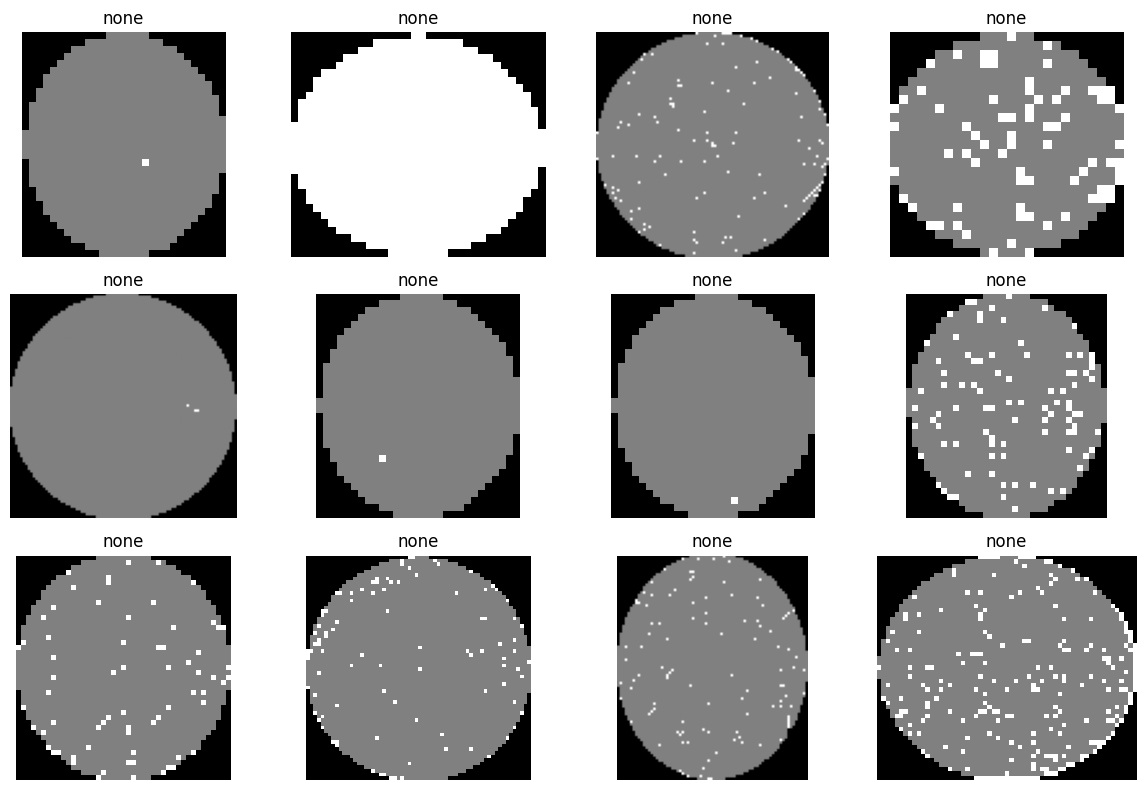

In [6]:
def get_wafer_array(value):
    """
    Convert a wafer-map entry into a NumPy array.
    """

    if isinstance(value, np.ndarray):
        array = value
    else:
        array = np.asarray(value)

    array = np.squeeze(array)

    if array.ndim != 2:
        raise ValueError(
            f"Expected a 2D wafer map, received shape {array.shape}"
        )

    return array.astype(np.float32)
plt.figure(figsize=(12, 8))

sample_indices = np.random.choice(
    len(df),
    size=min(12, len(df)),
    replace=False
)

for plot_index, dataframe_index in enumerate(sample_indices):
    wafer = get_wafer_array(df.iloc[dataframe_index]["waferMap"])
    label = df.iloc[dataframe_index]["label_name"]

    plt.subplot(3, 4, plot_index + 1)
    plt.imshow(wafer, cmap="gray")
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(
    df["label_name"]
)

class_names = list(label_encoder.classes_)
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print(df["label"].value_counts().sort_index())

Classes: ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-full', 'Random', 'Scratch', 'none']
Number of classes: 9
label
0      4294
1       555
2      5189
3      9680
4      3593
5       149
6       866
7      1193
8    785938
Name: count, dtype: int64


In [8]:
all_indices = np.arange(len(df))
all_labels = df["label"].values

train_indices, temporary_indices = train_test_split(
    all_indices,
    test_size=0.30,
    stratify=all_labels,
    random_state=SEED
)

temporary_labels = df.iloc[temporary_indices]["label"].values

validation_indices, test_indices = train_test_split(
    temporary_indices,
    test_size=0.50,
    stratify=temporary_labels,
    random_state=SEED
)

train_df = df.iloc[train_indices].reset_index(drop=True)
validation_df = df.iloc[validation_indices].reset_index(drop=True)
test_df = df.iloc[test_indices].reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(validation_df))
print("Test samples:", len(test_df))


Training samples: 568019
Validation samples: 121719
Test samples: 121719


In [39]:
class WaferMapDataset(Dataset):
      def __init__(
        self,
        dataframe,
        image_size=64
      ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

      def __len__(self):
        return len(self.dataframe)

      def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        wafer = get_wafer_array(row["waferMap"])

        # Normalize wafer values to [0, 1]
        maximum_value = wafer.max()

        if maximum_value > 0:
            wafer = wafer / maximum_value

        wafer = torch.tensor(
            wafer,
            dtype=torch.float32
        )

        # Shape: [1, H, W]
        wafer = wafer.unsqueeze(0)

        # Resize to a fixed image size
        wafer = F.interpolate(
            wafer.unsqueeze(0),
            size=(self.image_size, self.image_size),
            mode="nearest"
        ).squeeze(0)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return wafer, label

In [1]:
IMAGE_SIZE = 64
BATCH_SIZE = 64
NUM_WORKERS = 2

train_dataset = WaferMapDataset(
    train_df,
    image_size=IMAGE_SIZE
)

validation_dataset = WaferMapDataset(
    validation_df,
    image_size=IMAGE_SIZE
)

test_dataset = WaferMapDataset(
    test_df,
    image_size=IMAGE_SIZE
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

TypeError: WaferMapDataset.__init__() got an unexpected keyword argument 'image_size'

In [28]:
# ================================================================
# A4–A8 GEOMETRY-AWARE ViT
# ================================================================

class PatchEmbedding(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=8,
        in_channels=1,
        embed_dim=128
    ):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size

        self.num_patches = (
            image_size // patch_size
        ) ** 2

        self.projection = nn.Conv2d(
            in_channels=in_channels,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):

        x = self.projection(x)

        # [B, E, H_p, W_p]
        x = x.flatten(2)

        # [B, N, E]
        x = x.transpose(1, 2)

        return x


# ================================================================
# GEOMETRY RoPE ATTENTION
# ================================================================

class GeometryRoPEAttention(nn.Module):

    def __init__(
        self,
        embed_dim,
        num_heads,
        geometry="xy",
        dropout=0.1
    ):
        super().__init__()

        assert embed_dim % num_heads == 0

        self.dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.geometry = geometry

        self.qkv = nn.Linear(
            embed_dim,
            embed_dim * 3
        )

        self.proj = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.dropout = nn.Dropout(dropout)

        # ---------------------------------------------------------
        # Learnable geometry coefficients
        # ---------------------------------------------------------

        self.alpha_x = nn.Parameter(
            torch.tensor(1.0)
        )

        self.alpha_y = nn.Parameter(
            torch.tensor(1.0)
        )

        self.alpha_r = nn.Parameter(
            torch.tensor(0.0)
        )

        self.alpha_sin = nn.Parameter(
            torch.tensor(0.0)
        )

        self.alpha_cos = nn.Parameter(
            torch.tensor(0.0)
        )

        # ---------------------------------------------------------
        # A8: Adaptive WRAPA geometry weights
        #
        # 0 -> XY
        # 1 -> Radial
        # 2 -> Angular
        # ---------------------------------------------------------

        if geometry == "wra":

            self.geometry_logits = nn.Parameter(
                torch.zeros(3)
            )

    def forward(self, x):

        B, N, C = x.shape

        # ---------------------------------------------------------
        # Recover patch-grid dimensions
        # ---------------------------------------------------------

        H = int(math.sqrt(N))
        W = H

        if H * W != N:

            raise ValueError(
                f"Number of patch tokens {N} "
                f"is not a perfect square. "
                f"Cannot infer H and W."
            )

        # ---------------------------------------------------------
        # QKV
        # ---------------------------------------------------------

        qkv = self.qkv(x)

        qkv = qkv.reshape(
            B,
            N,
            3,
            self.num_heads,
            self.head_dim
        )

        qkv = qkv.permute(
            2,
            0,
            3,
            1,
            4
        )

        q, k, v = qkv[0], qkv[1], qkv[2]

        # ---------------------------------------------------------
        # Geometry coordinates
        # ---------------------------------------------------------

        device = x.device

        yy, xx = torch.meshgrid(
            torch.linspace(
                -1,
                1,
                H,
                device=device
            ),
            torch.linspace(
                -1,
                1,
                W,
                device=device
            ),
            indexing="ij"
        )

        xx = xx.reshape(-1)
        yy = yy.reshape(-1)

        # ---------------------------------------------------------
        # Radial distance
        # ---------------------------------------------------------

        r = torch.sqrt(
            xx ** 2 + yy ** 2
        )

        # ---------------------------------------------------------
        # Angular information
        # ---------------------------------------------------------

        theta = torch.atan2(
            yy,
            xx
        )

        sin_theta = torch.sin(theta)

        cos_theta = torch.cos(theta)

        # ---------------------------------------------------------
        # Geometry phases
        # ---------------------------------------------------------

        # XY
        phase_xy = (
            self.alpha_x * xx
            +
            self.alpha_y * yy
        )

        # Radial
        phase_radial = (
            self.alpha_r * r
        )

        # Angular
        phase_angular = (
            self.alpha_sin * sin_theta
            +
            self.alpha_cos * cos_theta
        )

        # ---------------------------------------------------------
        # A4
        # ---------------------------------------------------------

        if self.geometry == "xy":

            phase = phase_xy

        # ---------------------------------------------------------
        # A5
        # ---------------------------------------------------------

        elif self.geometry == "radial":

            phase = (
                phase_xy
                +
                phase_radial
            )

        # ---------------------------------------------------------
        # A6
        # ---------------------------------------------------------

        elif self.geometry == "angular":

            phase = (
                phase_xy
                +
                phase_angular
            )

        # ---------------------------------------------------------
        # A7
        # ---------------------------------------------------------

        elif self.geometry == "radial_angular":

            phase = (
                phase_xy
                +
                phase_radial
                +
                phase_angular
            )

        # ---------------------------------------------------------
        # A8 - WRAPA
        # ---------------------------------------------------------

        elif self.geometry == "wra":

            geometry_weights = (
                3.0
                *
                torch.softmax(
                    self.geometry_logits,
                    dim=0
                )
            )

            w_xy = geometry_weights[0]
            w_radial = geometry_weights[1]
            w_angular = geometry_weights[2]

            phase = (
                w_xy * phase_xy
                +
                w_radial * phase_radial
                +
                w_angular * phase_angular
            )

        else:

            raise ValueError(
                f"Unknown geometry type: {self.geometry}"
            )

        # ---------------------------------------------------------
        # RoPE
        # ---------------------------------------------------------

        phase = phase.unsqueeze(0).unsqueeze(0)

        if phase.shape[-1] != N:

            raise ValueError(
                f"Geometry size {phase.shape[-1]} "
                f"does not match token count {N}"
            )

        cos_phase = torch.cos(phase)

        sin_phase = torch.sin(phase)

        # ---------------------------------------------------------
        # Rotate Q and K
        # ---------------------------------------------------------

        def rotate_half(tensor):

            half = tensor.shape[-1] // 2

            x1 = tensor[..., :half]

            x2 = tensor[..., half:]

            return torch.cat(
                [
                    -x2,
                    x1
                ],
                dim=-1
            )

        q = (
            q * cos_phase.unsqueeze(-1)
            +
            rotate_half(q)
            * sin_phase.unsqueeze(-1)
        )

        k = (
            k * cos_phase.unsqueeze(-1)
            +
            rotate_half(k)
            * sin_phase.unsqueeze(-1)
        )

        # ---------------------------------------------------------
        # Attention
        # ---------------------------------------------------------

        attn = (
            q
            @
            k.transpose(-2, -1)
        )

        attn = attn / math.sqrt(
            self.head_dim
        )

        attn = torch.softmax(
            attn,
            dim=-1
        )

        attn = self.dropout(
            attn
        )

        out = attn @ v

        out = out.transpose(
            1,
            2
        ).reshape(
            B,
            N,
            C
        )

        out = self.proj(out)

        return out


# ================================================================
# TRANSFORMER BLOCK
# ================================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        embed_dim=128,
        num_heads=4,
        mlp_ratio=4,
        geometry="xy",
        dropout=0.1
    ):
        super().__init__()

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.attention = GeometryRoPEAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            geometry=geometry,
            dropout=dropout
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        hidden_dim = (
            embed_dim * mlp_ratio
        )

        self.mlp = nn.Sequential(
            nn.Linear(
                embed_dim,
                hidden_dim
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                hidden_dim,
                embed_dim
            ),

            nn.Dropout(dropout)
        )

    def forward(self, x):

        x = x + self.attention(
            self.norm1(x)
        )

        x = x + self.mlp(
            self.norm2(x)
        )

        return x


# ================================================================
# WRAPA ViT
# ================================================================

class WRAPA_ViT(nn.Module):

    def __init__(
        self,
        geometry
    ):
        super().__init__()

        self.geometry = geometry

        self.patch_embed = PatchEmbedding(
            image_size=IMAGE_SIZE,
            patch_size=PATCH_SIZE,
            in_channels=1,
            embed_dim=EMBED_DIM
        )

        self.num_patches = (
            self.patch_embed.num_patches
        )

        # --------------------------------------------------------
        # CLASS TOKEN
        # --------------------------------------------------------

        self.cls_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                EMBED_DIM
            )
        )

        # --------------------------------------------------------
        # Transformer blocks
        # --------------------------------------------------------

        self.blocks = nn.ModuleList([

            TransformerBlock(
                embed_dim=EMBED_DIM,
                num_heads=NUM_HEADS,
                geometry=geometry
            )

            for _ in range(DEPTH)

        ])

        self.norm = nn.LayerNorm(
            EMBED_DIM
        )

        self.head = nn.Linear(
            EMBED_DIM,
            NUM_CLASSES
        )

        nn.init.normal_(
            self.cls_token,
            std=0.02
        )

    def forward(self, x):

        x = self.patch_embed(x)

        B = x.shape[0]

        cls = self.cls_token.expand(
            B,
            -1,
            -1
        )

        x = torch.cat(
            [
                cls,
                x
            ],
            dim=1
        )

        # --------------------------------------------------------
        # Geometry is calculated for PATCH TOKENS only.
        # CLS token is separated.
        # --------------------------------------------------------

        cls_token = x[:, :1, :]

        patches = x[:, 1:, :]

        for block in self.blocks:

            patches = block(
                patches
            )

        # --------------------------------------------------------
        # GLOBAL REPRESENTATION
        # --------------------------------------------------------

        representation = patches.mean(
            dim=1
        )

        representation = self.norm(
            representation
        )

        output = self.head(
            representation
        )

        return output


print("$$$$ A4-A8 MODEL CELL LOADED SUCCESSFULLY $$$$")

$$$$ A4-A8 MODEL CELL LOADED SUCCESSFULLY $$$$


In [12]:
baseline_model = GeometryViT(
    image_size=IMAGE_SIZE,
    patch_size=8,
    num_classes=num_classes,
    use_radial=False,
    use_angular=False
).to(device)

radial_model = GeometryViT(
    image_size=IMAGE_SIZE,
    patch_size=8,
    num_classes=num_classes,
    use_radial=True,
    use_angular=False
).to(device)

angular_model = GeometryViT(
    image_size=IMAGE_SIZE,
    patch_size=8,
    num_classes=num_classes,
    use_radial=False,
    use_angular=True
).to(device)

full_geometry_model = GeometryViT(
    image_size=IMAGE_SIZE,
    patch_size=8,
    num_classes=num_classes,
    use_radial=True,
    use_angular=True
).to(device)

test_batch = images.to(device)

for name, model in {
    "baseline": baseline_model,
    "radial": radial_model,
    "angular": angular_model,
    "full_geometry": full_geometry_model
}.items():

    with torch.no_grad():
        output = model(test_batch)

    print(name, output.shape)

baseline torch.Size([64, 9])
radial torch.Size([64, 9])
angular torch.Size([64, 9])
full_geometry torch.Size([64, 9])


In [ ]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device
):
    model.train()

    total_loss = 0.0
    all_true = []
    all_pred = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_true.extend(labels.detach().cpu().numpy())
        all_pred.extend(predictions.detach().cpu().numpy())

    average_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(
        all_true,
        all_pred
    )

    macro_f1 = f1_score(
        all_true,
        all_pred,
        average="macro",
        zero_division=0
    )

    return average_loss, accuracy, macro_f1
def evaluate_model(
    model,
    loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0.0
    all_true = []
    all_pred = []

    with torch.no_grad():

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            all_true.extend(
                labels.cpu().numpy()
            )

            all_pred.extend(
                predictions.cpu().numpy()
            )

    average_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(
        all_true,
        all_pred
    )

    macro_f1 = f1_score(
        all_true,
        all_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        all_true,
        all_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "y_true": np.asarray(all_true),
        "y_pred": np.asarray(all_pred)
    }


In [ ]:
def train_model(
    model,
    train_loader,
    validation_loader,
    device,
    epochs=10,
    learning_rate=1e-4,
    weight_decay=1e-4
):
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    best_macro_f1 = -1.0
    best_state = None
    history = []

    for epoch in range(1, epochs + 1):

        start_time = time.time()

        train_loss, train_accuracy, train_macro_f1 = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            device=device
        )

        validation_results = evaluate_model(
            model=model,
            loader=validation_loader,
            criterion=criterion,
            device=device
        )

        scheduler.step()

        if validation_results["macro_f1"] > best_macro_f1:
            best_macro_f1 = validation_results["macro_f1"]
            best_state = copy.deepcopy(
                model.state_dict()
            )

        elapsed = time.time() - start_time

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "train_macro_f1": train_macro_f1,
            "validation_loss": validation_results["loss"],
            "validation_accuracy": validation_results["accuracy"],
            "validation_macro_f1": validation_results["macro_f1"],
            "validation_weighted_f1": validation_results["weighted_f1"]
        })

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {validation_results['accuracy']:.4f} | "
            f"Val Macro-F1: {validation_results['macro_f1']:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history

In [15]:
set_seed(42)

baseline_model = GeometryViT(
    image_size=IMAGE_SIZE,
    patch_size=8,
    num_classes=num_classes,
    embed_dim=128,
    depth=4,
    num_heads=4,
    use_radial=False,
    use_angular=False
).to(device)

baseline_model, baseline_history = train_model(
    model=baseline_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    device=device,
    epochs=10,
    learning_rate=1e-4
)

Epoch 01/10 | Train Acc: 0.9745 | Val Acc: 0.9765 | Val Macro-F1: 0.4005 | Time: 223.8s
Epoch 02/10 | Train Acc: 0.9767 | Val Acc: 0.9770 | Val Macro-F1: 0.3837 | Time: 223.8s
Epoch 03/10 | Train Acc: 0.9778 | Val Acc: 0.9780 | Val Macro-F1: 0.4051 | Time: 223.7s
Epoch 04/10 | Train Acc: 0.9786 | Val Acc: 0.9789 | Val Macro-F1: 0.4903 | Time: 223.1s
Epoch 05/10 | Train Acc: 0.9794 | Val Acc: 0.9780 | Val Macro-F1: 0.5551 | Time: 222.3s
Epoch 06/10 | Train Acc: 0.9800 | Val Acc: 0.9792 | Val Macro-F1: 0.5465 | Time: 222.3s
Epoch 07/10 | Train Acc: 0.9807 | Val Acc: 0.9795 | Val Macro-F1: 0.5760 | Time: 221.2s
Epoch 08/10 | Train Acc: 0.9815 | Val Acc: 0.9801 | Val Macro-F1: 0.5958 | Time: 221.3s
Epoch 09/10 | Train Acc: 0.9821 | Val Acc: 0.9798 | Val Macro-F1: 0.6049 | Time: 223.6s
Epoch 10/10 | Train Acc: 0.9824 | Val Acc: 0.9801 | Val Macro-F1: 0.6004 | Time: 221.6s


In [16]:
criterion = nn.CrossEntropyLoss()

baseline_results = evaluate_model(
    model=baseline_model,
    loader=test_loader,
    criterion=criterion,
    device=device
)

print("Baseline accuracy:", baseline_results["accuracy"])
print("Baseline macro-F1:", baseline_results["macro_f1"])
print("Baseline weighted-F1:", baseline_results["weighted_f1"])

print(
    classification_report(
        baseline_results["y_true"],
        baseline_results["y_pred"],
        target_names=class_names,
        zero_division=0
    )
)

Baseline accuracy: 0.9797648682621448
Baseline macro-F1: 0.5850602179407469
Baseline weighted-F1: 0.9784687248779386
              precision    recall  f1-score   support

      Center       0.53      0.60      0.56       644
       Donut       0.63      0.58      0.60        83
    Edge-Loc       0.65      0.48      0.55       779
   Edge-Ring       0.83      0.81      0.82      1452
         Loc       0.57      0.39      0.46       539
   Near-full       0.65      0.59      0.62        22
      Random       0.64      0.62      0.63       130
     Scratch       0.29      0.01      0.02       179
        none       0.99      0.99      0.99    117891

    accuracy                           0.98    121719
   macro avg       0.64      0.56      0.59    121719
weighted avg       0.98      0.98      0.98    121719



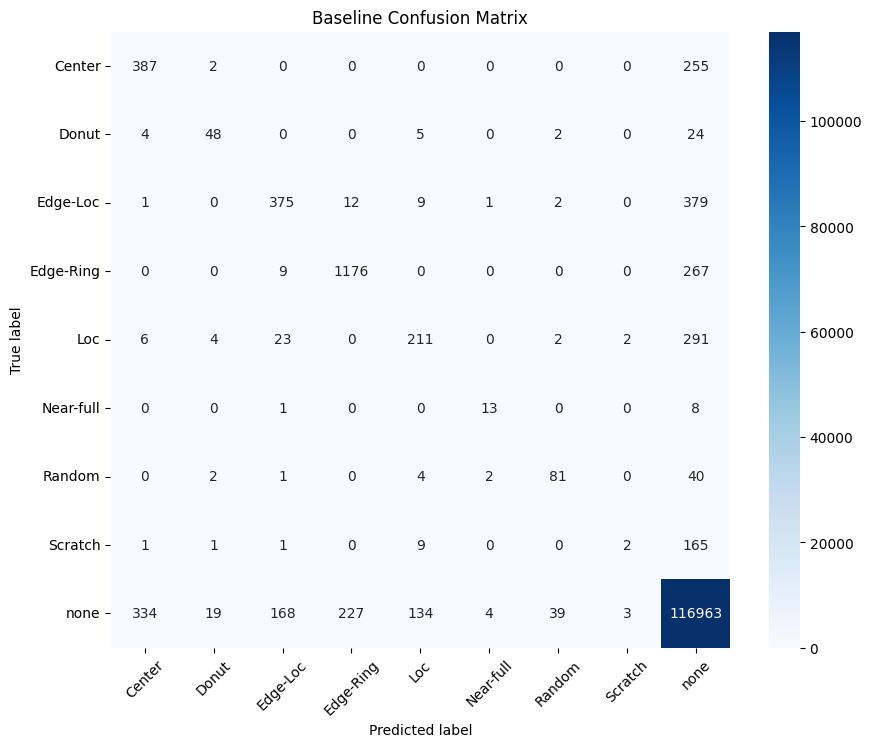

In [17]:
cm = confusion_matrix(
    baseline_results["y_true"],
    baseline_results["y_pred"]
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Baseline Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()



In [ ]:

experiment_configs = [
    {
        "name": "baseline",
        "use_radial": False,
        "use_angular": False
    },
    {
        "name": "radial_only",
        "use_radial": True,
        "use_angular": False
    },
    {
        "name": "angular_only",
        "use_radial": False,
        "use_angular": True
    },
    {
        "name": "radial_angular",
        "use_radial": True,
        "use_angular": True
    }
]

all_results = []

for config in experiment_configs:

    print("\n==============================")
    print("Running:", config["name"])
    print("==============================")

    set_seed(42)

    model = GeometryViT(
        image_size=IMAGE_SIZE,
        patch_size=8,
        num_classes=num_classes,
        embed_dim=128,
        depth=4,
        num_heads=4,
        use_radial=config["use_radial"],
        use_angular=config["use_angular"]
    ).to(device)

    model, history = train_model(
        model=model,
        train_loader=train_loader,
        validation_loader=validation_loader,
        device=device,
        epochs=10,
        learning_rate=1e-4
    )

    results = evaluate_model(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=device
    )

    experiment_result = {
        "model": config["name"],
        "radial": config["use_radial"],
        "angular": config["use_angular"],
        "accuracy": float(results["accuracy"]),
        "macro_f1": float(results["macro_f1"]),
        "weighted_f1": float(results["weighted_f1"])
    }

    all_results.append(experiment_result)

    print(json.dumps(experiment_result, indent=2))

In [19]:
results_df = pd.DataFrame(all_results)

display(
    results_df.sort_values(
        by="macro_f1",
        ascending=False
    )
)

,model,radial,angular,accuracy,macro_f1,weighted_f1
0,baseline,False,False,0.979765,0.585060,0.978469
1,radial_only,True,False,0.979379,0.572283,0.978057
3,radial_angular,True,True,0.980217,0.566089,0.978442
2,angular_only,False,True,0.979921,0.563814,0.978048


In [20]:
os.makedirs("results", exist_ok=True)

results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

with open(
    "results/model_comparison.json",
    "w"
) as file:
    json.dump(
        all_results,
        file,
        indent=2
    )

print("Results saved to the results directory.")

Results saved to the results directory.


In [22]:
def run_experiment(
    config,
    seed,
    epochs=10
):
    set_seed(seed)

    model = GeometryViT(
        image_size=IMAGE_SIZE,
        patch_size=8,
        num_classes=num_classes,
        embed_dim=128,
        depth=4,
        num_heads=4,
        use_radial=config["use_radial"],
        use_angular=config["use_angular"]
    ).to(device)

    model, history = train_model(
        model=model,
        train_loader=train_loader,
        validation_loader=validation_loader,
        device=device,
        epochs=epochs,
        learning_rate=1e-4
    )

    results = evaluate_model(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=device
    )

    return {
        "model": config["name"],
        "seed": seed,
        "accuracy": float(results["accuracy"]),
        "macro_f1": float(results["macro_f1"]),
        "weighted_f1": float(results["weighted_f1"])
    }
SEEDS = [42, 123, 2024]
multi_seed_results = []

for config in experiment_configs:

    for seed in SEEDS:

        print(
            f"\nModel: {config['name']} | Seed: {seed}"
        )

        result = run_experiment(
            config=config,
            seed=seed,
            epochs=10
        )

        multi_seed_results.append(result)

multi_seed_df = pd.DataFrame(multi_seed_results)

display(multi_seed_df)


Model: baseline | Seed: 42
Epoch 01/10 | Train Acc: 0.9745 | Val Acc: 0.9765 | Val Macro-F1: 0.4005 | Time: 220.7s
Epoch 02/10 | Train Acc: 0.9767 | Val Acc: 0.9770 | Val Macro-F1: 0.3837 | Time: 218.2s
Epoch 03/10 | Train Acc: 0.9778 | Val Acc: 0.9780 | Val Macro-F1: 0.4051 | Time: 217.8s
Epoch 04/10 | Train Acc: 0.9786 | Val Acc: 0.9789 | Val Macro-F1: 0.4903 | Time: 218.2s
Epoch 05/10 | Train Acc: 0.9794 | Val Acc: 0.9780 | Val Macro-F1: 0.5551 | Time: 219.3s
Epoch 06/10 | Train Acc: 0.9800 | Val Acc: 0.9792 | Val Macro-F1: 0.5465 | Time: 217.0s
Epoch 07/10 | Train Acc: 0.9807 | Val Acc: 0.9795 | Val Macro-F1: 0.5760 | Time: 217.9s
Epoch 08/10 | Train Acc: 0.9815 | Val Acc: 0.9801 | Val Macro-F1: 0.5958 | Time: 218.2s
Epoch 09/10 | Train Acc: 0.9821 | Val Acc: 0.9798 | Val Macro-F1: 0.6049 | Time: 217.4s
Epoch 10/10 | Train Acc: 0.9824 | Val Acc: 0.9801 | Val Macro-F1: 0.6004 | Time: 217.8s

Model: baseline | Seed: 123
Epoch 01/10 | Train Acc: 0.9742 | Val Acc: 0.9767 | Val Macro-F

,model,seed,accuracy,macro_f1,weighted_f1
0,baseline,42,0.979765,0.585060,0.978469
1,baseline,123,0.980200,0.585740,0.978536
2,baseline,2024,0.979067,0.594612,0.978133
3,radial_only,42,0.979379,0.572283,0.978057
4,radial_only,123,0.980282,0.582766,0.978539
5,radial_only,2024,0.980102,0.570997,0.978403
6,angular_only,42,0.979921,0.563814,0.978048
7,angular_only,123,0.979773,0.572909,0.977948
8,angular_only,2024,0.979732,0.560981,0.977928
9,radial_angular,42,0.980217,0.566089,0.978442


In [23]:
summary_df = (
    multi_seed_df
    .groupby("model")
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        weighted_f1_mean=("weighted_f1", "mean"),
        weighted_f1_std=("weighted_f1", "std")
    )
    .reset_index()
)

display(summary_df)

,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std
0,angular_only,0.979809,0.000099,0.565901,0.006232,0.977975,0.000065
1,baseline,0.979677,0.000572,0.588471,0.005330,0.978379,0.000216
2,radial_angular,0.980228,0.000140,0.569825,0.006011,0.978519,0.000264
3,radial_only,0.979921,0.000478,0.575348,0.006456,0.978333,0.000249


In [24]:
multi_seed_df.to_csv(
    "results/multi_seed_results.csv",
    index=False
)

summary_df.to_csv(
    "results/multi_seed_summary.csv",
    index=False
)

with open(
    "results/multi_seed_results.json",
    "w"
) as file:
    json.dump(
        multi_seed_results,
        file,
        indent=2
    )

print("Multi-seed results saved.")

Multi-seed results saved.


In [1]:
# ============================================================
# WAFER DEFECT RECOGNITION
# INDEPENDENT WRAPA-ViT IMPLEMENTATION
#
# Wafer-Specific Radial-Angular Positional Attention
#
# Dataset: WM-811K
# Input: 64 x 64
# Patch: 8 x 8
# Embedding: 128
# Transformer depth: 4
# Heads: 4
# ============================================================

# ============================================================
# 1. INSTALL / IMPORT
# ============================================================

!pip -q install kagglehub scikit-learn

import os
import math
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)


# ============================================================
# 3. DOWNLOAD WM-811K
# ============================================================

import kagglehub

dataset_path = kagglehub.dataset_download(
    "qingyi/wm811k-wafer-map"
)

print("Dataset path:")
print(dataset_path)


# ============================================================
# 4. LOCATE LSWMD.pkl
# ============================================================

pkl_file = None

for root, dirs, files in os.walk(dataset_path):

    for file in files:

        if file.lower() == "lswmd.pkl":

            pkl_file = os.path.join(
                root,
                file
            )

            break

    if pkl_file is not None:
        break


if pkl_file is None:

    raise FileNotFoundError(
        "LSWMD.pkl was not found."
    )

print("Using:")
print(pkl_file)


# ============================================================
# 5. LOAD DATA
# ============================================================

df = pd.read_pickle(pkl_file)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst rows:")
display(df.head())


# ============================================================
# 6. LABEL EXTRACTION
# ============================================================

def unwrap_value(x):

    if isinstance(x, np.ndarray):

        if x.size == 1:
            return x.item()

        return x

    if isinstance(x, list):

        if len(x) == 1:
            return x[0]

    return x


def convert_label(x):

    x = unwrap_value(x)

    if isinstance(x, np.ndarray):

        if x.size == 1:
            x = x.item()

    if isinstance(x, (list, tuple)):

        if len(x) == 1:
            x = x[0]

    return str(x)


# ------------------------------------------------------------
# Find label column
# ------------------------------------------------------------

possible_label_columns = [
    "failureType",
    "failure_type",
    "label",
    "Label"
]

label_column = None

for col in possible_label_columns:

    if col in df.columns:

        label_column = col
        break


if label_column is None:

    raise ValueError(
        "Could not find failureType/label column."
    )


df["class_name"] = df[label_column].apply(
    convert_label
)

print("\nClass distribution:")
print(df["class_name"].value_counts())


# ============================================================
# 7. KEEP ONLY SINGLE-LABEL DEFECT CLASSES
# ============================================================

valid_classes = [
    "none",
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

df = df[
    df["class_name"].isin(valid_classes)
].copy()

df = df.reset_index(drop=True)

print("\nFiltered dataset:")
print(df.shape)

print("\nClasses:")
print(
    df["class_name"].value_counts()
)


# ============================================================
# 8. LABEL ENCODING
# ============================================================

class_names = [
    "none",
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

class_to_idx = {
    name: idx
    for idx, name in enumerate(class_names)
}

idx_to_class = {
    idx: name
    for name, idx in class_to_idx.items()
}

df["label"] = df["class_name"].map(
    class_to_idx
)

print("\nEncoded classes:")
print(class_to_idx)


# ============================================================
# 9. FIND WAFER MAP COLUMN
# ============================================================

possible_map_columns = [
    "waferMap",
    "wafer_map",
    "map"
]

map_column = None

for col in possible_map_columns:

    if col in df.columns:

        map_column = col
        break


if map_column is None:

    raise ValueError(
        "Could not find waferMap column."
    )

print("\nWafer-map column:", map_column)


# ============================================================
# 10. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

indices = np.arange(len(df))

labels = df["label"].values

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

temp_labels = labels[temp_idx]

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

train_df = df.iloc[train_idx].reset_index(drop=True)

val_df = df.iloc[val_idx].reset_index(drop=True)

test_df = df.iloc[test_idx].reset_index(drop=True)

print("\nSplit sizes:")

print(
    "Train:",
    len(train_df)
)

print(
    "Validation:",
    len(val_df)
)

print(
    "Test:",
    len(test_df)
)


# ============================================================
# 11. DATASET CLASS
# ============================================================

class WaferMapDataset(Dataset):

    def __init__(
        self,
        dataframe,
        map_column="waferMap",
        image_size=64
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.map_column = map_column

        self.image_size = image_size

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        wafer = row[self.map_column]

        wafer = np.asarray(
            wafer,
            dtype=np.float32
        )

        # ----------------------------------------------------
        # Normalize wafer map
        # ----------------------------------------------------

        max_value = wafer.max()

        if max_value > 0:

            wafer = wafer / max_value

        # ----------------------------------------------------
        # Convert to tensor
        # ----------------------------------------------------

        wafer = torch.tensor(
            wafer,
            dtype=torch.float32
        )

        # Add channel dimension
        wafer = wafer.unsqueeze(0)

        # ----------------------------------------------------
        # Resize
        # ----------------------------------------------------

        wafer = F.interpolate(
            wafer.unsqueeze(0),
            size=(
                self.image_size,
                self.image_size
            ),
            mode="nearest"
        ).squeeze(0)

        label = int(row["label"])

        return wafer, label


# ============================================================
# 12. CREATE DATA LOADERS
# ============================================================

IMAGE_SIZE = 64

BATCH_SIZE = 64

train_dataset = WaferMapDataset(
    train_df,
    map_column=map_column,
    image_size=IMAGE_SIZE
)

val_dataset = WaferMapDataset(
    val_df,
    map_column=map_column,
    image_size=IMAGE_SIZE
)

test_dataset = WaferMapDataset(
    test_df,
    map_column=map_column,
    image_size=IMAGE_SIZE
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# 13. CHECK INPUT
# ============================================================

images, labels_batch = next(
    iter(train_loader)
)

print("\nImage batch:")
print(images.shape)

print("Labels:")
print(labels_batch.shape)


# ============================================================
# 14. PATCH EMBEDDING
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=8,
        in_channels=1,
        embed_dim=128
    ):

        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size

        self.patch_size = patch_size

        self.grid_size = (
            image_size // patch_size
        )

        self.num_patches = (
            self.grid_size *
            self.grid_size
        )

        self.projection = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):

        x = self.projection(x)

        # [B, E, H, W]
        # →
        # [B, H*W, E]

        x = x.flatten(2)

        x = x.transpose(1, 2)

        return x


# ============================================================
# 15. WRAPA ATTENTION
# ============================================================

class WRAPA_Attention(nn.Module):

    """
    Wafer-Specific Radial-Angular Positional Attention.

    Geometry:
        x
        y
        r
        sin(theta)
        cos(theta)

    The geometry controls the rotary phase applied
    directly to Q and K.
    """

    def __init__(
        self,
        embed_dim=128,
        num_heads=4,
        grid_size=8,
        dropout=0.1
    ):

        super().__init__()

        assert embed_dim % num_heads == 0

        self.embed_dim = embed_dim

        self.num_heads = num_heads

        self.head_dim = (
            embed_dim // num_heads
        )

        self.grid_size = grid_size

        # ----------------------------------------------------
        # QKV
        # ----------------------------------------------------

        self.qkv = nn.Linear(
            embed_dim,
            embed_dim * 3
        )

        self.out_proj = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.dropout = nn.Dropout(
            dropout
        )

        # ----------------------------------------------------
        # Learnable geometry coefficients
        # ----------------------------------------------------

        self.alpha_x = nn.Parameter(
            torch.tensor(1.0)
        )

        self.alpha_y = nn.Parameter(
            torch.tensor(1.0)
        )

        self.alpha_r = nn.Parameter(
            torch.tensor(0.0)
        )

        self.alpha_sin = nn.Parameter(
            torch.tensor(0.0)
        )

        self.alpha_cos = nn.Parameter(
            torch.tensor(0.0)
        )

    # --------------------------------------------------------
    # Geometry
    # --------------------------------------------------------

    def create_geometry(
        self,
        device,
        dtype
    ):

        g = self.grid_size

        rows = torch.arange(
            g,
            device=device,
            dtype=dtype
        )

        cols = torch.arange(
            g,
            device=device,
            dtype=dtype
        )

        yy, xx = torch.meshgrid(
            rows,
            cols,
            indexing="ij"
        )

        x = xx.reshape(-1)

        y = yy.reshape(-1)

        # ----------------------------------------------------
        # Center coordinates
        # ----------------------------------------------------

        center = (
            g - 1
        ) / 2.0

        x = (
            x - center
        ) / center

        y = (
            y - center
        ) / center

        # ----------------------------------------------------
        # Radial coordinate
        # ----------------------------------------------------

        r = torch.sqrt(
            x ** 2 +
            y ** 2 +
            1e-8
        )

        r = r / math.sqrt(2.0)

        # ----------------------------------------------------
        # Angular coordinate
        # ----------------------------------------------------

        theta = torch.atan2(
            y,
            x
        )

        sin_theta = torch.sin(
            theta
        )

        cos_theta = torch.cos(
            theta
        )

        return (
            x,
            y,
            r,
            sin_theta,
            cos_theta
        )

    # --------------------------------------------------------
    # Rotary transformation
    # --------------------------------------------------------

    def apply_rotary(
        self,
        q,
        k,
        phase
    ):

        D = q.shape[-1]

        half = D // 2

        if half == 0:

            return q, k

        # ----------------------------------------------------
        # Rotary frequencies
        # ----------------------------------------------------

        freq = torch.arange(
            half,
            device=q.device,
            dtype=q.dtype
        )

        freq = 1.0 / (
            10000 **
            (
                freq /
                max(half, 1)
            )
        )

        angles = (
            phase *
            freq.view(1, 1, -1)
        )

        sin = torch.sin(
            angles
        )

        cos = torch.cos(
            angles
        )

        # ----------------------------------------------------
        # Q
        # ----------------------------------------------------

        q1 = q[..., :half]

        q2 = q[..., half:2*half]

        q_rot_1 = (
            q1 * cos -
            q2 * sin
        )

        q_rot_2 = (
            q1 * sin +
            q2 * cos
        )

        q_rot = torch.cat(
            [
                q_rot_1,
                q_rot_2,
                q[..., 2*half:]
            ],
            dim=-1
        )

        # ----------------------------------------------------
        # K
        # ----------------------------------------------------

        k1 = k[..., :half]

        k2 = k[..., half:2*half]

        k_rot_1 = (
            k1 * cos -
            k2 * sin
        )

        k_rot_2 = (
            k1 * sin +
            k2 * cos
        )

        k_rot = torch.cat(
            [
                k_rot_1,
                k_rot_2,
                k[..., 2*half:]
            ],
            dim=-1
        )

        return q_rot, k_rot

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------

    def forward(
        self,
        x,
        return_attention=False
    ):

        B, N, E = x.shape

        # ----------------------------------------------------
        # QKV
        # ----------------------------------------------------

        qkv = self.qkv(x)

        qkv = qkv.reshape(
            B,
            N,
            3,
            self.num_heads,
            self.head_dim
        )

        qkv = qkv.permute(
            2,
            0,
            3,
            1,
            4
        )

        q = qkv[0]

        k = qkv[1]

        v = qkv[2]

        # ----------------------------------------------------
        # Geometry
        # ----------------------------------------------------

        geometry = self.create_geometry(
            device=x.device,
            dtype=x.dtype
        )

        x_coord = geometry[0]
        y_coord = geometry[1]
        radial = geometry[2]
        sin_theta = geometry[3]
        cos_theta = geometry[4]

        # ----------------------------------------------------
        # CLS token
        #
        # Token 0 is CLS.
        # Remaining N-1 tokens are wafer patches.
        # ----------------------------------------------------

        patch_count = N - 1

        if patch_count == len(x_coord):

            zero = torch.zeros(
                1,
                device=x.device,
                dtype=x.dtype
            )

            x_coord = torch.cat(
                [zero, x_coord]
            )

            y_coord = torch.cat(
                [zero, y_coord]
            )

            radial = torch.cat(
                [zero, radial]
            )

            sin_theta = torch.cat(
                [zero, sin_theta]
            )

            cos_theta = torch.cat(
                [zero, cos_theta]
            )

        else:

            raise ValueError(
                f"Expected {len(x_coord)} patch tokens "
                f"but received {patch_count}"
            )

        # ----------------------------------------------------
        # Geometry-aware phase
        # ----------------------------------------------------

        phase = (

            self.alpha_x *
            x_coord

            +

            self.alpha_y *
            y_coord

            +

            self.alpha_r *
            radial

            +

            self.alpha_sin *
            sin_theta

            +

            self.alpha_cos *
            cos_theta

        )

        phase = phase.view(
            1,
            N,
            1
        )

        # ----------------------------------------------------
        # Apply radial-angular rotary transformation
        # ----------------------------------------------------

        q, k = self.apply_rotary(
            q,
            k,
            phase
        )

        # ----------------------------------------------------
        # Attention
        # ----------------------------------------------------

        scores = torch.matmul(
            q,
            k.transpose(-2, -1)
        )

        scores = (
            scores /
            math.sqrt(self.head_dim)
        )

        attention = torch.softmax(
            scores,
            dim=-1
        )

        attention = self.dropout(
            attention
        )

        # ----------------------------------------------------
        # Weighted values
        # ----------------------------------------------------

        output = torch.matmul(
            attention,
            v
        )

        output = output.transpose(
            1,
            2
        )

        output = output.contiguous()

        output = output.reshape(
            B,
            N,
            E
        )

        output = self.out_proj(
            output
        )

        if return_attention:

            return output, attention

        return output

print("done")
# ============================================================
# 16. TRANSFORMER BLOCK
# ============================================================

class WRAPA_Block(nn.Module):

    def __init__(
        self,
        embed_dim=128,
        num_heads=4,
        grid_size=8,
        mlp_ratio=4,
        dropout=0.1
    ):

        super().__init__()

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.attention = WRAPA_Attention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            grid_size=grid_size,
            dropout=dropout
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        hidden_dim = (
            embed_dim *
            mlp_ratio
        )

        self.mlp = nn.Sequential(

            nn.Linear(
                embed_dim,
                hidden_dim
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden_dim,
                embed_dim
            ),

            nn.Dropout(
                dropout
            )
        )

    def forward(
        self,
        x,
        return_attention=False
    ):

        if return_attention:

            attn_output, attention = (
                self.attention(
                    self.norm1(x),
                    return_attention=True
                )
            )

        else:

            attn_output = self.attention(
                self.norm1(x)
            )

        x = x + attn_output

        x = (
            x +
            self.mlp(
                self.norm2(x)
            )
        )

        if return_attention:

            return x, attention

        return x


# ============================================================
# 17. WRAPA VISION TRANSFORMER
# ============================================================

class WRAPA_ViT(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=8,
        embed_dim=128,
        depth=4,
        num_heads=4,
        num_classes=9,
        dropout=0.1
    ):

        super().__init__()

        self.patch_embedding = PatchEmbedding(
            image_size=image_size,
            patch_size=patch_size,
            in_channels=1,
            embed_dim=embed_dim
        )

        num_patches = (
            self.patch_embedding.num_patches
        )

        self.class_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                embed_dim
            )
        )

        self.position_embedding = nn.Parameter(
            torch.zeros(
                1,
                num_patches + 1,
                embed_dim
            )
        )

        nn.init.trunc_normal_(
            self.class_token,
            std=0.02
        )

        nn.init.trunc_normal_(
            self.position_embedding,
            std=0.02
        )

        grid_size = (
            image_size //
            patch_size
        )

        self.blocks = nn.ModuleList(

            [
                WRAPA_Block(
                    embed_dim=embed_dim,
                    num_heads=num_heads,
                    grid_size=grid_size,
                    mlp_ratio=4,
                    dropout=dropout
                )

                for _ in range(depth)
            ]
        )

        self.norm = nn.LayerNorm(
            embed_dim
        )

        self.classifier = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(
        self,
        x,
        return_attention=False
    ):

        # Patch embedding
        x = self.patch_embedding(x)

        B = x.shape[0]

        # CLS token
        cls = self.class_token.expand(
            B,
            -1,
            -1
        )

        x = torch.cat(
            [
                cls,
                x
            ],
            dim=1
        )

        # Learned position embedding
        x = (
            x +
            self.position_embedding
        )

        attention_maps = []

        for block in self.blocks:

            if return_attention:

                x, attention = block(
                    x,
                    return_attention=True
                )

                attention_maps.append(
                    attention
                )

            else:

                x = block(x)

        x = self.norm(x)

        # CLS classification
        x = x[:, 0]

        logits = self.classifier(x)

        if return_attention:

            return logits, attention_maps

        return logits


# ============================================================
# 18. CREATE MODEL
# ============================================================

model = WRAPA_ViT(
    image_size=64,
    patch_size=8,
    embed_dim=128,
    depth=4,
    num_heads=4,
    num_classes=9,
    dropout=0.1
).to(device)


# ============================================================
# 19. PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nModel parameters:")
print(
    f"Total: {total_params:,}"
)

print(
    f"Trainable: {trainable_params:,}"
)


# ============================================================
# 20. FORWARD-PASS SANITY TEST
# ============================================================

sample_images, sample_labels = next(
    iter(train_loader)
)

sample_images = sample_images.to(device)

with torch.no_grad():

    sample_output = model(
        sample_images
    )

print("\nForward-pass test:")
print(
    "Input:",
    sample_images.shape
)

print(
    "Output:",
    sample_output.shape
)

assert sample_output.shape == (
    sample_images.shape[0],
    9
)

print(
    "PASS: model forward pass works."
)


# ============================================================
# 21. CLASS WEIGHTS
# ============================================================

train_labels = train_df["label"].values

class_counts = np.bincount(
    train_labels,
    minlength=9
)

print("\nTraining class counts:")

for i, count in enumerate(class_counts):

    print(
        f"{idx_to_class[i]:12s}: {count}"
    )


# Inverse-frequency weights
class_weights = (
    len(train_labels)
    /
    (
        9 *
        np.maximum(
            class_counts,
            1
        )
    )
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("\nClass weights:")
print(class_weights)


# ============================================================
# 22. LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)


# ============================================================
# 23. TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    total_loss = 0.0

    predictions = []

    targets = []

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += (
            loss.item() *
            images.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        predictions.extend(
            preds.detach()
            .cpu()
            .numpy()
        )

        targets.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

    avg_loss = (
        total_loss /
        len(loader.dataset)
    )

    accuracy = accuracy_score(
        targets,
        predictions
    )

    macro_f1 = f1_score(
        targets,
        predictions,
        average="macro",
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        macro_f1
    )


# ============================================================
# 24. EVALUATION FUNCTION
# ============================================================

def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0.0

    predictions = []

    targets = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            total_loss += (
                loss.item() *
                images.size(0)
            )

            preds = torch.argmax(
                logits,
                dim=1
            )

            predictions.extend(
                preds.cpu().numpy()
            )

            targets.extend(
                labels.cpu().numpy()
            )

    avg_loss = (
        total_loss /
        len(loader.dataset)
    )

    accuracy = accuracy_score(
        targets,
        predictions
    )

    macro_f1 = f1_score(
        targets,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        targets,
        predictions,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        targets,
        predictions
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "balanced_accuracy": balanced_acc,
        "targets": np.array(targets),
        "predictions": np.array(predictions)
    }


# ============================================================
# 25. TRAIN
# ============================================================

EPOCHS = 10

best_macro_f1 = -1

best_state = None

history = []

print("\n")
print("=" * 70)
print("TRAINING WRAPA-ViT")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):

    train_loss, train_acc, train_f1 = (
        train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )
    )

    val_results = evaluate(
        model,
        val_loader,
        criterion
    )

    scheduler.step()

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train Macro-F1: {train_f1:.4f} | "
        f"Val Acc: {val_results['accuracy']:.4f} | "
        f"Val Macro-F1: {val_results['macro_f1']:.4f}"
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_accuracy": val_results["accuracy"],
        "val_macro_f1": val_results["macro_f1"]
    })

    # --------------------------------------------------------
    # Save best model based on Macro-F1
    # --------------------------------------------------------

    if (
        val_results["macro_f1"]
        >
        best_macro_f1
    ):

        best_macro_f1 = (
            val_results["macro_f1"]
        )

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }


# ============================================================
# 26. RESTORE BEST MODEL
# ============================================================

model.load_state_dict(
    best_state
)

model = model.to(device)

print("\nBest validation Macro-F1:")
print(
    f"{best_macro_f1:.4f}"
)


# ============================================================
# 27. FINAL TEST
# ============================================================

test_results = evaluate(
    model,
    test_loader,
    criterion
)

print("\n")
print("=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

print(
    f"Accuracy           : "
    f"{test_results['accuracy']:.4f}"
)

print(
    f"Macro-F1           : "
    f"{test_results['macro_f1']:.4f}"
)

print(
    f"Weighted-F1        : "
    f"{test_results['weighted_f1']:.4f}"
)

print(
    f"Balanced Accuracy  : "
    f"{test_results['balanced_accuracy']:.4f}"
)


# ============================================================
# 28. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:\n")

print(
    classification_report(
        test_results["targets"],
        test_results["predictions"],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 29. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_results["targets"],
    test_results["predictions"],
    labels=np.arange(9)
)

plt.figure(
    figsize=(10, 8)
)

plt.imshow(cm)

plt.title(
    "WRAPA-ViT Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.xticks(
    np.arange(9),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(9),
    class_names
)

for i in range(9):

    for j in range(9):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()

plt.show()


# ============================================================
# 30. TRAINING CURVES
# ============================================================

history_df = pd.DataFrame(
    history
)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")

plt.ylabel("Score")

plt.title(
    "WRAPA-ViT Validation Performance"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 31. LEARNED GEOMETRY WEIGHTS
# ============================================================

attention_layer = (
    model.blocks[0].attention
)

print("\n")
print("=" * 70)
print("LEARNED GEOMETRY COEFFICIENTS")
print("=" * 70)

print(
    "alpha_x   =",
    attention_layer.alpha_x.item()
)

print(
    "alpha_y   =",
    attention_layer.alpha_y.item()
)

print(
    "alpha_r   =",
    attention_layer.alpha_r.item()
)

print(
    "alpha_sin =",
    attention_layer.alpha_sin.item()
)

print(
    "alpha_cos =",
    attention_layer.alpha_cos.item()
)


# ============================================================
# 32. ATTENTION VISUALIZATION
# ============================================================

model.eval()

sample_images, sample_labels = next(
    iter(test_loader)
)

sample_images = sample_images[
    :1
].to(device)

with torch.no_grad():

    logits, attention_maps = model(
        sample_images,
        return_attention=True
    )

prediction = torch.argmax(
    logits,
    dim=1
).item()

print(
    "True class:",
    class_names[
        sample_labels[0].item()
    ]
)

print(
    "Predicted class:",
    class_names[prediction]
)

# Last Transformer layer
last_attention = attention_maps[-1]

# First head
attention_map = (
    last_attention[0, 0]
    .detach()
    .cpu()
    .numpy()
)

# CLS attention to patches
cls_attention = attention_map[
    0,
    1:
]

cls_attention = cls_attention.reshape(
    8,
    8
)

plt.figure(
    figsize=(6, 6)
)

plt.imshow(
    cls_attention
)

plt.title(
    "WRAPA-ViT CLS Attention to Wafer Patches"
)

plt.colorbar()

plt.tight_layout()

plt.show()


# ============================================================
# 33. SAVE RESULTS
# ============================================================

results = {
    "model": "WRAPA-ViT",
    "dataset": "WM-811K",
    "image_size": IMAGE_SIZE,
    "patch_size": 8,
    "embedding_dim": 128,
    "depth": 4,
    "heads": 4,
    "test_accuracy": test_results["accuracy"],
    "test_macro_f1": test_results["macro_f1"],
    "test_weighted_f1": test_results["weighted_f1"],
    "test_balanced_accuracy":
        test_results["balanced_accuracy"],
    "alpha_x":
        attention_layer.alpha_x.item(),
    "alpha_y":
        attention_layer.alpha_y.item(),
    "alpha_r":
        attention_layer.alpha_r.item(),
    "alpha_sin":
        attention_layer.alpha_sin.item(),
    "alpha_cos":
        attention_layer.alpha_cos.item()
}

results_df = pd.DataFrame(
    [results]
)

results_df.to_csv(
    "WRAPA_WM811K_results.csv",
    index=False
)

torch.save(
    model.state_dict(),
    "WRAPA_ViT_WM811K.pth"
)

print("\nSaved:")
print("WRAPA_WM811K_results.csv")
print("WRAPA_ViT_WM811K.pth")

print("\nDONE.")

PyTorch: 2.10.0+cpu
CUDA available: False
Device: cpu
Dataset path:
/kaggle/input/datasets/qingyi/wm811k-wafer-map
Using:
/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl
Dataset shape: (811457, 6)

Columns:
['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']

First rows:


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]



Class distribution:
class_name
[]           638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

Filtered dataset:
(172950, 7)

Classes:
class_name
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

Encoded classes:
{'none': 0, 'Center': 1, 'Donut': 2, 'Edge-Loc': 3, 'Edge-Ring': 4, 'Loc': 5, 'Near-full': 6, 'Random': 7, 'Scratch': 8}

Wafer-map column: waferMap

Split sizes:
Train: 121065
Validation: 25942
Test: 25943


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



Image batch:
torch.Size([64, 1, 64, 64])
Labels:
torch.Size([64])
done

Model parameters:
Total: 811,293
Trainable: 811,293

Forward-pass test:
Input: torch.Size([64, 1, 64, 64])
Output: torch.Size([64, 9])
PASS: model forward pass works.

Training class counts:
none        : 103202
Center      : 3006
Donut       : 389
Edge-Loc    : 3632
Edge-Ring   : 6776
Loc         : 2515
Near-full   : 104
Random      : 606
Scratch     : 835

Class weights:
tensor([  0.1303,   4.4749,  34.5801,   3.7037,   1.9852,   5.3486, 129.3429,
         22.1975,  16.1098])


TRAINING WRAPA-ViT


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


KeyboardInterrupt: 

In [3]:
# ================================================================
# WRAPA ABLATION STUDY — WM-811K
# ================================================================
#
# A4 : A-RoPE baseline
# A5 : A-RoPE + Radial
# A6 : A-RoPE + Angular (sin/cos)
# A7 : A-RoPE + Radial + Angular
# A8 : WRAPA = XY + Radial + Angular
#
# Everything else is kept identical.
#
# OUTPUT:
#   WRAPA_Ablation_Results.csv
#   WRAPA_Ablation_PerClass.csv
#   WRAPA_Ablation_ConfusionMatrices.npy
#   best_model_<experiment>.pth
#
# ================================================================

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42

IMAGE_SIZE = 224
PATCH_SIZE = 16

EMBED_DIM = 128
DEPTH = 6
NUM_HEADS = 4

BATCH_SIZE = 64

EPOCHS = 10

LR = 3e-4
WEIGHT_DECAY = 1e-4

NUM_CLASSES = 9

DATA_PATH = "/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 70)
print("WRAPA ABLATION STUDY")
print("=" * 70)

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())
print("Device  :", DEVICE)


# ================================================================
# 2. REPRODUCIBILITY
# ================================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)


# ================================================================
# 3. LOAD WM-811K
# ================================================================

print("\n" + "=" * 70)
print("LOADING DATASET")
print("=" * 70)

df = pd.read_pickle(DATA_PATH)

print("Dataset shape:", df.shape)

print("Columns:")
print(df.columns.tolist())


# ================================================================
# 4. CLEAN LABELS
# ================================================================

def unwrap_value(x):

    while isinstance(x, (list, tuple, np.ndarray)):

        if len(x) == 0:
            return None

        x = x[0]

    return x


df["class_name"] = df["failureType"].apply(unwrap_value)

df["class_name"] = df["class_name"].astype(str).str.strip()


# Remove unlabeled samples
df = df[
    df["class_name"].notna() &
    (df["class_name"] != "[]") &
    (df["class_name"] != "None") &
    (df["class_name"] != "")
].copy()

print("\nFiltered dataset:", df.shape)

print("\nClass distribution:")
print(df["class_name"].value_counts())


# ================================================================
# 5. CLASS ORDER
# ================================================================

CLASS_NAMES = [
    "none",
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

CLASS_TO_ID = {
    name: i for i, name in enumerate(CLASS_NAMES)
}

df["label"] = df["class_name"].map(CLASS_TO_ID)

# Safety check
assert df["label"].notna().all()

df["label"] = df["label"].astype(int)

print("\nEncoded classes:")
print(CLASS_TO_ID)


# ================================================================
# 6. TRAIN / VALIDATION / TEST SPLIT
# ================================================================
#
# Same 70 / 15 / 15 stratified protocol.
#
# IMPORTANT:
# Keep this split fixed for every ablation model.
#
# ================================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("\nSplit sizes:")
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))


# ================================================================
# 7. DATASET
# ================================================================

class WaferMapDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        wafer = np.array(row["waferMap"], dtype=np.float32)

        # Normalize
        max_value = wafer.max()

        if max_value > 0:
            wafer = wafer / max_value

        # Tensor
        wafer = torch.tensor(
            wafer,
            dtype=torch.float32
        )

        # Add channel
        wafer = wafer.unsqueeze(0)

        # Resize
        wafer = F.interpolate(
            wafer.unsqueeze(0),
            size=(IMAGE_SIZE, IMAGE_SIZE),
            mode="nearest"
        ).squeeze(0)

        label = int(row["label"])

        return wafer, torch.tensor(label, dtype=torch.long)


train_dataset = WaferMapDataset(train_df)
val_dataset = WaferMapDataset(val_df)
test_dataset = WaferMapDataset(test_df)


# ================================================================
# 8. DATALOADERS
# ================================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ================================================================
# 9. CHECK IMAGE
# ================================================================

images, labels = next(iter(train_loader))

print("\nImage batch:")
print(images.shape)

print("Labels:")
print(labels.shape)


# ================================================================
# 10. CLASS WEIGHTS
# ================================================================

train_counts = train_df["label"].value_counts().sort_index()

print("\nTraining class counts:")

for i, count in enumerate(train_counts):

    print(
        f"{CLASS_NAMES[i]:12s}: {count}"
    )


# Inverse-frequency weighting
class_weights = len(train_df) / (
    NUM_CLASSES * train_counts.values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("\nClass weights:")
print(class_weights)


# ================================================================
# 11. PATCH EMBEDDING
# ================================================================

class PatchEmbedding(nn.Module):

    def __init__(
        self,
        image_size=224,
        patch_size=16,
        in_channels=1,
        embed_dim=128
    ):

        super().__init__()

        assert image_size % patch_size == 0

        self.grid_size = image_size // patch_size

        self.num_patches = self.grid_size ** 2

        self.projection = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):

        x = self.projection(x)

        # B,C,H,W -> B,N,C
        x = x.flatten(2).transpose(1, 2)

        return x


# ================================================================
# 12. GEOMETRY CALCULATION
# ================================================================

def create_geometry(
    grid_size,
    device
):

    coords = torch.arange(
        grid_size * grid_size,
        device=device
    )

    row = coords // grid_size
    col = coords % grid_size

    row = row.float()
    col = col.float()

    # ------------------------------------------------------------
    # Normalize coordinates
    # ------------------------------------------------------------

    x = col / (grid_size - 1)
    y = row / (grid_size - 1)

    # ------------------------------------------------------------
    # Center coordinates
    # ------------------------------------------------------------

    center = (grid_size - 1) / 2.0

    x_c = (col - center) / center
    y_c = (row - center) / center

    # ------------------------------------------------------------
    # RADIAL COORDINATE
    # ------------------------------------------------------------

    r = torch.sqrt(
        x_c ** 2 + y_c ** 2
    )

    # Normalize radial distance
    r = r / np.sqrt(2.0)

    # ------------------------------------------------------------
    # ANGULAR COORDINATE
    # ------------------------------------------------------------

    theta = torch.atan2(
        y_c,
        x_c
    )

    sin_theta = torch.sin(theta)
    cos_theta = torch.cos(theta)

    return (
        x,
        y,
        r,
        sin_theta,
        cos_theta
    )


# ================================================================
# 13. GEOMETRY-AWARE ROTARY ATTENTION
# ================================================================

class GeometryRoPEAttention(nn.Module):

    def __init__(
        self,
        embed_dim,
        num_heads,
        geometry="xy"
    ):

        super().__init__()

        assert embed_dim % num_heads == 0

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.geometry = geometry

        # --------------------------------------------------------
        # Q K V
        # --------------------------------------------------------

        self.q_proj = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.k_proj = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.v_proj = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.out_proj = nn.Linear(
            embed_dim,
            embed_dim
        )

        # --------------------------------------------------------
        # LEARNABLE GEOMETRY COEFFICIENTS
        # --------------------------------------------------------

        self.alpha_x = nn.Parameter(
            torch.tensor(1.0)
        )

        self.alpha_y = nn.Parameter(
            torch.tensor(1.0)
        )

        self.alpha_r = nn.Parameter(
            torch.tensor(0.0)
        )

        self.alpha_sin = nn.Parameter(
            torch.tensor(0.0)
        )

        self.alpha_cos = nn.Parameter(
            torch.tensor(0.0)
        )

    # ============================================================
    # ROTATE HALF
    # ============================================================

    def rotate_half(self, x):

        x1 = x[..., ::2]
        x2 = x[..., 1::2]

        return torch.stack(
            (-x2, x1),
            dim=-1
        ).flatten(-2)

    # ============================================================
    # FORWARD
    # ============================================================

    def forward(self, x):

        B, N, C = x.shape

        # --------------------------------------------------------
        # Q K V
        # --------------------------------------------------------

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        q = q.view(
            B,
            N,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B,
            N,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B,
            N,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        # --------------------------------------------------------
        # GEOMETRY
        # --------------------------------------------------------

        grid_size = int(np.sqrt(N))

        x_pos, y_pos, r, sin_theta, cos_theta = \
            create_geometry(
                grid_size,
                x.device
            )

        # --------------------------------------------------------
        # POSITIONAL PHASE
        # --------------------------------------------------------

        phase = torch.zeros(
            N,
            device=x.device
        )

        if self.geometry in [
            "xy",
            "radial",
            "angular",
            "radial_angular",
            "wra"
        ]:

            phase = phase + (
                self.alpha_x * x_pos
            )

            phase = phase + (
                self.alpha_y * y_pos
            )

        # --------------------------------------------------------
        # RADIAL
        # --------------------------------------------------------

        if self.geometry in [
            "radial",
            "radial_angular",
            "wra"
        ]:

            phase = phase + (
                self.alpha_r * r
            )

        # --------------------------------------------------------
        # ANGULAR
        # --------------------------------------------------------

        if self.geometry in [
            "angular",
            "radial_angular",
            "wra"
        ]:

            phase = phase + (
                self.alpha_sin * sin_theta
            )

            phase = phase + (
                self.alpha_cos * cos_theta
            )

        # --------------------------------------------------------
        # FREQUENCY
        # --------------------------------------------------------

        half_dim = self.head_dim // 2

        freq = torch.arange(
            half_dim,
            device=x.device,
            dtype=torch.float32
        )

        freq = 1.0 / (
            10000 **
            (freq / max(half_dim, 1))
        )

        # --------------------------------------------------------
        # ROTATION ANGLE
        # --------------------------------------------------------

        angles = (
            phase[:, None] *
            freq[None, :]
        )

        cos = torch.cos(angles)
        sin = torch.sin(angles)

        # duplicate for pair dimensions
        cos = torch.repeat_interleave(
            cos,
            repeats=2,
            dim=-1
        )

        sin = torch.repeat_interleave(
            sin,
            repeats=2,
            dim=-1
        )

        # --------------------------------------------------------
        # APPLY ROTARY POSITION
        # --------------------------------------------------------

        q = (
            q * cos[None, None, :, :]
            +
            self.rotate_half(q)
            * sin[None, None, :, :]
        )

        k = (
            k * cos[None, None, :, :]
            +
            self.rotate_half(k)
            * sin[None, None, :, :]
        )

        # --------------------------------------------------------
        # ATTENTION
        # --------------------------------------------------------

        attention = torch.matmul(
            q,
            k.transpose(-2, -1)
        )

        attention = attention / np.sqrt(
            self.head_dim
        )

        attention = F.softmax(
            attention,
            dim=-1
        )

        output = torch.matmul(
            attention,
            v
        )

        # --------------------------------------------------------
        # MERGE HEADS
        # --------------------------------------------------------

        output = output.transpose(
            1,
            2
        ).contiguous()

        output = output.view(
            B,
            N,
            C
        )

        output = self.out_proj(output)

        return output


# ================================================================
# 14. TRANSFORMER BLOCK
# ================================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        embed_dim,
        num_heads,
        geometry
    ):

        super().__init__()

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.attention = GeometryRoPEAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            geometry=geometry
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        self.mlp = nn.Sequential(

            nn.Linear(
                embed_dim,
                embed_dim * 4
            ),

            nn.GELU(),

            nn.Dropout(0.1),

            nn.Linear(
                embed_dim * 4,
                embed_dim
            ),

            nn.Dropout(0.1)
        )

    def forward(self, x):

        x = x + self.attention(
            self.norm1(x)
        )

        x = x + self.mlp(
            self.norm2(x)
        )

        return x


# ================================================================
# 15. WRAPA ViT
# ================================================================

class WRAPA_ViT(nn.Module):

    def __init__(
        self,
        geometry
    ):

        super().__init__()

        self.geometry = geometry

        self.patch_embed = PatchEmbedding(
            image_size=IMAGE_SIZE,
            patch_size=PATCH_SIZE,
            in_channels=1,
            embed_dim=EMBED_DIM
        )

        self.num_patches = (
            self.patch_embed.num_patches
        )

        # --------------------------------------------------------
        # CLASS TOKEN
        # --------------------------------------------------------

        self.cls_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                EMBED_DIM
            )
        )

        # --------------------------------------------------------
        # Transformer blocks
        # --------------------------------------------------------

        self.blocks = nn.ModuleList([

            TransformerBlock(
                embed_dim=EMBED_DIM,
                num_heads=NUM_HEADS,
                geometry=geometry
            )

            for _ in range(DEPTH)

        ])

        self.norm = nn.LayerNorm(
            EMBED_DIM
        )

        self.head = nn.Linear(
            EMBED_DIM,
            NUM_CLASSES
        )

        nn.init.normal_(
            self.cls_token,
            std=0.02
        )

    def forward(self, x):

        x = self.patch_embed(x)

        B = x.shape[0]

        cls = self.cls_token.expand(
            B,
            -1,
            -1
        )

        x = torch.cat(
            [cls, x],
            dim=1
        )

        # --------------------------------------------------------
        # IMPORTANT:
        #
        # Geometry is calculated for PATCH TOKENS only.
        # Therefore attention receives 64 patches + CLS.
        #
        # We handle CLS separately.
        # --------------------------------------------------------

        cls_token = x[:, :1, :]
        patches = x[:, 1:, :]

        for block in self.blocks:

            patches = block(patches)

        # --------------------------------------------------------
        # GLOBAL REPRESENTATION
        # --------------------------------------------------------

        representation = patches.mean(
            dim=1
        )

        representation = self.norm(
            representation
        )

        output = self.head(
            representation
        )

        return output

print(" $$$$ alldone $$$$$")
# ================================================================
# 16. METRIC FUNCTION
# ================================================================

def calculate_metrics(
    y_true,
    y_pred
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    return (
        accuracy,
        macro_f1,
        weighted_f1,
        balanced_acc
    )


# ================================================================
# 17. EVALUATION
# ================================================================

@torch.no_grad()
def evaluate(
    model,
    loader
):

    model.eval()

    y_true = []
    y_pred = []

    total_loss = 0.0

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        total_loss += (
            loss.item() *
            labels.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        y_true.extend(
            labels.cpu().numpy()
        )

        y_pred.extend(
            predictions.cpu().numpy()
        )

    accuracy, macro_f1, weighted_f1, balanced_acc = \
        calculate_metrics(
            y_true,
            y_pred
        )

    avg_loss = (
        total_loss /
        len(loader.dataset)
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "balanced_accuracy": balanced_acc,
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred)
    }


# ================================================================
# 18. TRAIN ONE MODEL
# ================================================================

def train_model(
    experiment_name,
    geometry
):

    print("\n")
    print("=" * 70)
    print(f"TRAINING {experiment_name}")
    print("=" * 70)

    set_seed(SEED)

    model = WRAPA_ViT(
        geometry=geometry
    ).to(DEVICE)

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    print(
        f"Parameters: {total_params:,}"
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    best_macro_f1 = -1.0
    best_epoch = 0

    best_state = None

    history = []

    # ============================================================
    # TRAINING
    # ============================================================

    for epoch in range(1, EPOCHS + 1):

        model.train()

        running_loss = 0.0

        train_true = []
        train_pred = []

        for images, labels in train_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            running_loss += (
                loss.item() *
                labels.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            train_true.extend(
                labels.detach().cpu().numpy()
            )

            train_pred.extend(
                predictions.detach().cpu().numpy()
            )

        scheduler.step()

        train_loss = (
            running_loss /
            len(train_loader.dataset)
        )

        train_acc, train_macro_f1, _, _ = \
            calculate_metrics(
                train_true,
                train_pred
            )

        # --------------------------------------------------------
        # VALIDATION
        # --------------------------------------------------------

        val_result = evaluate(
            model,
            val_loader
        )

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Train Macro-F1: {train_macro_f1:.4f} | "
            f"Val Acc: {val_result['accuracy']:.4f} | "
            f"Val Macro-F1: {val_result['macro_f1']:.4f}"
        )

        history.append({

            "experiment": experiment_name,
            "epoch": epoch,

            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_macro_f1,

            "val_loss": val_result["loss"],
            "val_accuracy": val_result["accuracy"],
            "val_macro_f1": val_result["macro_f1"],

        })

        # --------------------------------------------------------
        # BEST MODEL
        # --------------------------------------------------------

        if val_result["macro_f1"] > best_macro_f1:

            best_macro_f1 = val_result["macro_f1"]

            best_epoch = epoch

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    # ============================================================
    # RESTORE BEST MODEL
    # ============================================================

    model.load_state_dict(
        best_state
    )

    model.to(DEVICE)

    torch.save(
        model.state_dict(),
        f"best_model_{experiment_name}.pth"
    )

    print("\nBest validation Macro-F1:")
    print(
        f"{best_macro_f1:.4f}"
    )

    print(
        f"Best epoch: {best_epoch}"
    )

    # ============================================================
    # TEST
    # ============================================================

    test_result = evaluate(
        model,
        test_loader
    )

    print("\n" + "=" * 70)
    print(f"FINAL TEST — {experiment_name}")
    print("=" * 70)

    print(
        f"Accuracy           : "
        f"{test_result['accuracy']:.4f}"
    )

    print(
        f"Macro-F1           : "
        f"{test_result['macro_f1']:.4f}"
    )

    print(
        f"Weighted-F1        : "
        f"{test_result['weighted_f1']:.4f}"
    )

    print(
        f"Balanced Accuracy  : "
        f"{test_result['balanced_accuracy']:.4f}"
    )

    # ============================================================
    # CLASSIFICATION REPORT
    # ============================================================

    report = classification_report(
        test_result["y_true"],
        test_result["y_pred"],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    print("\nClassification Report:")

    print(
        classification_report(
            test_result["y_true"],
            test_result["y_pred"],
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )

    # ============================================================
    # CONFUSION MATRIX
    # ============================================================

    cm = confusion_matrix(
        test_result["y_true"],
        test_result["y_pred"],
        labels=list(range(NUM_CLASSES))
    )

    # ============================================================
    # LEARNED GEOMETRY PARAMETERS
    # ============================================================

    geometry_parameters = {}

    for block_id, block in enumerate(
        model.blocks
    ):

        attention = block.attention

        geometry_parameters[
            f"block_{block_id+1}_alpha_x"
        ] = attention.alpha_x.item()

        geometry_parameters[
            f"block_{block_id+1}_alpha_y"
        ] = attention.alpha_y.item()

        geometry_parameters[
            f"block_{block_id+1}_alpha_r"
        ] = attention.alpha_r.item()

        geometry_parameters[
            f"block_{block_id+1}_alpha_sin"
        ] = attention.alpha_sin.item()

        geometry_parameters[
            f"block_{block_id+1}_alpha_cos"
        ] = attention.alpha_cos.item()

    # ============================================================
    # SUMMARY ROW
    # ============================================================

    summary = {

        "Experiment": experiment_name,

        "Geometry": geometry,

        "Best_Val_MacroF1":
            best_macro_f1,

        "Best_Epoch":
            best_epoch,

        "Test_Accuracy":
            test_result["accuracy"],

        "Test_MacroF1":
            test_result["macro_f1"],

        "Test_WeightedF1":
            test_result["weighted_f1"],

        "Test_BalancedAccuracy":
            test_result["balanced_accuracy"],

        "Parameters":
            total_params

    }

    # Add learned coefficients
    summary.update(
        geometry_parameters
    )

    # ============================================================
    # PER CLASS RESULTS
    # ============================================================

    per_class = []

    for class_name in CLASS_NAMES:

        per_class.append({

            "Experiment":
                experiment_name,

            "Class":
                class_name,

            "Precision":
                report[class_name]["precision"],

            "Recall":
                report[class_name]["recall"],

            "F1":
                report[class_name]["f1-score"],

            "Support":
                report[class_name]["support"]

        })

    return (
        summary,
        per_class,
        cm,
        history
    )


# ================================================================
# 19. DEFINE ABLATION EXPERIMENTS
# ================================================================

EXPERIMENTS = [

    # ------------------------------------------------------------
    # A4
    # ------------------------------------------------------------

    (
        "A4_ARoPE",
        "xy"
    ),

    # ------------------------------------------------------------
    # A5
    # ------------------------------------------------------------

    (
        "A5_ARoPE_Radial",
        "radial"
    ),

    # ------------------------------------------------------------
    # A6
    # ------------------------------------------------------------

    (
        "A6_ARoPE_Angular",
        "angular"
    ),

    # ------------------------------------------------------------
    # A7
    # ------------------------------------------------------------

    (
        "A7_ARoPE_Radial_Angular",
        "radial_angular"
    ),

    # ------------------------------------------------------------
    # A8
    # ------------------------------------------------------------

    (
        "A8_WRAPA",
        "wra"
    )

]


# ================================================================
# 20. RUN ABLATION
# ================================================================

all_results = []

all_per_class = []

all_confusion_matrices = {}

all_histories = []


for experiment_name, geometry in EXPERIMENTS:

    summary, per_class, cm, history = \
        train_model(
            experiment_name,
            geometry
        )

    all_results.append(
        summary
    )

    all_per_class.extend(
        per_class
    )

    all_confusion_matrices[
        experiment_name
    ] = cm

    all_histories.extend(
        history
    )


# ================================================================
# 21. RESULTS TABLE
# ================================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 70)
print("FINAL ABLATION COMPARISON")
print("=" * 70)

display_columns = [

    "Experiment",
    "Geometry",
    "Best_Val_MacroF1",
    "Test_Accuracy",
    "Test_MacroF1",
    "Test_WeightedF1",
    "Test_BalancedAccuracy",
    "Parameters"

]

print(
    results_df[
        display_columns
    ].to_string(
        index=False
    )
)


# ================================================================
# 22. SAVE MAIN RESULTS
# ================================================================

results_df.to_csv(
    "WRAPA_Ablation_Results.csv",
    index=False
)


# ================================================================
# 23. SAVE PER-CLASS RESULTS
# ================================================================

per_class_df = pd.DataFrame(
    all_per_class
)

per_class_df.to_csv(
    "WRAPA_Ablation_PerClass.csv",
    index=False
)


# ================================================================
# 24. SAVE TRAINING HISTORY
# ================================================================

history_df = pd.DataFrame(
    all_histories
)

history_df.to_csv(
    "WRAPA_Ablation_History.csv",
    index=False
)


# ================================================================
# 25. SAVE CONFUSION MATRICES
# ================================================================

np.save(
    "WRAPA_Ablation_ConfusionMatrices.npy",
    all_confusion_matrices,
    allow_pickle=True
)


# ================================================================
# 26. PRINT PER-CLASS COMPARISON
# ================================================================

print("\n")
print("=" * 70)
print("PER-CLASS F1 COMPARISON")
print("=" * 70)

pivot_f1 = per_class_df.pivot(
    index="Class",
    columns="Experiment",
    values="F1"
)

print(
    pivot_f1.to_string()
)


# ================================================================
# 27. LEARNED GEOMETRY COEFFICIENTS
# ================================================================

print("\n")
print("=" * 70)
print("LEARNED GEOMETRY COEFFICIENTS")
print("=" * 70)

coefficient_columns = [

    "Experiment",

    "block_1_alpha_x",
    "block_1_alpha_y",
    "block_1_alpha_r",
    "block_1_alpha_sin",
    "block_1_alpha_cos"

]

available_columns = [
    c for c in coefficient_columns
    if c in results_df.columns
]

print(
    results_df[
        available_columns
    ].to_string(
        index=False
    )
)


# ================================================================
# 28. SAVE EVERYTHING
# ================================================================

print("\n")
print("=" * 70)
print("FILES SAVED")
print("=" * 70)

print("WRAPA_Ablation_Results.csv")
print("WRAPA_Ablation_PerClass.csv")
print("WRAPA_Ablation_History.csv")
print("WRAPA_Ablation_ConfusionMatrices.npy")

for experiment_name, _ in EXPERIMENTS:

    print(
        f"best_model_{experiment_name}.pth"
    )


print("\n" + "=" * 70)
print("ABLATION STUDY COMPLETE")
print("=" * 70)

WRAPA ABLATION STUDY
PyTorch : 2.10.0+cpu
CUDA    : False
Device  : cpu

LOADING DATASET
Dataset shape: (811457, 6)
Columns:
['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']

Filtered dataset: (172950, 7)

Class distribution:
class_name
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

Encoded classes:
{'none': 0, 'Center': 1, 'Donut': 2, 'Edge-Loc': 3, 'Edge-Ring': 4, 'Loc': 5, 'Near-full': 6, 'Random': 7, 'Scratch': 8}

Split sizes:
Train      : 121065
Validation : 25942
Test       : 25943

Image batch:
torch.Size([64, 1, 224, 224])
Labels:
torch.Size([64])

Training class counts:
none        : 103202
Center      : 3006
Donut       : 389
Edge-Loc    : 3632
Edge-Ring   : 6776
Loc         : 2515
Near-full   : 104
Random      : 606
Scratch     : 835

Class weights:
tensor([  0.1303,   4.4749,  34.580

KeyboardInterrupt: 

In [23]:
import os

files = [
    "best_model_A4_ARoPE.pth",
    "best_model_A5_ARoPE_Radial.pth",
    "best_model_A6_ARoPE_Angular.pth",
    "best_model_A7_ARoPE_Radial_Angular.pth",
    "best_model_A8_WRAPA.pth"
]

print("CHECKPOINT STATUS")
print("=" * 60)

for f in files:
    print(f"{f:45s} -> {os.path.exists(f)}")

CHECKPOINT STATUS
best_model_A4_ARoPE.pth                       -> True
best_model_A5_ARoPE_Radial.pth                -> True
best_model_A6_ARoPE_Angular.pth               -> True
best_model_A7_ARoPE_Radial_Angular.pth        -> True
best_model_A8_WRAPA.pth                       -> True


In [7]:
# ================================================================
# WRAPA 3-SEED VALIDATION
# A4 vs A5 vs A7
# ================================================================

import os
import random
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# ================================================================
# CONFIGURATION
# ================================================================

SEEDS = [42, 123, 2024]

EXPERIMENTS = {
    "A4_ARoPE": "xy",
    "A5_ARoPE_Radial": "radial",
    "A7_WRAPA": "radial_angular"
}

EPOCHS = 10
LR = 3e-4
WEIGHT_DECAY = 1e-4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = [
    "none",
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

print("=" * 70)
print("WRAPA 3-SEED VALIDATION")
print("=" * 70)
print("Device:", DEVICE)
print("Seeds :", SEEDS)
print("Experiments:", list(EXPERIMENTS.keys()))
print("=" * 70)


# ================================================================
# 1. REPRODUCIBILITY
# ================================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Reproducibility
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ================================================================
# 2. CREATE FRESH DATALOADERS WITH SEEDED GENERATOR
# ================================================================
#
# IMPORTANT:
# Your dataset split remains exactly the same.
# We only change the shuffle order for each seed.
#
# The datasets train_loader.dataset / val_loader.dataset /
# test_loader.dataset are reused.
# ================================================================

def make_seeded_loaders(seed):

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader_seed = torch.utils.data.DataLoader(
        train_loader.dataset,
        batch_size=train_loader.batch_size,
        shuffle=True,
        num_workers=train_loader.num_workers,
        pin_memory=True,
        generator=generator
    )

    val_loader_seed = torch.utils.data.DataLoader(
        val_loader.dataset,
        batch_size=val_loader.batch_size,
        shuffle=False,
        num_workers=val_loader.num_workers,
        pin_memory=True
    )

    test_loader_seed = torch.utils.data.DataLoader(
        test_loader.dataset,
        batch_size=test_loader.batch_size,
        shuffle=False,
        num_workers=test_loader.num_workers,
        pin_memory=True
    )

    return train_loader_seed, val_loader_seed, test_loader_seed


# ================================================================
# 3. METRIC FUNCTION
# ================================================================

def evaluate_model(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)

            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        all_labels,
        all_preds,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "balanced_accuracy": balanced_acc,
        "y_true": np.array(all_labels),
        "y_pred": np.array(all_preds)
    }


# ================================================================
# 4. TRAINING FUNCTION
# ================================================================

def train_one_seed(
    model,
    train_loader_seed,
    val_loader_seed,
    criterion,
    optimizer,
    scheduler,
    epochs,
    experiment_name,
    seed
):

    best_val_macro_f1 = -1.0
    best_epoch = 0
    best_state = None

    history = []

    print("\n" + "-" * 70)
    print(f"TRAINING: {experiment_name} | SEED: {seed}")
    print("-" * 70)

    for epoch in range(1, epochs + 1):

        # --------------------------------------------------------
        # TRAIN
        # --------------------------------------------------------

        model.train()

        train_preds = []
        train_labels = []

        running_loss = 0.0
        total_samples = 0

        for images, labels in train_loader_seed:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)

            preds = torch.argmax(outputs, dim=1)

            train_preds.extend(preds.detach().cpu().numpy())
            train_labels.extend(labels.detach().cpu().numpy())

        train_loss = running_loss / total_samples

        train_acc = accuracy_score(
            train_labels,
            train_preds
        )

        train_macro_f1 = f1_score(
            train_labels,
            train_preds,
            average="macro",
            zero_division=0
        )

        # --------------------------------------------------------
        # VALIDATION
        # --------------------------------------------------------

        val_metrics = evaluate_model(
            model,
            val_loader_seed
        )

        val_acc = val_metrics["accuracy"]
        val_macro_f1 = val_metrics["macro_f1"]

        # --------------------------------------------------------
        # LR SCHEDULER
        # --------------------------------------------------------

        if scheduler is not None:
            scheduler.step()

        # --------------------------------------------------------
        # SAVE BEST MODEL BASED ON VALIDATION MACRO-F1
        # --------------------------------------------------------

        if val_macro_f1 > best_val_macro_f1:

            best_val_macro_f1 = val_macro_f1
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

        history.append({
            "experiment": experiment_name,
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_macro_f1,
            "val_accuracy": val_acc,
            "val_macro_f1": val_macro_f1
        })

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Train Macro-F1: {train_macro_f1:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val Macro-F1: {val_macro_f1:.4f}"
        )

    # Restore best validation checkpoint

    model.load_state_dict(best_state)

    print(
        f"\nBest Val Macro-F1: "
        f"{best_val_macro_f1:.4f} "
        f"(Epoch {best_epoch})"
    )

    return model, history, best_epoch, best_val_macro_f1


# ================================================================
# 5. RUN A4, A5, A7 × 3 SEEDS
# ================================================================

all_results = []
all_histories = []
all_confusion_matrices = {}

for experiment_name, geometry_type in EXPERIMENTS.items():

    print("\n")
    print("=" * 70)
    print(f"EXPERIMENT: {experiment_name}")
    print(f"GEOMETRY  : {geometry_type}")
    print("=" * 70)

    for seed in SEEDS:

        # --------------------------------------------------------
        # SET SEED
        # --------------------------------------------------------

        set_seed(seed)

        # --------------------------------------------------------
        # SEEDED DATALOADERS
        # --------------------------------------------------------

        (
            train_loader_seed,
            val_loader_seed,
            test_loader_seed
        ) = make_seeded_loaders(seed)

        # --------------------------------------------------------
        # FRESH MODEL
        # --------------------------------------------------------
        #
        # IMPORTANT:
        # This uses the SAME WRAPA_ViT architecture from your
        # previous ablation code.
        # --------------------------------------------------------

        model = WRAPA_ViT(
            geometry_type
        ).to(DEVICE)

        # --------------------------------------------------------
        # CLASS-WEIGHTED LOSS
        # --------------------------------------------------------

        criterion = nn.CrossEntropyLoss(
            weight=class_weights.to(DEVICE)
        )

        # --------------------------------------------------------
        # OPTIMIZER
        # --------------------------------------------------------

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=LR,
            weight_decay=WEIGHT_DECAY
        )

        # --------------------------------------------------------
        # COSINE LR
        # --------------------------------------------------------

        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=EPOCHS
        )

        # --------------------------------------------------------
        # TRAIN
        # --------------------------------------------------------

        (
            model,
            history,
            best_epoch,
            best_val_macro_f1
        ) = train_one_seed(
            model=model,
            train_loader_seed=train_loader_seed,
            val_loader_seed=val_loader_seed,
            criterion=criterion,
            optimizer=optimizer,
            scheduler=scheduler,
            epochs=EPOCHS,
            experiment_name=experiment_name,
            seed=seed
        )

        # --------------------------------------------------------
        # FINAL TEST
        # --------------------------------------------------------

        test_metrics = evaluate_model(
            model,
            test_loader_seed
        )

        print("\n" + "-" * 70)
        print(
            f"FINAL TEST | {experiment_name} | SEED {seed}"
        )
        print("-" * 70)

        print(
            f"Accuracy           : "
            f"{test_metrics['accuracy']:.4f}"
        )

        print(
            f"Macro-F1           : "
            f"{test_metrics['macro_f1']:.4f}"
        )

        print(
            f"Weighted-F1        : "
            f"{test_metrics['weighted_f1']:.4f}"
        )

        print(
            f"Balanced Accuracy  : "
            f"{test_metrics['balanced_accuracy']:.4f}"
        )

        # --------------------------------------------------------
        # CLASSIFICATION REPORT
        # --------------------------------------------------------

        print("\nClassification Report:")

        print(
            classification_report(
                test_metrics["y_true"],
                test_metrics["y_pred"],
                target_names=CLASS_NAMES,
                digits=4,
                zero_division=0
            )
        )

        # --------------------------------------------------------
        # CONFUSION MATRIX
        # --------------------------------------------------------

        cm = confusion_matrix(
            test_metrics["y_true"],
            test_metrics["y_pred"],
            labels=list(range(len(CLASS_NAMES)))
        )

        all_confusion_matrices[
            f"{experiment_name}_seed{seed}"
        ] = cm

        # --------------------------------------------------------
        # SAVE MODEL
        # --------------------------------------------------------

        model_filename = (
            f"WRAPA_3Seed_{experiment_name}_"
            f"seed{seed}.pth"
        )

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "experiment": experiment_name,
                "geometry": geometry_type,
                "seed": seed,
                "best_epoch": best_epoch,
                "best_val_macro_f1": best_val_macro_f1
            },
            model_filename
        )

        print(
            f"Saved model: {model_filename}"
        )

        # --------------------------------------------------------
        # STORE RESULT
        # --------------------------------------------------------

        all_results.append({

            "Experiment": experiment_name,
            "Geometry": geometry_type,
            "Seed": seed,

            "Best_Val_MacroF1":
                best_val_macro_f1,

            "Best_Epoch":
                best_epoch,

            "Test_Accuracy":
                test_metrics["accuracy"],

            "Test_MacroF1":
                test_metrics["macro_f1"],

            "Test_WeightedF1":
                test_metrics["weighted_f1"],

            "Test_BalancedAccuracy":
                test_metrics["balanced_accuracy"]
        })

        # Store history

        all_histories.extend(history)

        # Clear GPU memory

        del model
        torch.cuda.empty_cache()


# ================================================================
# 6. RESULTS DATAFRAME
# ================================================================

results_df = pd.DataFrame(all_results)

print("\n")
print("=" * 70)
print("INDIVIDUAL 3-SEED RESULTS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)


# ================================================================
# 7. MEAN ± STD
# ================================================================

summary_rows = []

metric_columns = [
    "Best_Val_MacroF1",
    "Test_Accuracy",
    "Test_MacroF1",
    "Test_WeightedF1",
    "Test_BalancedAccuracy"
]

for experiment_name in EXPERIMENTS.keys():

    subset = results_df[
        results_df["Experiment"] == experiment_name
    ]

    row = {
        "Experiment": experiment_name,
        "Geometry": subset["Geometry"].iloc[0]
    }

    for metric in metric_columns:

        row[f"{metric}_Mean"] = subset[metric].mean()

        row[f"{metric}_Std"] = subset[metric].std(ddof=1)

    summary_rows.append(row)


summary_df = pd.DataFrame(summary_rows)


# ================================================================
# 8. PRINT FINAL MEAN ± STD TABLE
# ================================================================

print("\n")
print("=" * 70)
print("FINAL 3-SEED SUMMARY")
print("=" * 70)

for _, row in summary_df.iterrows():

    print("\n" + row["Experiment"])

    print(
        f"Best Val Macro-F1     : "
        f"{row['Best_Val_MacroF1_Mean']:.4f} ± "
        f"{row['Best_Val_MacroF1_Std']:.4f}"
    )

    print(
        f"Test Accuracy         : "
        f"{row['Test_Accuracy_Mean']:.4f} ± "
        f"{row['Test_Accuracy_Std']:.4f}"
    )

    print(
        f"Test Macro-F1         : "
        f"{row['Test_MacroF1_Mean']:.4f} ± "
        f"{row['Test_MacroF1_Std']:.4f}"
    )

    print(
        f"Test Weighted-F1      : "
        f"{row['Test_WeightedF1_Mean']:.4f} ± "
        f"{row['Test_WeightedF1_Std']:.4f}"
    )

    print(
        f"Balanced Accuracy     : "
        f"{row['Test_BalancedAccuracy_Mean']:.4f} ± "
        f"{row['Test_BalancedAccuracy_Std']:.4f}"
    )


# ================================================================
# 9. SAVE RESULTS
# ================================================================

results_df.to_csv(
    "WRAPA_3Seed_Individual_Results.csv",
    index=False
)

summary_df.to_csv(
    "WRAPA_3Seed_Summary.csv",
    index=False
)

history_df = pd.DataFrame(all_histories)

history_df.to_csv(
    "WRAPA_3Seed_History.csv",
    index=False
)

np.save(
    "WRAPA_3Seed_ConfusionMatrices.npy",
    all_confusion_matrices
)


# ================================================================
# 10. FINAL COMPARISON TABLE
# ================================================================

final_table = summary_df[
    [
        "Experiment",
        "Geometry",
        "Test_Accuracy_Mean",
        "Test_Accuracy_Std",
        "Test_MacroF1_Mean",
        "Test_MacroF1_Std",
        "Test_WeightedF1_Mean",
        "Test_WeightedF1_Std",
        "Test_BalancedAccuracy_Mean",
        "Test_BalancedAccuracy_Std"
    ]
].copy()

print("\n")
print("=" * 70)
print("PAPER-READY 3-SEED COMPARISON")
print("=" * 70)

print(
    final_table.to_string(index=False)
)


print("\n")
print("=" * 70)
print("3-SEED VALIDATION COMPLETE")
print("=" * 70)

print("""
Files generated:

1. WRAPA_3Seed_Individual_Results.csv
2. WRAPA_3Seed_Summary.csv
3. WRAPA_3Seed_History.csv
4. WRAPA_3Seed_ConfusionMatrices.npy

Models:
A4 = A-RoPE
A5 = A-RoPE + Radial
A7 = A-RoPE + Radial + Angular (WRAPA)

Seeds:
42, 123, 2024
""")

WRAPA 3-SEED VALIDATION
Device: cpu
Seeds : [42, 123, 2024]
Experiments: ['A4_ARoPE', 'A5_ARoPE_Radial', 'A7_WRAPA']


EXPERIMENT: A4_ARoPE
GEOMETRY  : xy


NameError: name 'train_loader' is not defined

In [4]:
import inspect

print(inspect.signature(WRAPA_ViT.__init__))

(self, geometry)


In [6]:
# ================================================================
# WRAPA SPATIAL ROBUSTNESS EVALUATION — WM-811K
# ================================================================
#
# NO RETRAINING
#
# Existing checkpoints:
#   A4_ARoPE
#   A5_ARoPE_Radial
#   A6_ARoPE_Angular
#   A7_ARoPE_Radial_Angular
#   A8_WRAPA
#
# Evaluations:
#   0 degree
#   90 degree
#   180 degree
#   270 degree
#
# Outputs:
#   WRAPA_Spatial_Robustness.csv
#   WRAPA_Spatial_Robustness_Summary.csv
#
# ================================================================

import os
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42

IMAGE_SIZE = 224
PATCH_SIZE = 16

EMBED_DIM = 128
DEPTH = 6
NUM_HEADS = 4

BATCH_SIZE = 64

NUM_CLASSES = 9

DATA_PATH = "/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CLASS_NAMES = [
    "none",
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

CLASS_TO_ID = {
    name: i for i, name in enumerate(CLASS_NAMES)
}

# ================================================================
# 2. REPRODUCIBILITY
# ================================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

print("=" * 70)
print("WRAPA SPATIAL ROBUSTNESS EVALUATION")
print("=" * 70)

print("Device:", DEVICE)


# ================================================================
# 3. LOAD DATASET
# ================================================================

df = pd.read_pickle(DATA_PATH)

print("Dataset shape:", df.shape)


def unwrap_value(x):

    while isinstance(x, (list, tuple, np.ndarray)):

        if len(x) == 0:
            return None

        x = x[0]

    return x


df["class_name"] = df["failureType"].apply(
    unwrap_value
)

df["class_name"] = (
    df["class_name"]
    .astype(str)
    .str.strip()
)

df = df[
    df["class_name"].notna() &
    (df["class_name"] != "[]") &
    (df["class_name"] != "None") &
    (df["class_name"] != "")
].copy()

df["label"] = df["class_name"].map(
    CLASS_TO_ID
)

assert df["label"].notna().all()

df["label"] = df["label"].astype(int)


# ================================================================
# 4. RECREATE EXACT SAME TEST SPLIT
# ================================================================
#
# This reproduces the original:
#
# 70% train
# 15% validation
# 15% test
#
# random_state = 42
#
# ================================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("\nDataset split:")
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))


# ================================================================
# 5. ROTATION-AWARE DATASET
# ================================================================

class RobustnessDataset(Dataset):

    def __init__(
        self,
        dataframe,
        rotation=0
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.rotation = rotation

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        wafer = np.array(
            row["waferMap"],
            dtype=np.float32
        )

        # --------------------------------------------------------
        # SAME NORMALIZATION AS ORIGINAL CODE
        # --------------------------------------------------------

        max_value = wafer.max()

        if max_value > 0:

            wafer = wafer / max_value

        wafer = torch.tensor(
            wafer,
            dtype=torch.float32
        )

        wafer = wafer.unsqueeze(0)

        # --------------------------------------------------------
        # SAME RESIZING AS ORIGINAL CODE
        # --------------------------------------------------------

        wafer = F.interpolate(
            wafer.unsqueeze(0),
            size=(IMAGE_SIZE, IMAGE_SIZE),
            mode="nearest"
        ).squeeze(0)

        # --------------------------------------------------------
        # ROTATION
        # --------------------------------------------------------

        if self.rotation == 90:

            wafer = torch.rot90(
                wafer,
                k=1,
                dims=(-2, -1)
            )

        elif self.rotation == 180:

            wafer = torch.rot90(
                wafer,
                k=2,
                dims=(-2, -1)
            )

        elif self.rotation == 270:

            wafer = torch.rot90(
                wafer,
                k=3,
                dims=(-2, -1)
            )

        label = int(row["label"])

        return (
            wafer,
            torch.tensor(
                label,
                dtype=torch.long
            )
        )


# ================================================================
# 6. CREATE ROTATION LOADERS
# ================================================================

ROTATIONS = [
    0,
    90,
    180,
    270
]

rotation_loaders = {}

for rotation in ROTATIONS:

    dataset = RobustnessDataset(
        test_df,
        rotation=rotation
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    rotation_loaders[rotation] = loader


print("\nRotation loaders created.")


# ================================================================
# 7. METRICS
# ================================================================

def calculate_metrics(
    y_true,
    y_pred
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        y_pred
    )

    return (
        accuracy,
        macro_f1,
        weighted_f1,
        balanced_accuracy
    )


# ================================================================
# 8. EVALUATION FUNCTION
# ================================================================

@torch.no_grad()
def evaluate_rotation(
    model,
    loader
):

    model.eval()

    y_true = []
    y_pred = []

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(images)

        predictions = outputs.argmax(
            dim=1
        )

        y_true.extend(
            labels.cpu().numpy()
        )

        y_pred.extend(
            predictions.cpu().numpy()
        )

    (
        accuracy,
        macro_f1,
        weighted_f1,
        balanced_accuracy
    ) = calculate_metrics(
        y_true,
        y_pred
    )

    return {

        "accuracy": accuracy,

        "macro_f1": macro_f1,

        "weighted_f1": weighted_f1,

        "balanced_accuracy":
            balanced_accuracy

    }


# ================================================================
# 9. CHECKPOINT CONFIGURATION
# ================================================================

EXPERIMENTS = [

    (
        "A4_ARoPE",
        "xy",
        "best_model_A4_ARoPE.pth"
    ),

    (
        "A5_ARoPE_Radial",
        "radial",
        "best_model_A5_ARoPE_Radial.pth"
    ),

    (
        "A6_ARoPE_Angular",
        "angular",
        "best_model_A6_ARoPE_Angular.pth"
    ),

    (
        "A7_ARoPE_Radial_Angular",
        "radial_angular",
        "best_model_A7_ARoPE_Radial_Angular.pth"
    ),

    (
        "A8_WRAPA",
        "wra",
        "best_model_A8_WRAPA.pth"
    )

]


# ================================================================
# 10. EVALUATE ALL MODELS
# ================================================================

all_results = []

for experiment_name, geometry, checkpoint in EXPERIMENTS:

    print("\n")
    print("=" * 70)
    print(experiment_name)
    print("=" * 70)

    if not os.path.exists(checkpoint):

        print(
            "WARNING: checkpoint not found:",
            checkpoint
        )

        continue

    # ------------------------------------------------------------
    # CREATE EXACT SAME MODEL
    # ------------------------------------------------------------

    model = WRAPA_ViT(
        geometry=geometry
    ).to(DEVICE)

    # ------------------------------------------------------------
    # LOAD EXISTING CHECKPOINT
    # ------------------------------------------------------------

    state_dict = torch.load(
        checkpoint,
        map_location=DEVICE
    )

    model.load_state_dict(
        state_dict
    )

    model.eval()

    print(
        "Loaded:",
        checkpoint
    )

    # ------------------------------------------------------------
    # EVALUATE EACH ROTATION
    # ------------------------------------------------------------

    for rotation in ROTATIONS:

        metrics = evaluate_rotation(
            model,
            rotation_loaders[rotation]
        )

        result = {

            "Experiment":
                experiment_name,

            "Geometry":
                geometry,

            "Rotation":
                rotation,

            "Accuracy":
                metrics["accuracy"],

            "Macro_F1":
                metrics["macro_f1"],

            "Weighted_F1":
                metrics["weighted_f1"],

            "Balanced_Accuracy":
                metrics["balanced_accuracy"]

        }

        all_results.append(
            result
        )

        print(
            f"Rotation {rotation:3d}° | "
            f"Accuracy: {metrics['accuracy']:.4f} | "
            f"Macro-F1: {metrics['macro_f1']:.4f} | "
            f"Balanced Acc: {metrics['balanced_accuracy']:.4f}"
        )

    # ------------------------------------------------------------
    # FREE MEMORY
    # ------------------------------------------------------------

    del model

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ================================================================
# 11. RESULTS DATAFRAME
# ================================================================

robustness_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 70)
print("SPATIAL ROBUSTNESS RESULTS")
print("=" * 70)

print(
    robustness_df.to_string(
        index=False
    )
)


# ================================================================
# 12. CALCULATE ROBUSTNESS DROP
# ================================================================
#
# Drop is calculated relative to 0°.
#
# Example:
#
# Drop = Accuracy(0°) - Accuracy(90°)
#
# ================================================================

summary_rows = []

for experiment in robustness_df["Experiment"].unique():

    exp_df = robustness_df[
        robustness_df["Experiment"] == experiment
    ].copy()

    baseline = exp_df[
        exp_df["Rotation"] == 0
    ].iloc[0]

    for _, row in exp_df.iterrows():

        summary_rows.append({

            "Experiment":
                experiment,

            "Geometry":
                row["Geometry"],

            "Rotation":
                row["Rotation"],

            "Accuracy":
                row["Accuracy"],

            "Macro_F1":
                row["Macro_F1"],

            "Weighted_F1":
                row["Weighted_F1"],

            "Balanced_Accuracy":
                row["Balanced_Accuracy"],

            "Accuracy_Drop":
                baseline["Accuracy"] -
                row["Accuracy"],

            "Macro_F1_Drop":
                baseline["Macro_F1"] -
                row["Macro_F1"],

            "Balanced_Accuracy_Drop":
                baseline["Balanced_Accuracy"] -
                row["Balanced_Accuracy"]

        })


robustness_summary_df = pd.DataFrame(
    summary_rows
)


# ================================================================
# 13. PRINT DROP TABLE
# ================================================================

print("\n")
print("=" * 70)
print("ROBUSTNESS DROP FROM 0°")
print("=" * 70)

drop_table = robustness_summary_df[
    [
        "Experiment",
        "Rotation",
        "Accuracy_Drop",
        "Macro_F1_Drop",
        "Balanced_Accuracy_Drop"
    ]
]

print(
    drop_table.to_string(
        index=False
    )
)


# ================================================================
# 14. WRAPA ROBUSTNESS SUMMARY
# ================================================================

print("\n")
print("=" * 70)
print("A8 WRAPA ROBUSTNESS")
print("=" * 70)

wra_results = robustness_summary_df[
    robustness_summary_df["Experiment"] ==
    "A8_WRAPA"
]

print(
    wra_results[
        [
            "Rotation",
            "Accuracy",
            "Macro_F1",
            "Balanced_Accuracy",
            "Accuracy_Drop",
            "Macro_F1_Drop"
        ]
    ].to_string(
        index=False
    )
)


# ================================================================
# 15. SAVE RESULTS
# ================================================================

robustness_df.to_csv(
    "WRAPA_Spatial_Robustness.csv",
    index=False
)

robustness_summary_df.to_csv(
    "WRAPA_Spatial_Robustness_Summary.csv",
    index=False
)


# ================================================================
# 16. PIVOT TABLE
# ================================================================

print("\n")
print("=" * 70)
print("MACRO-F1 BY ROTATION")
print("=" * 70)

macro_f1_pivot = robustness_df.pivot(
    index="Experiment",
    columns="Rotation",
    values="Macro_F1"
)

print(
    macro_f1_pivot.to_string()
)


print("\n")
print("=" * 70)
print("SPATIAL ROBUSTNESS EVALUATION COMPLETE")
print("=" * 70)

print(
    "\nSaved files:"
)

print(
    "WRAPA_Spatial_Robustness.csv"
)

print(
    "WRAPA_Spatial_Robustness_Summary.csv"
)

WRAPA SPATIAL ROBUSTNESS EVALUATION
Device: cpu
Dataset shape: (811457, 6)

Dataset split:
Train      : 121065
Validation : 25942
Test       : 25943

Rotation loaders created.


A4_ARoPE
Loaded: best_model_A4_ARoPE.pth
Rotation   0° | Accuracy: 0.9387 | Macro-F1: 0.7101 | Balanced Acc: 0.7484
Rotation  90° | Accuracy: 0.7068 | Macro-F1: 0.4843 | Balanced Acc: 0.5933
Rotation 180° | Accuracy: 0.7106 | Macro-F1: 0.5216 | Balanced Acc: 0.6154
Rotation 270° | Accuracy: 0.7656 | Macro-F1: 0.5102 | Balanced Acc: 0.5628


A5_ARoPE_Radial
Loaded: best_model_A5_ARoPE_Radial.pth
Rotation   0° | Accuracy: 0.9476 | Macro-F1: 0.7602 | Balanced Acc: 0.7918
Rotation  90° | Accuracy: 0.6936 | Macro-F1: 0.5650 | Balanced Acc: 0.6871
Rotation 180° | Accuracy: 0.6690 | Macro-F1: 0.5570 | Balanced Acc: 0.6792
Rotation 270° | Accuracy: 0.7936 | Macro-F1: 0.6018 | Balanced Acc: 0.6688


A6_ARoPE_Angular
Loaded: best_model_A6_ARoPE_Angular.pth
Rotation   0° | Accuracy: 0.9308 | Macro-F1: 0.7189 | Balanced Ac

In [7]:
import torch
import os

A7_PATH = "best_model_A7_ARoPE_Radial_Angular.pth"
A8_PATH = "best_model_A8_WRAPA.pth"

print("=" * 70)
print("A7 vs A8 CHECKPOINT DIAGNOSTIC")
print("=" * 70)

# Load checkpoints
a7 = torch.load(A7_PATH, map_location="cpu")
a8 = torch.load(A8_PATH, map_location="cpu")

# Handle either plain state_dict or checkpoint dictionary
if isinstance(a7, dict) and "model_state_dict" in a7:
    a7_state = a7["model_state_dict"]
else:
    a7_state = a7

if isinstance(a8, dict) and "model_state_dict" in a8:
    a8_state = a8["model_state_dict"]
else:
    a8_state = a8

print("\nA7 parameters:", len(a7_state))
print("A8 parameters:", len(a8_state))

# Compare parameter names
a7_keys = set(a7_state.keys())
a8_keys = set(a8_state.keys())

print("\nParameter-name comparison:")
print("Same parameter names:", a7_keys == a8_keys)

# Compare actual parameter values
if a7_keys == a8_keys:

    identical = True
    different_params = []

    for key in a7_state.keys():
        p7 = a7_state[key]
        p8 = a8_state[key]

        if not torch.equal(p7, p8):
            identical = False
            different_params.append(key)

    print("\nCheckpoint comparison:")
    print("A7 and A8 weights IDENTICAL:", identical)
    print("Number of different tensors:", len(different_params))

    if different_params:
        print("\nFirst 20 different tensors:")
        for key in different_params[:20]:
            diff = torch.abs(a7_state[key] - a8_state[key]).mean().item()
            print(f"{key:50s} mean_abs_difference = {diff:.8f}")

print("\n" + "=" * 70)
print("DIAGNOSTIC COMPLETE")
print("=" * 70)

A7 vs A8 CHECKPOINT DIAGNOSTIC

A7 parameters: 133
A8 parameters: 133

Parameter-name comparison:
Same parameter names: True

Checkpoint comparison:
A7 and A8 weights IDENTICAL: True
Number of different tensors: 0

DIAGNOSTIC COMPLETE


In [5]:
import inspect
print(inspect.signature(WRAPA_ViT.__init__))

(self, geometry)


In [14]:
class GeometryRoPEAttention(nn.Module):
    def __init__(
    self,
    embed_dim,
    num_heads,
    geometry="xy",
    dropout=0.1
    ):
        super().__init__()

        assert emdim % num_heads == 0

        self.dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.geometry = geometry

        self.qkv = nn.Linear(
         embed_dim,
         embed_dim * 3
         )

        self.proj = nn.Linear(
         embed_dim,
         embed_dim
        )  
        self.dropout = nn.Dropout(dropout)

        # ---------------------------------------------------------
        # Learnable geometry coefficients
        # ---------------------------------------------------------
        self.alpha_x = nn.Parameter(torch.tensor(1.0))
        self.alpha_y = nn.Parameter(torch.tensor(1.0))

        self.alpha_r = nn.Parameter(torch.tensor(0.0))
        self.alpha_sin = nn.Parameter(torch.tensor(0.0))
        self.alpha_cos = nn.Parameter(torch.tensor(0.0))

        # ---------------------------------------------------------
        # A8: WRAPA adaptive geometry weights
        #
        # 3 weights:
        #   0 -> XY
        #   1 -> Radial
        #   2 -> Angular
        #
        # 3 * softmax() makes the initial weights equal to 1,1,1.
        # Therefore the initial A8 geometry has the same scale as A7,
        # while training can learn to adapt the contribution.
        # ---------------------------------------------------------
        if geometry == "wra":
            self.geometry_logits = nn.Parameter(
                torch.zeros(3)
            )

    def forward(self, x, H, W):
        B, N, C = x.shape

        # ---------------------------------------------------------
        # QKV
        # ---------------------------------------------------------
        qkv = self.qkv(x)

        qkv = qkv.reshape(
            B,
            N,
            3,
            self.num_heads,
            self.head_dim
        )

        qkv = qkv.permute(2, 0, 3, 1, 4)

        q, k, v = qkv[0], qkv[1], qkv[2]

        # ---------------------------------------------------------
        # Geometry coordinates
        # ---------------------------------------------------------
        device = x.device

        yy, xx = torch.meshgrid(
            torch.linspace(-1, 1, H, device=device),
            torch.linspace(-1, 1, W, device=device),
            indexing="ij"
        )

        xx = xx.reshape(-1)
        yy = yy.reshape(-1)

        # Radial distance
        r = torch.sqrt(xx ** 2 + yy ** 2)

        # Angular information
        theta = torch.atan2(yy, xx)

        sin_theta = torch.sin(theta)
        cos_theta = torch.cos(theta)

        # ---------------------------------------------------------
        # Geometry phases
        # ---------------------------------------------------------

        # XY component
        phase_xy = (
            self.alpha_x * xx +
            self.alpha_y * yy
        )

        # Radial component
        phase_radial = (
            self.alpha_r * r
        )

        # Angular component
        phase_angular = (
            self.alpha_sin * sin_theta +
            self.alpha_cos * cos_theta
        )

        # ---------------------------------------------------------
        # A4
        # ---------------------------------------------------------
        if self.geometry == "xy":

            phase = phase_xy

        # ---------------------------------------------------------
        # A5
        # ---------------------------------------------------------
        elif self.geometry == "radial":

            phase = (
                phase_xy +
                phase_radial
            )

        # ---------------------------------------------------------
        # A6
        # ---------------------------------------------------------
        elif self.geometry == "angular":

            phase = (
                phase_xy +
                phase_angular
            )

        # ---------------------------------------------------------
        # A7
        # ---------------------------------------------------------
        elif self.geometry == "radial_angular":

            phase = (
                phase_xy +
                phase_radial +
                phase_angular
            )

        # ---------------------------------------------------------
        # A8 - WRAPA
        #
        # Adaptive combination of:
        #   XY
        #   Radial
        #   Angular
        # ---------------------------------------------------------
        elif self.geometry == "wra":

            geometry_weights = (
                3.0 * torch.softmax(
                    self.geometry_logits,
                    dim=0
                )
            )

            w_xy = geometry_weights[0]
            w_radial = geometry_weights[1]
            w_angular = geometry_weights[2]

            phase = (
                w_xy * phase_xy +
                w_radial * phase_radial +
                w_angular * phase_angular
            )

        else:

            raise ValueError(
                f"Unknown geometry type: {self.geometry}"
            )

        # ---------------------------------------------------------
        # Apply geometry-aware RoPE
        # ---------------------------------------------------------

        phase = phase.unsqueeze(0).unsqueeze(0)

        # Make sure number of patches matches
        if phase.shape[-1] != N:
            raise ValueError(
                f"Geometry size {phase.shape[-1]} "
                f"does not match token count {N}"
            )

        cos_phase = torch.cos(phase)
        sin_phase = torch.sin(phase)

        # ---------------------------------------------------------
        # Rotate Q and K
        # ---------------------------------------------------------

        def rotate_half(tensor):
            half = tensor.shape[-1] // 2

            x1 = tensor[..., :half]
            x2 = tensor[..., half:]

            return torch.cat(
                (-x2, x1),
                dim=-1
            )

        q = (
            q * cos_phase.unsqueeze(-1) +
            rotate_half(q) * sin_phase.unsqueeze(-1)
        )

        k = (
            k * cos_phase.unsqueeze(-1) +
            rotate_half(k) * sin_phase.unsqueeze(-1)
        )

        # ---------------------------------------------------------
        # Attention
        # ---------------------------------------------------------

        attn = (
            q @ k.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        attn = torch.softmax(
            attn,
            dim=-1
        )

        attn = self.dropout(attn)

        out = attn @ v

        out = out.transpose(1, 2).reshape(
            B,
            N,
            C
        )

        out = self.proj(out)

        return out

In [15]:
EXPERIMENTS = [
    ("A4_ARoPE_XY", "xy"),
    ("A5_ARoPE_Radial", "radial"),
    ("A6_ARoPE_Angular", "angular"),
    ("A7_ARoPE_Radial_Angular", "radial_angular"),
    ("A8_WRAPA", "wra"),
]

In [1]:
geometry = "wra"

model = WRAPA_ViT(
    geometry=geometry
).to(DEVICE)

print("A8 model created successfully")

A8 model created successfully


In [2]:
for name, param in model.named_parameters():
    if "geometry_logits" in name:
        print(name, param.detach().cpu())

blocks.0.attention.geometry_logits tensor([0., 0., 0.])
blocks.1.attention.geometry_logits tensor([0., 0., 0.])
blocks.2.attention.geometry_logits tensor([0., 0., 0.])
blocks.3.attention.geometry_logits tensor([0., 0., 0.])
blocks.4.attention.geometry_logits tensor([0., 0., 0.])
blocks.5.attention.geometry_logits tensor([0., 0., 0.])


In [1]:
# ================================================================
# A8 — TRAIN ADAPTIVE WRAPA
# ================================================================

experiment_name = "A8_WRAPA"
geometry = "wra"

summary, per_class, cm, history = train_model(
    experiment_name,
    geometry
)

print("\n==============================")
print("A8 TRAINING COMPLETED")
print("==============================")
print(summary)



TRAINING A8_WRAPA
Parameters: 1,224,121
Epoch 01/10 | Train Loss: 1.4332 | Train Acc: 0.5129 | Train Macro-F1: 0.2918 | Val Acc: 0.8762 | Val Macro-F1: 0.5490
Epoch 02/10 | Train Loss: 1.1026 | Train Acc: 0.6420 | Train Macro-F1: 0.4791 | Val Acc: 0.8896 | Val Macro-F1: 0.5142
Epoch 03/10 | Train Loss: 0.9289 | Train Acc: 0.7369 | Train Macro-F1: 0.5386 | Val Acc: 0.8291 | Val Macro-F1: 0.6310
Epoch 04/10 | Train Loss: 0.8161 | Train Acc: 0.7658 | Train Macro-F1: 0.5819 | Val Acc: 0.7988 | Val Macro-F1: 0.5988
Epoch 05/10 | Train Loss: 0.7101 | Train Acc: 0.8109 | Train Macro-F1: 0.6204 | Val Acc: 0.7229 | Val Macro-F1: 0.5982
Epoch 06/10 | Train Loss: 0.6351 | Train Acc: 0.8373 | Train Macro-F1: 0.6461 | Val Acc: 0.8533 | Val Macro-F1: 0.6210
Epoch 07/10 | Train Loss: 0.5851 | Train Acc: 0.8586 | Train Macro-F1: 0.6705 | Val Acc: 0.8736 | Val Macro-F1: 0.6343
Epoch 08/10 | Train Loss: 0.5335 | Train Acc: 0.8715 | Train Macro-F1: 0.6934 | Val Acc: 0.8232 | Val Macro-F1: 0.6356
Epoch 

In [2]:
import os

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith((".csv", ".pth", ".pt", ".json", ".txt")):
            print(os.path.join(root, f))


/content/.config/.last_update_check.json
/content/sample_data/anscombe.json
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_test.csv


In [3]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    for f in files:
        if f.endswith((".csv", ".pth", ".pt", ".json", ".txt")):
            print(os.path.join(root, f))

/kaggle/working/WRAPA_WM811K_results.csv
/kaggle/working/best_model_A8_WRAPA.pth
/kaggle/working/WRAPA_Spatial_Robustness_Summary.csv
/kaggle/working/best_model_A7_ARoPE_Radial_Angular.pth
/kaggle/working/best_model_A4_ARoPE.pth
/kaggle/working/WRAPA_Ablation_PerClass.csv
/kaggle/working/WRAPA_3Seed_A5_ARoPE_Radial_seed123.pth
/kaggle/working/WRAPA_Spatial_Robustness.csv
/kaggle/working/WRAPA_Ablation_History.csv
/kaggle/working/WRAPA_3Seed_A5_ARoPE_Radial_seed42.pth
/kaggle/working/best_model_A6_ARoPE_Angular.pth
/kaggle/working/WRAPA_3Seed_A4_ARoPE_seed123.pth
/kaggle/working/WRAPA_3Seed_A5_ARoPE_Radial_seed2024.pth
/kaggle/working/WRAPA_3Seed_A4_ARoPE_seed42.pth
/kaggle/working/WRAPA_3Seed_A7_WRAPA_seed123.pth
/kaggle/working/WRAPA_ViT_WM811K.pth
/kaggle/working/WRAPA_Ablation_Results.csv
/kaggle/working/WRAPA_3Seed_A4_ARoPE_seed2024.pth
/kaggle/working/WRAPA_3Seed_A7_WRAPA_seed2024.pth
/kaggle/working/best_model_A5_ARoPE_Radial.pth
/kaggle/working/WRAPA_3Seed_A7_WRAPA_seed42.pth
/k

In [4]:
import pandas as pd
import os

files_to_check = [
    "/kaggle/working/WRAPA_WM811K_results.csv",
    "/kaggle/working/WRAPA_Ablation_Results.csv",
    "/kaggle/working/WRAPA_3Seed_Summary.csv",
    "/kaggle/working/WRAPA_3Seed_Individual_Results.csv",
    "/kaggle/working/results/multi_seed_summary.csv",
    "/kaggle/working/results/model_comparison.csv"
]

for file in files_to_check:
    print("\n" + "="*80)
    print(os.path.basename(file))
    print("="*80)

    try:
        df = pd.read_csv(file)
        print("Shape:", df.shape)
        print("Columns:", list(df.columns))
        print(df.to_string(index=False))
    except Exception as e:
        print("ERROR:", e)


WRAPA_WM811K_results.csv
Shape: (1, 16)
Columns: ['model', 'dataset', 'image_size', 'patch_size', 'embedding_dim', 'depth', 'heads', 'test_accuracy', 'test_macro_f1', 'test_weighted_f1', 'test_balanced_accuracy', 'alpha_x', 'alpha_y', 'alpha_r', 'alpha_sin', 'alpha_cos']
    model dataset  image_size  patch_size  embedding_dim  depth  heads  test_accuracy  test_macro_f1  test_weighted_f1  test_balanced_accuracy  alpha_x  alpha_y  alpha_r  alpha_sin  alpha_cos
WRAPA-ViT WM-811K          64           8            128      4      4        0.93081       0.763539          0.940044                0.836846  1.07646 1.077205 0.016993   0.031012    0.03609

WRAPA_Ablation_Results.csv
Shape: (5, 39)
Columns: ['Experiment', 'Geometry', 'Best_Val_MacroF1', 'Best_Epoch', 'Test_Accuracy', 'Test_MacroF1', 'Test_WeightedF1', 'Test_BalancedAccuracy', 'Parameters', 'block_1_alpha_x', 'block_1_alpha_y', 'block_1_alpha_r', 'block_1_alpha_sin', 'block_1_alpha_cos', 'block_2_alpha_x', 'block_2_alpha_y', 'b

In [5]:
import torch
import os

a7_path = "/kaggle/working/WRAPA_3Seed_A7_WRAPA_seed42.pth"
a8_path = "/kaggle/working/best_model_A8_WRAPA.pth"

print("=" * 80)
print("CHECKPOINT COMPARISON: A7 vs A8")
print("=" * 80)

def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu")

    print(f"\nFile: {os.path.basename(path)}")
    print("Type:", type(ckpt))

    if isinstance(ckpt, dict):
        print("Number of keys:", len(ckpt))
        print("First 15 keys:")
        for k in list(ckpt.keys())[:15]:
            print(" ", k)

    return ckpt


a7 = load_checkpoint(a7_path)
a8 = load_checkpoint(a8_path)


# ---------------------------------------------------------
# Extract state dictionaries
# ---------------------------------------------------------

def get_state_dict(ckpt):
    if isinstance(ckpt, dict):

        if "model_state_dict" in ckpt:
            return ckpt["model_state_dict"]

        # Raw state_dict
        if any(isinstance(v, torch.Tensor) for v in ckpt.values()):
            return ckpt

    raise ValueError("Could not identify model state_dict")


a7_state = get_state_dict(a7)
a8_state = get_state_dict(a8)


print("\n" + "=" * 80)
print("STATE DICT INFORMATION")
print("=" * 80)

print("A7 parameters:", len(a7_state))
print("A8 parameters:", len(a8_state))


# ---------------------------------------------------------
# Compare keys
# ---------------------------------------------------------

a7_keys = set(a7_state.keys())
a8_keys = set(a8_state.keys())

print("\nKeys only in A7:", len(a7_keys - a8_keys))
print("Keys only in A8:", len(a8_keys - a7_keys))
print("Common keys:", len(a7_keys & a8_keys))


# ---------------------------------------------------------
# Compare actual parameter values
# ---------------------------------------------------------

common_keys = sorted(a7_keys & a8_keys)

different_keys = []
identical_keys = []

for key in common_keys:

    t1 = a7_state[key].float()
    t2 = a8_state[key].float()

    if t1.shape != t2.shape:
        different_keys.append((key, "SHAPE DIFFERENT"))
        continue

    if torch.equal(t1, t2):
        identical_keys.append(key)
    else:
        different_keys.append(key)


print("\n" + "=" * 80)
print("WEIGHT COMPARISON")
print("=" * 80)

print("Identical tensors:", len(identical_keys))
print("Different tensors:", len(different_keys))

if len(common_keys) > 0:
    percentage = 100 * len(identical_keys) / len(common_keys)
    print(f"Identical percentage: {percentage:.2f}%")


# ---------------------------------------------------------
# Show important WRAPA alpha parameters
# ---------------------------------------------------------

print("\n" + "=" * 80)
print("A7 vs A8 GEOMETRY PARAMETERS")
print("=" * 80)

alpha_keys = [
    k for k in common_keys
    if "alpha_" in k
]

for key in alpha_keys:

    v7 = a7_state[key].flatten()[0].item()
    v8 = a8_state[key].flatten()[0].item()

    print(
        f"{key:45s} "
        f"A7={v7: .6f}   "
        f"A8={v8: .6f}   "
        f"Diff={abs(v7-v8):.6f}"
    )

CHECKPOINT COMPARISON: A7 vs A8

File: WRAPA_3Seed_A7_WRAPA_seed42.pth
Type: <class 'dict'>
Number of keys: 6
First 15 keys:
  model_state_dict
  experiment
  geometry
  seed
  best_epoch
  best_val_macro_f1

File: best_model_A8_WRAPA.pth
Type: <class 'collections.OrderedDict'>
Number of keys: 115
First 15 keys:
  cls_token
  patch_embed.projection.weight
  patch_embed.projection.bias
  blocks.0.norm1.weight
  blocks.0.norm1.bias
  blocks.0.attention.alpha_x
  blocks.0.attention.alpha_y
  blocks.0.attention.alpha_r
  blocks.0.attention.alpha_sin
  blocks.0.attention.alpha_cos
  blocks.0.attention.geometry_logits
  blocks.0.attention.qkv.weight
  blocks.0.attention.qkv.bias
  blocks.0.attention.proj.weight
  blocks.0.attention.proj.bias

STATE DICT INFORMATION
A7 parameters: 133
A8 parameters: 115

Keys only in A7: 48
Keys only in A8: 30
Common keys: 85

WEIGHT COMPARISON
Identical tensors: 1
Different tensors: 84
Identical percentage: 1.18%

A7 vs A8 GEOMETRY PARAMETERS
blocks.0.attent

In [6]:
import torch
import os

A8_PATH = "/kaggle/working/best_model_A8_WRAPA.pth"

print("=" * 80)
print("A8 WRAPA CHECKPOINT INSPECTION")
print("=" * 80)

ckpt = torch.load(A8_PATH, map_location="cpu")

print("Checkpoint type:", type(ckpt))
print("Number of entries:", len(ckpt))

# ---------------------------------------------------------
# 1. Print all parameter names and shapes
# ---------------------------------------------------------

print("\n" + "=" * 80)
print("A8 MODEL PARAMETERS")
print("=" * 80)

total_params = 0

for name, tensor in ckpt.items():

    if torch.is_tensor(tensor):
        params = tensor.numel()
        total_params += params

        print(
            f"{name:55s} "
            f"shape={str(tuple(tensor.shape)):20s} "
            f"params={params}"
        )

print("\nTotal parameters:", total_params)


# ---------------------------------------------------------
# 2. Extract WRAPA geometry parameters
# ---------------------------------------------------------

print("\n" + "=" * 80)
print("LEARNED GEOMETRY PARAMETERS")
print("=" * 80)

geometry_names = [
    "alpha_x",
    "alpha_y",
    "alpha_r",
    "alpha_sin",
    "alpha_cos"
]

for block in range(6):

    print(f"\nBlock {block + 1}")

    for name in geometry_names:

        key = f"blocks.{block}.attention.{name}"

        if key in ckpt:

            value = ckpt[key].detach().cpu().numpy()

            print(
                f"  {name:10s}: "
                f"shape={value.shape}, "
                f"value={value}"
            )
        else:
            print(f"  {name:10s}: NOT FOUND")


# ---------------------------------------------------------
# 3. Check geometry_logits
# ---------------------------------------------------------

print("\n" + "=" * 80)
print("GEOMETRY LOGITS")
print("=" * 80)

for block in range(6):

    key = f"blocks.{block}.attention.geometry_logits"

    if key in ckpt:

        value = ckpt[key].detach().cpu().numpy()

        print(
            f"Block {block + 1}: "
            f"shape={value.shape}, "
            f"value={value}"
        )

A8 WRAPA CHECKPOINT INSPECTION
Checkpoint type: <class 'collections.OrderedDict'>
Number of entries: 115

A8 MODEL PARAMETERS
cls_token                                               shape=(1, 1, 128)          params=128
patch_embed.projection.weight                           shape=(128, 1, 16, 16)     params=32768
patch_embed.projection.bias                             shape=(128,)               params=128
blocks.0.norm1.weight                                   shape=(128,)               params=128
blocks.0.norm1.bias                                     shape=(128,)               params=128
blocks.0.attention.alpha_x                              shape=()                   params=1
blocks.0.attention.alpha_y                              shape=()                   params=1
blocks.0.attention.alpha_r                              shape=()                   params=1
blocks.0.attention.alpha_sin                            shape=()                   params=1
blocks.0.attention.alpha_cos      

A8 WRAPA — LEARNED GEOMETRY PARAMETERS


,Block,alpha_x,alpha_y,alpha_r,alpha_sin,alpha_cos,geometry_logit_1,geometry_logit_2,geometry_logit_3,geometry_weight_1,geometry_weight_2,geometry_weight_3
0,1,0.952030,0.974044,0.004354,-0.050065,-0.058755,-0.039878,0.038199,0.041328,0.315876,0.341527,0.342597
1,2,1.011539,0.998720,0.168446,-0.040563,-0.011281,0.003204,0.002607,-0.008712,0.334722,0.334522,0.330757
2,3,0.911244,0.911344,0.060421,-0.072395,-0.080449,-0.109592,0.110864,0.108522,0.286502,0.357167,0.356331
3,4,1.007415,0.972573,0.218169,-0.038124,0.033555,-0.014191,0.023469,0.004583,0.327083,0.339636,0.333281
4,5,0.920415,0.861785,0.079662,-0.131394,-0.039189,-0.122183,0.119072,0.124525,0.281480,0.358281,0.360239
5,6,0.882735,0.849377,-0.216235,-0.146154,-0.098804,-0.157835,0.162355,0.154013,0.267141,0.367958,0.364901



Saved:
/kaggle/working/A8_WRAPA_Learned_Geometry.csv


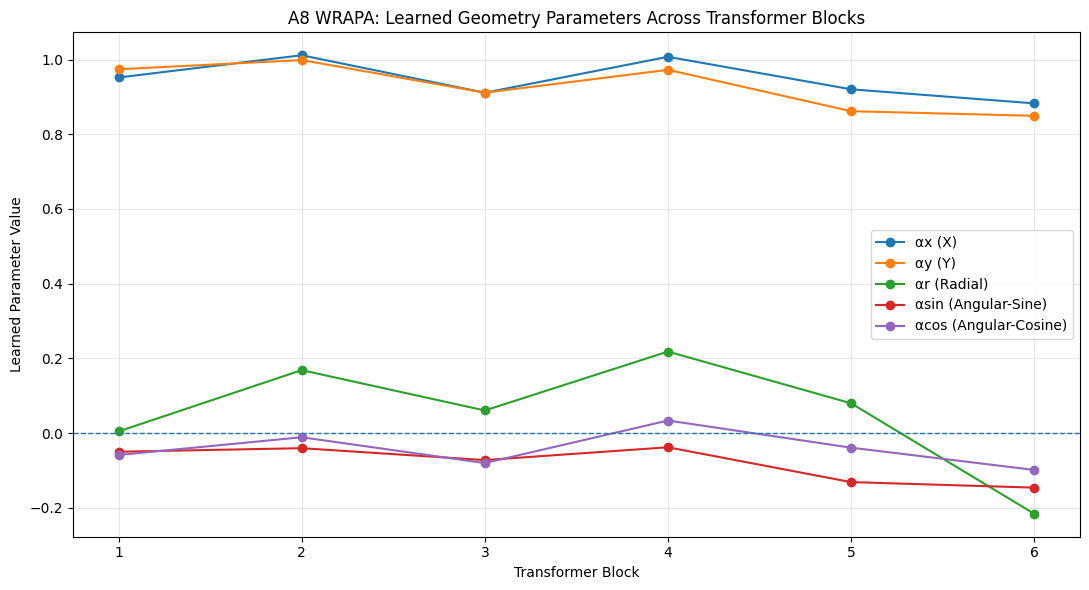

Saved:
/kaggle/working/A8_WRAPA_Learned_Alpha_Parameters.png


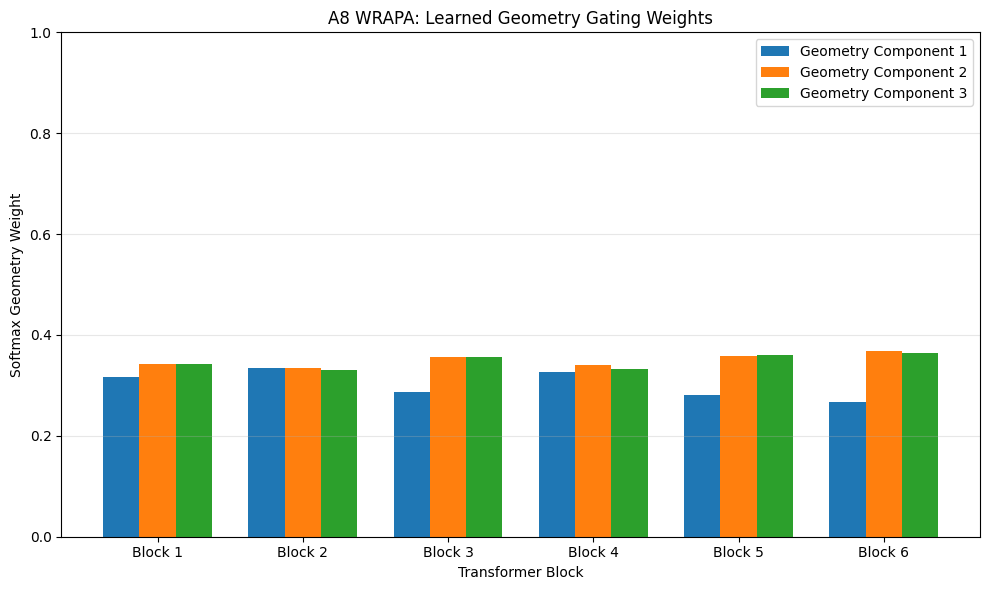

Saved:
/kaggle/working/A8_WRAPA_Geometry_Gating_Weights.png


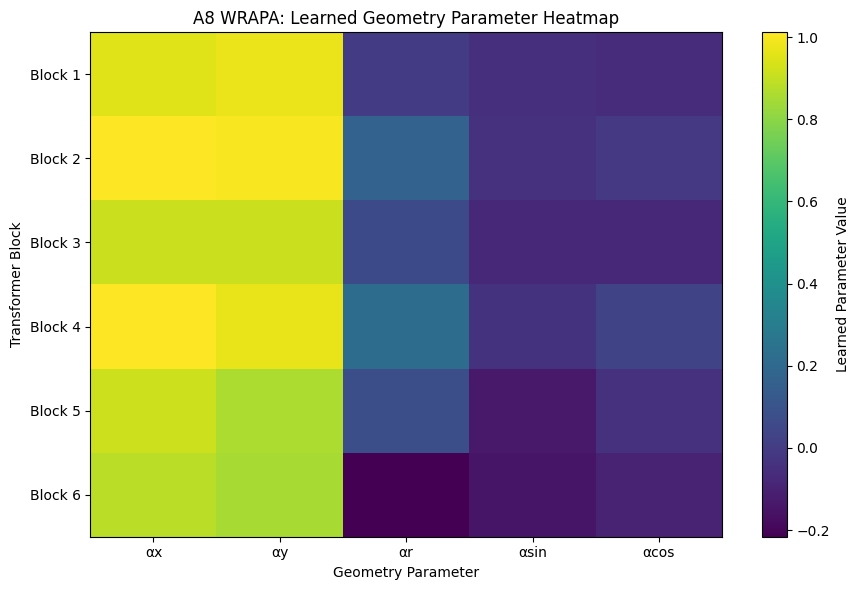

Saved:
/kaggle/working/A8_WRAPA_Geometry_Heatmap.png


In [7]:
# ============================================================
# A8 WRAPA — LEARNED GEOMETRY VISUALIZATION
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

A8_PATH = "/kaggle/working/best_model_A8_WRAPA.pth"

ckpt = torch.load(A8_PATH, map_location="cpu")

# ------------------------------------------------------------
# Extract learned parameters
# ------------------------------------------------------------

rows = []

for block in range(6):

    row = {
        "Block": block + 1,
        "alpha_x": float(
            ckpt[f"blocks.{block}.attention.alpha_x"].item()
        ),
        "alpha_y": float(
            ckpt[f"blocks.{block}.attention.alpha_y"].item()
        ),
        "alpha_r": float(
            ckpt[f"blocks.{block}.attention.alpha_r"].item()
        ),
        "alpha_sin": float(
            ckpt[f"blocks.{block}.attention.alpha_sin"].item()
        ),
        "alpha_cos": float(
            ckpt[f"blocks.{block}.attention.alpha_cos"].item()
        ),
    }

    # Geometry logits
    logits = ckpt[
        f"blocks.{block}.attention.geometry_logits"
    ].detach().cpu().numpy()

    row["geometry_logit_1"] = float(logits[0])
    row["geometry_logit_2"] = float(logits[1])
    row["geometry_logit_3"] = float(logits[2])

    # Softmax probabilities
    probs = torch.softmax(
        torch.tensor(logits, dtype=torch.float32),
        dim=0
    ).numpy()

    row["geometry_weight_1"] = float(probs[0])
    row["geometry_weight_2"] = float(probs[1])
    row["geometry_weight_3"] = float(probs[2])

    rows.append(row)

geometry_df = pd.DataFrame(rows)

print("=" * 80)
print("A8 WRAPA — LEARNED GEOMETRY PARAMETERS")
print("=" * 80)

display(
    geometry_df.round(6)
)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

csv_path = "/kaggle/working/A8_WRAPA_Learned_Geometry.csv"

geometry_df.to_csv(
    csv_path,
    index=False
)

print("\nSaved:")
print(csv_path)


# ============================================================
# FIGURE 1 — Alpha parameters across transformer blocks
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(
    geometry_df["Block"],
    geometry_df["alpha_x"],
    marker="o",
    label="αx (X)"
)

plt.plot(
    geometry_df["Block"],
    geometry_df["alpha_y"],
    marker="o",
    label="αy (Y)"
)

plt.plot(
    geometry_df["Block"],
    geometry_df["alpha_r"],
    marker="o",
    label="αr (Radial)"
)

plt.plot(
    geometry_df["Block"],
    geometry_df["alpha_sin"],
    marker="o",
    label="αsin (Angular-Sine)"
)

plt.plot(
    geometry_df["Block"],
    geometry_df["alpha_cos"],
    marker="o",
    label="αcos (Angular-Cosine)"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Transformer Block")
plt.ylabel("Learned Parameter Value")
plt.title("A8 WRAPA: Learned Geometry Parameters Across Transformer Blocks")
plt.xticks(range(1, 7))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

fig1_path = "/kaggle/working/A8_WRAPA_Learned_Alpha_Parameters.png"

plt.savefig(
    fig1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(fig1_path)


# ============================================================
# FIGURE 2 — Geometry softmax weights
# ============================================================

plt.figure(figsize=(10, 6))

x = np.arange(6)
width = 0.25

plt.bar(
    x - width,
    geometry_df["geometry_weight_1"],
    width,
    label="Geometry Component 1"
)

plt.bar(
    x,
    geometry_df["geometry_weight_2"],
    width,
    label="Geometry Component 2"
)

plt.bar(
    x + width,
    geometry_df["geometry_weight_3"],
    width,
    label="Geometry Component 3"
)

plt.xlabel("Transformer Block")
plt.ylabel("Softmax Geometry Weight")
plt.title("A8 WRAPA: Learned Geometry Gating Weights")
plt.xticks(x, [f"Block {i}" for i in range(1, 7)])
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

fig2_path = "/kaggle/working/A8_WRAPA_Geometry_Gating_Weights.png"

plt.savefig(
    fig2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(fig2_path)


# ============================================================
# FIGURE 3 — Heatmap of alpha parameters
# ============================================================

alpha_columns = [
    "alpha_x",
    "alpha_y",
    "alpha_r",
    "alpha_sin",
    "alpha_cos"
]

alpha_matrix = geometry_df[
    alpha_columns
].values

plt.figure(figsize=(9, 6))

plt.imshow(
    alpha_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Learned Parameter Value"
)

plt.xticks(
    range(len(alpha_columns)),
    ["αx", "αy", "αr", "αsin", "αcos"]
)

plt.yticks(
    range(6),
    [f"Block {i}" for i in range(1, 7)]
)

plt.xlabel("Geometry Parameter")
plt.ylabel("Transformer Block")
plt.title("A8 WRAPA: Learned Geometry Parameter Heatmap")

plt.tight_layout()

fig3_path = "/kaggle/working/A8_WRAPA_Geometry_Heatmap.png"

plt.savefig(
    fig3_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(fig3_path)

In [9]:
# ============================================================
# A8 WRAPA — MODEL STRUCTURE INSPECTION
# ============================================================

import torch
import inspect

print("=" * 80)
print("WRAPA_ViT CLASS INFORMATION")
print("=" * 80)

print("Class:", WRAPA_ViT)
print("Module:", WRAPA_ViT.__module__)
print("Name:", WRAPA_ViT.__name__)

print("\n" + "=" * 80)
print("WRAPA_ViT CONSTRUCTOR SIGNATURE")
print("=" * 80)

try:
    print(inspect.signature(WRAPA_ViT))
except Exception as e:
    print("Could not retrieve signature:", e)


# ============================================================
# Inspect __init__ and forward bytecode information
# ============================================================

print("\n" + "=" * 80)
print("METHOD INFORMATION")
print("=" * 80)

for method_name in ["__init__", "forward"]:

    if hasattr(WRAPA_ViT, method_name):

        method = getattr(WRAPA_ViT, method_name)

        print(f"\n{method_name}:")
        print("  Object:", method)

        try:
            print("  Signature:", inspect.signature(method))
        except Exception as e:
            print("  Signature unavailable:", e)

        try:
            print("  Module:", method.__module__)
        except Exception:
            pass


# ============================================================
# Show currently defined classes that may belong to WRAPA
# ============================================================

print("\n" + "=" * 80)
print("POSSIBLE WRAPA COMPONENT CLASSES")
print("=" * 80)

for name, obj in sorted(globals().items()):

    if inspect.isclass(obj):

        lname = name.lower()

        if any(
            keyword in lname
            for keyword in [
                "wrapa",
                "rope",
                "geometry",
                "attention",
                "transformer",
                "patch"
            ]
        ):

            print(
                f"{name:35s} "
                f"module={getattr(obj, '__module__', 'unknown')}"
            )


# ============================================================
# Inspect WRAPA_ViT class attributes
# ============================================================

print("\n" + "=" * 80)
print("WRAPA_ViT CLASS ATTRIBUTES")
print("=" * 80)

for name in dir(WRAPA_ViT):

    if not name.startswith("__"):

        try:
            obj = getattr(WRAPA_ViT, name)

            if callable(obj):
                print(name)

        except Exception:
            pass

WRAPA_ViT CLASS INFORMATION
Class: <class '__main__.WRAPA_ViT'>
Module: __main__
Name: WRAPA_ViT

WRAPA_ViT CONSTRUCTOR SIGNATURE
(geometry)

METHOD INFORMATION

__init__:
  Object: <function WRAPA_ViT.__init__ at 0x7926694c40e0>
  Signature: (self, geometry)
  Module: __main__

forward:
  Object: <function WRAPA_ViT.forward at 0x7926694c4180>
  Signature: (self, x)
  Module: __main__

POSSIBLE WRAPA COMPONENT CLASSES
GeometryRoPEAttention               module=__main__
PatchEmbedding                      module=__main__
TransformerBlock                    module=__main__
WRAPA_Attention                     module=__main__
WRAPA_Block                         module=__main__
WRAPA_ViT                           module=__main__

WRAPA_ViT CLASS ATTRIBUTES
_apply
_call_impl
_get_backward_hooks
_get_backward_pre_hooks
_get_name
_load_from_state_dict
_maybe_warn_non_full_backward_hook
_named_members
_register_load_state_dict_pre_hook
_register_state_dict_hook
_replicate_for_data_parallel
_sav

In [10]:
# ============================================================
# A8 WRAPA — IMPLEMENTATION INSPECTION
# ============================================================

import dis
import inspect

classes_to_check = [
    "WRAPA_ViT",
    "WRAPA_Block",
    "WRAPA_Attention",
    "GeometryRoPEAttention",
    "PatchEmbedding"
]

for class_name in classes_to_check:

    if class_name not in globals():
        print(f"\n{class_name}: NOT FOUND")
        continue

    cls = globals()[class_name]

    print("\n" + "=" * 90)
    print(f"{class_name}")
    print("=" * 90)

    # --------------------------------------------------------
    # Constructor
    # --------------------------------------------------------

    if hasattr(cls, "__init__"):

        print("\n--- __init__ signature ---")

        try:
            print(inspect.signature(cls.__init__))
        except Exception as e:
            print("Signature unavailable:", e)

        print("\n--- __init__ bytecode ---")

        try:
            dis.dis(cls.__init__)
        except Exception as e:
            print("Could not disassemble __init__:", e)

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------

    if hasattr(cls, "forward"):

        print("\n--- forward signature ---")

        try:
            print(inspect.signature(cls.forward))
        except Exception as e:
            print("Signature unavailable:", e)

        print("\n--- forward bytecode ---")

        try:
            dis.dis(cls.forward)
        except Exception as e:
            print("Could not disassemble forward:", e)


WRAPA_ViT

--- __init__ signature ---
(self, geometry)

--- __init__ bytecode ---
              0 COPY_FREE_VARS           1

470           2 RESUME                   0

474           4 LOAD_GLOBAL              0 (super)
             14 LOAD_DEREF               3 (__class__)
             16 LOAD_FAST                0 (self)
             18 LOAD_SUPER_ATTR          5 (NULL|self + __init__)
             22 CALL                     0
             30 POP_TOP

476          32 LOAD_FAST                1 (geometry)
             34 LOAD_FAST                0 (self)
             36 STORE_ATTR               2 (geometry)

478          46 LOAD_GLOBAL              7 (NULL + PatchEmbedding)

479          56 LOAD_GLOBAL              8 (IMAGE_SIZE)

480          66 LOAD_GLOBAL             10 (PATCH_SIZE)

481          76 LOAD_CONST               1 (1)

482          78 LOAD_GLOBAL             12 (EMBED_DIM)

478          88 KW_NAMES                 2 (('image_size', 'patch_size', 'in_channels', 'embed

In [11]:
# ============================================================
# A8 — RECOVER EXISTING EVALUATION RESULTS
# ============================================================

print("=" * 80)
print("SEARCHING CURRENT NOTEBOOK FOR A8 RESULTS")
print("=" * 80)

keywords = [
    "a8",
    "wrpa",
    "test",
    "pred",
    "metric",
    "confusion",
    "classification",
    "result"
]

matches = []

for name, obj in globals().items():

    lname = name.lower()

    if any(k in lname for k in keywords):
        matches.append(name)

for name in sorted(matches):

    try:
        obj = globals()[name]

        print("\n" + "-" * 80)
        print("VARIABLE:", name)
        print("TYPE:", type(obj))

        if isinstance(obj, dict):
            print("DICT KEYS:")
            print(list(obj.keys())[:50])

        elif hasattr(obj, "shape"):
            print("SHAPE:", obj.shape)

        elif isinstance(obj, (list, tuple)):
            print("LENGTH:", len(obj))

    except Exception as e:
        print(name, "->", e)

print("\n" + "=" * 80)
print("SEARCH COMPLETE")
print("=" * 80)

SEARCHING CURRENT NOTEBOOK FOR A8 RESULTS

--------------------------------------------------------------------------------
VARIABLE: A8_PATH
TYPE: <class 'str'>

--------------------------------------------------------------------------------
VARIABLE: a8
TYPE: <class 'collections.OrderedDict'>
DICT KEYS:
['cls_token', 'patch_embed.projection.weight', 'patch_embed.projection.bias', 'blocks.0.norm1.weight', 'blocks.0.norm1.bias', 'blocks.0.attention.alpha_x', 'blocks.0.attention.alpha_y', 'blocks.0.attention.alpha_r', 'blocks.0.attention.alpha_sin', 'blocks.0.attention.alpha_cos', 'blocks.0.attention.geometry_logits', 'blocks.0.attention.qkv.weight', 'blocks.0.attention.qkv.bias', 'blocks.0.attention.proj.weight', 'blocks.0.attention.proj.bias', 'blocks.0.norm2.weight', 'blocks.0.norm2.bias', 'blocks.0.mlp.0.weight', 'blocks.0.mlp.0.bias', 'blocks.0.mlp.3.weight', 'blocks.0.mlp.3.bias', 'blocks.1.norm1.weight', 'blocks.1.norm1.bias', 'blocks.1.attention.alpha_x', 'blocks.1.attention.al

In [12]:
import inspect
import dis

print("=" * 90)
print("INSPECTING TRANSFORMERBLOCK")
print("=" * 90)

print("\nCLASS:")
print(TransformerBlock)

print("\nSIGNATURE:")
print(inspect.signature(TransformerBlock))

print("\n" + "-" * 90)
print("TRANSFORMERBLOCK __init__")
print("-" * 90)

print(inspect.signature(TransformerBlock.__init__))
dis.dis(TransformerBlock.__init__)

print("\n" + "-" * 90)
print("TRANSFORMERBLOCK forward")
print("-" * 90)

print(inspect.signature(TransformerBlock.forward))
dis.dis(TransformerBlock.forward)

print("\n" + "-" * 90)
print("SOURCE CODE")
print("-" * 90)

try:
    print(inspect.getsource(TransformerBlock))
except Exception as e:
    print("Could not retrieve source code:")
    print(e)

INSPECTING TRANSFORMERBLOCK

CLASS:
<class '__main__.TransformerBlock'>

SIGNATURE:
(embed_dim=128, num_heads=4, mlp_ratio=4, geometry='xy', dropout=0.1)

------------------------------------------------------------------------------------------
TRANSFORMERBLOCK __init__
------------------------------------------------------------------------------------------
(self, embed_dim=128, num_heads=4, mlp_ratio=4, geometry='xy', dropout=0.1)
              0 COPY_FREE_VARS           1

404           2 RESUME                   0

412           4 LOAD_GLOBAL              0 (super)
             14 LOAD_DEREF               7 (__class__)
             16 LOAD_FAST                0 (self)
             18 LOAD_SUPER_ATTR          5 (NULL|self + __init__)
             22 CALL                     0
             30 POP_TOP

414          32 LOAD_GLOBAL              4 (nn)
             42 LOAD_ATTR                7 (NULL|self + LayerNorm)

415          62 LOAD_FAST                1 (embed_dim)

414        

In [13]:
import torch
import numpy as np

print("=" * 90)
print("RECONSTRUCTING AND VERIFYING A8 WRAPA CHECKPOINT")
print("=" * 90)

# ---------------------------------------------------------
# 1. Checkpoint
# ---------------------------------------------------------
A8_PATH = "/kaggle/working/best_model_A8_WRAPA.pth"

checkpoint = torch.load(
    A8_PATH,
    map_location="cpu"
)

print("\nCheckpoint type:", type(checkpoint))

# Raw OrderedDict checkpoint
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    a8_state = checkpoint["model_state_dict"]
else:
    a8_state = checkpoint

print("Number of checkpoint tensors:", len(a8_state))

# ---------------------------------------------------------
# 2. Build EXACT architecture used by TransformerBlock
# ---------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_A8 = WRAPA_ViT(
    geometry="wra"
).to(device)

print("\nModel created successfully.")
print("Device:", device)

# ---------------------------------------------------------
# 3. Compare checkpoint and model keys
# ---------------------------------------------------------

model_state = model_A8.state_dict()

checkpoint_keys = set(a8_state.keys())
model_keys = set(model_state.keys())

missing_keys = model_keys - checkpoint_keys
unexpected_keys = checkpoint_keys - model_keys

print("\n" + "-" * 90)
print("CHECKPOINT COMPATIBILITY")
print("-" * 90)

print("Model tensors     :", len(model_keys))
print("Checkpoint tensors:", len(checkpoint_keys))

print("\nMissing keys:")
print(missing_keys)

print("\nUnexpected keys:")
print(unexpected_keys)

# ---------------------------------------------------------
# 4. Load checkpoint
# ---------------------------------------------------------

try:
    result = model_A8.load_state_dict(a8_state, strict=True)

    print("\n" + "=" * 90)
    print("SUCCESS: A8 CHECKPOINT LOADED WITH strict=True")
    print("=" * 90)
    print(result)

except Exception as e:

    print("\n" + "=" * 90)
    print("CHECKPOINT LOAD FAILED")
    print("=" * 90)
    print(type(e).__name__)
    print(e)

# ---------------------------------------------------------
# 5. Print architecture information
# ---------------------------------------------------------

print("\n" + "-" * 90)
print("A8 ARCHITECTURE CONFIGURATION")
print("-" * 90)

print("IMAGE_SIZE :", IMAGE_SIZE)
print("PATCH_SIZE :", PATCH_SIZE)
print("EMBED_DIM  :", EMBED_DIM)
print("DEPTH      :", DEPTH)
print("NUM_HEADS  :", NUM_HEADS)
print("NUM_CLASSES:", NUM_CLASSES)

print("\nGeometry:", model_A8.geometry)

# ---------------------------------------------------------
# 6. Count parameters
# ---------------------------------------------------------

total_params = sum(
    p.numel() for p in model_A8.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_A8.parameters()
    if p.requires_grad
)

print("\nTotal parameters    :", total_params)
print("Trainable parameters:", trainable_params)

# ---------------------------------------------------------
# 7. Confirm geometry_logits
# ---------------------------------------------------------

print("\n" + "-" * 90)
print("LEARNED GEOMETRY LOGITS")
print("-" * 90)

for i, block in enumerate(model_A8.blocks):

    attn = block.attention

    if hasattr(attn, "geometry_logits"):

        logits = attn.geometry_logits.detach().cpu().numpy()

        weights = (
            3.0 *
            torch.softmax(
                attn.geometry_logits.detach().cpu(),
                dim=0
            ).numpy()
        )

        print(f"\nBlock {i+1}")
        print("Logits :", logits)
        print("Weights:")
        print("  XY      :", weights[0])
        print("  Radial  :", weights[1])
        print("  Angular :", weights[2])
        print("  Sum     :", weights.sum())

    else:
        print(f"\nBlock {i+1}: geometry_logits NOT FOUND")

RECONSTRUCTING AND VERIFYING A8 WRAPA CHECKPOINT

Checkpoint type: <class 'collections.OrderedDict'>
Number of checkpoint tensors: 115

Model created successfully.
Device: cuda

------------------------------------------------------------------------------------------
CHECKPOINT COMPATIBILITY
------------------------------------------------------------------------------------------
Model tensors     : 115
Checkpoint tensors: 115

Missing keys:
set()

Unexpected keys:
set()

SUCCESS: A8 CHECKPOINT LOADED WITH strict=True
<All keys matched successfully>

------------------------------------------------------------------------------------------
A8 ARCHITECTURE CONFIGURATION
------------------------------------------------------------------------------------------
IMAGE_SIZE : 64
PATCH_SIZE : 16
EMBED_DIM  : 128
DEPTH      : 6
NUM_HEADS  : 4
NUM_CLASSES: 9

Geometry: wra

Total parameters    : 1224121
Trainable parameters: 1224121

----------------------------------------------------------

In [14]:
import pandas as pd
import numpy as np
import torch

print("=" * 90)
print("EXTRACTING A8 LEARNED GEOMETRY PARAMETERS")
print("=" * 90)

rows = []

for i, block in enumerate(model_A8.blocks):

    attn = block.attention

    # Alpha parameters
    alpha_x = attn.alpha_x.detach().cpu().item()
    alpha_y = attn.alpha_y.detach().cpu().item()
    alpha_r = attn.alpha_r.detach().cpu().item()
    alpha_sin = attn.alpha_sin.detach().cpu().item()
    alpha_cos = attn.alpha_cos.detach().cpu().item()

    # Geometry logits
    logits = attn.geometry_logits.detach().cpu()

    # Actual WRA weights
    weights = (
        3.0 * torch.softmax(logits, dim=0)
    ).numpy()

    rows.append({
        "Block": i + 1,

        "Alpha_X": alpha_x,
        "Alpha_Y": alpha_y,
        "Alpha_R": alpha_r,
        "Alpha_Sin": alpha_sin,
        "Alpha_Cos": alpha_cos,

        "XY_Weight": weights[0],
        "Radial_Weight": weights[1],
        "Angular_Weight": weights[2],

        "Weight_Sum": weights.sum()
    })

geometry_df = pd.DataFrame(rows)

print("\n")
print(geometry_df.round(6).to_string(index=False))

# ---------------------------------------------------------
# Save CSV
# ---------------------------------------------------------

geometry_path = "/kaggle/working/A8_Learned_Geometry_Parameters.csv"

geometry_df.to_csv(
    geometry_path,
    index=False
)

print("\n" + "=" * 90)
print("SAVED")
print("=" * 90)

print(geometry_path)

EXTRACTING A8 LEARNED GEOMETRY PARAMETERS


 Block  Alpha_X  Alpha_Y   Alpha_R  Alpha_Sin  Alpha_Cos  XY_Weight  Radial_Weight  Angular_Weight  Weight_Sum
     1 0.952030 0.974044  0.004354  -0.050065  -0.058755   0.947628       1.024580        1.027792         3.0
     2 1.011539 0.998720  0.168446  -0.040563  -0.011281   1.004165       1.003565        0.992270         3.0
     3 0.911244 0.911344  0.060421  -0.072395  -0.080449   0.859507       1.071500        1.068993         3.0
     4 1.007415 0.972573  0.218169  -0.038124   0.033555   0.981248       1.018907        0.999844         3.0
     5 0.920415 0.861785  0.079662  -0.131394  -0.039189   0.844440       1.074842        1.080718         3.0
     6 0.882735 0.849377 -0.216235  -0.146154  -0.098804   0.801424       1.103873        1.094703         3.0

SAVED
/kaggle/working/A8_Learned_Geometry_Parameters.csv


In [15]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

print("=" * 90)
print("FINAL EVALUATION OF VERIFIED A8 WRAPA CHECKPOINT")
print("=" * 90)

# ---------------------------------------------------------
# Make sure model is loaded and in evaluation mode
# ---------------------------------------------------------

model_A8.eval()

all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_A8(images)

        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

# ---------------------------------------------------------
# Convert to numpy
# ---------------------------------------------------------

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

print("\nNumber of test samples:", len(all_labels))

# ---------------------------------------------------------
# Metrics
# ---------------------------------------------------------

accuracy = accuracy_score(
    all_labels,
    all_preds
)

macro_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    all_labels,
    all_preds,
    average="weighted",
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    all_labels,
    all_preds
)

# ---------------------------------------------------------
# Print metrics
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("A8 TEST RESULTS")
print("=" * 90)

print(f"Accuracy          : {accuracy:.6f} ({accuracy*100:.2f}%)")
print(f"Macro-F1          : {macro_f1:.6f} ({macro_f1*100:.2f}%)")
print(f"Weighted-F1       : {weighted_f1:.6f} ({weighted_f1*100:.2f}%)")
print(f"Balanced Accuracy : {balanced_acc:.6f} ({balanced_acc*100:.2f}%)")

# ---------------------------------------------------------
# Classification report
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("CLASSIFICATION REPORT")
print("=" * 90)

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# ---------------------------------------------------------
# Confusion matrix
# ---------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_preds
)

print("\n" + "=" * 90)
print("CONFUSION MATRIX")
print("=" * 90)

print(cm)

# ---------------------------------------------------------
# Save final A8 results
# ---------------------------------------------------------

a8_final_results = pd.DataFrame([{
    "Experiment": "A8_WRAPA",
    "Geometry": "wra",
    "Image_Size": IMAGE_SIZE,
    "Patch_Size": PATCH_SIZE,
    "Embedding_Dim": EMBED_DIM,
    "Depth": DEPTH,
    "Heads": NUM_HEADS,
    "Parameters": sum(p.numel() for p in model_A8.parameters()),
    "Accuracy": accuracy,
    "Macro_F1": macro_f1,
    "Weighted_F1": weighted_f1,
    "Balanced_Accuracy": balanced_acc
}])

a8_final_path = "/kaggle/working/A8_FINAL_VERIFIED_RESULTS.csv"

a8_final_results.to_csv(
    a8_final_path,
    index=False
)

print("\nSaved:")
print(a8_final_path)

# ---------------------------------------------------------
# Save confusion matrix
# ---------------------------------------------------------

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_path = "/kaggle/working/A8_FINAL_CONFUSION_MATRIX.csv"

cm_df.to_csv(
    cm_path
)

print(cm_path)

FINAL EVALUATION OF VERIFIED A8 WRAPA CHECKPOINT

Number of test samples: 25943

A8 TEST RESULTS
Accuracy          : 0.854412 (85.44%)
Macro-F1          : 0.665025 (66.50%)
Weighted-F1       : 0.885796 (88.58%)
Balanced Accuracy : 0.820504 (82.05%)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        none     0.9915    0.8563    0.9189     22115
      Center     0.6327    0.9146    0.7479       644
       Donut     0.8065    0.9036    0.8523        83
    Edge-Loc     0.3793    0.7946    0.5135       779
   Edge-Ring     0.8725    0.9848    0.9253      1452
         Loc     0.3973    0.5417    0.4584       539
   Near-full     0.7586    1.0000    0.8627        22
      Random     0.4532    0.9308    0.6096       130
     Scratch     0.0540    0.4581    0.0966       179

    accuracy                         0.8544     25943
   macro avg     0.5939    0.8205    0.6650     25943
weighted avg     0.9352    0.8544    0.8858     25943


CONFUSION MATRIX
[[189

In [16]:
import pandas as pd

path = "/kaggle/working/WRAPA_Ablation_Results.csv"

ablation_df = pd.read_csv(path)

print("=" * 100)
print("CURRENT WRAPA ABLATION RESULTS")
print("=" * 100)

print("\nShape:", ablation_df.shape)

print("\nColumns:")
print(list(ablation_df.columns))

print("\nFull table:")
print(ablation_df.to_string(index=False))

CURRENT WRAPA ABLATION RESULTS

Shape: (5, 39)

Columns:
['Experiment', 'Geometry', 'Best_Val_MacroF1', 'Best_Epoch', 'Test_Accuracy', 'Test_MacroF1', 'Test_WeightedF1', 'Test_BalancedAccuracy', 'Parameters', 'block_1_alpha_x', 'block_1_alpha_y', 'block_1_alpha_r', 'block_1_alpha_sin', 'block_1_alpha_cos', 'block_2_alpha_x', 'block_2_alpha_y', 'block_2_alpha_r', 'block_2_alpha_sin', 'block_2_alpha_cos', 'block_3_alpha_x', 'block_3_alpha_y', 'block_3_alpha_r', 'block_3_alpha_sin', 'block_3_alpha_cos', 'block_4_alpha_x', 'block_4_alpha_y', 'block_4_alpha_r', 'block_4_alpha_sin', 'block_4_alpha_cos', 'block_5_alpha_x', 'block_5_alpha_y', 'block_5_alpha_r', 'block_5_alpha_sin', 'block_5_alpha_cos', 'block_6_alpha_x', 'block_6_alpha_y', 'block_6_alpha_r', 'block_6_alpha_sin', 'block_6_alpha_cos']

Full table:
             Experiment       Geometry  Best_Val_MacroF1  Best_Epoch  Test_Accuracy  Test_MacroF1  Test_WeightedF1  Test_BalancedAccuracy  Parameters  block_1_alpha_x  block_1_alpha_y 

In [17]:
import torch

A7_PATH = "/kaggle/working/WRAPA_3Seed_A7_WRAPA_seed42.pth"

a7_checkpoint = torch.load(
    A7_PATH,
    map_location="cpu"
)

print("=" * 90)
print("A7 CHECKPOINT METADATA")
print("=" * 90)

print("Checkpoint type:", type(a7_checkpoint))

if isinstance(a7_checkpoint, dict):

    print("\nKeys:")
    print(list(a7_checkpoint.keys()))

    print("\nMetadata:")

    for key in [
        "experiment",
        "geometry",
        "seed",
        "best_epoch",
        "best_val_macro_f1"
    ]:

        if key in a7_checkpoint:
            print(f"{key}: {a7_checkpoint[key]}")

    if "model_state_dict" in a7_checkpoint:

        state = a7_checkpoint["model_state_dict"]

        print("\nNumber of model tensors:", len(state))

        print("\nFirst 30 model keys:")

        for k in list(state.keys())[:30]:
            print(k)

        print("\nContains geometry_logits:",
              any("geometry_logits" in k for k in state.keys()))

        print("Contains cls_token:",
              any("cls_token" in k for k in state.keys()))

        print("Contains alpha parameters:",
              any("alpha_x" in k for k in state.keys()))

        print("\nParameter count:")

        print(
            sum(
                tensor.numel()
                for tensor in state.values()
                if torch.is_tensor(tensor)
            )
        )

A7 CHECKPOINT METADATA
Checkpoint type: <class 'dict'>

Keys:
['model_state_dict', 'experiment', 'geometry', 'seed', 'best_epoch', 'best_val_macro_f1']

Metadata:
experiment: A7_WRAPA
geometry: radial_angular
seed: 42
best_epoch: 10
best_val_macro_f1: 0.7359900629760849

Number of model tensors: 133

First 30 model keys:
cls_token
patch_embed.projection.weight
patch_embed.projection.bias
blocks.0.norm1.weight
blocks.0.norm1.bias
blocks.0.attention.alpha_x
blocks.0.attention.alpha_y
blocks.0.attention.alpha_r
blocks.0.attention.alpha_sin
blocks.0.attention.alpha_cos
blocks.0.attention.q_proj.weight
blocks.0.attention.q_proj.bias
blocks.0.attention.k_proj.weight
blocks.0.attention.k_proj.bias
blocks.0.attention.v_proj.weight
blocks.0.attention.v_proj.bias
blocks.0.attention.out_proj.weight
blocks.0.attention.out_proj.bias
blocks.0.norm2.weight
blocks.0.norm2.bias
blocks.0.mlp.0.weight
blocks.0.mlp.0.bias
blocks.0.mlp.3.weight
blocks.0.mlp.3.bias
blocks.1.norm1.weight
blocks.1.norm1.bias


In [18]:
import pandas as pd

path = "/kaggle/working/WRAPA_3Seed_Individual_Results.csv"

df = pd.read_csv(path)

print("=" * 100)
print("WRAPA 3-SEED INDIVIDUAL RESULTS")
print("=" * 100)

print("\nShape:", df.shape)

print("\nColumns:")
print(list(df.columns))

print("\nFull results:")
print(df.to_string(index=False))

WRAPA 3-SEED INDIVIDUAL RESULTS

Shape: (9, 9)

Columns:
['Experiment', 'Geometry', 'Seed', 'Best_Val_MacroF1', 'Best_Epoch', 'Test_Accuracy', 'Test_MacroF1', 'Test_WeightedF1', 'Test_BalancedAccuracy']

Full results:
     Experiment       Geometry  Seed  Best_Val_MacroF1  Best_Epoch  Test_Accuracy  Test_MacroF1  Test_WeightedF1  Test_BalancedAccuracy
       A4_ARoPE             xy    42          0.691835           7       0.910419      0.701565         0.924726               0.794248
       A4_ARoPE             xy   123          0.706648           8       0.924681      0.700263         0.934971               0.743636
       A4_ARoPE             xy  2024          0.686592          10       0.868943      0.683391         0.899313               0.815125
A5_ARoPE_Radial         radial    42          0.722760          10       0.879158      0.723573         0.907190               0.864960
A5_ARoPE_Radial         radial   123          0.749447           8       0.916047      0.742487       

In [19]:
import pandas as pd

path = "/kaggle/working/WRAPA_3Seed_Summary.csv"

df = pd.read_csv(path)

print("=" * 100)
print("WRAPA 3-SEED SUMMARY")
print("=" * 100)

print("\nShape:", df.shape)

print("\nColumns:")
print(list(df.columns))

print("\nFull summary:")
print(df.to_string(index=False))

WRAPA 3-SEED SUMMARY

Shape: (3, 12)

Columns:
['Experiment', 'Geometry', 'Best_Val_MacroF1_Mean', 'Best_Val_MacroF1_Std', 'Test_Accuracy_Mean', 'Test_Accuracy_Std', 'Test_MacroF1_Mean', 'Test_MacroF1_Std', 'Test_WeightedF1_Mean', 'Test_WeightedF1_Std', 'Test_BalancedAccuracy_Mean', 'Test_BalancedAccuracy_Std']

Full summary:
     Experiment       Geometry  Best_Val_MacroF1_Mean  Best_Val_MacroF1_Std  Test_Accuracy_Mean  Test_Accuracy_Std  Test_MacroF1_Mean  Test_MacroF1_Std  Test_WeightedF1_Mean  Test_WeightedF1_Std  Test_BalancedAccuracy_Mean  Test_BalancedAccuracy_Std
       A4_ARoPE             xy               0.695025              0.010402            0.901348           0.028955           0.695073          0.010138              0.919670             0.018358                    0.784336                   0.036760
A5_ARoPE_Radial         radial               0.726022              0.021976            0.886598           0.026524           0.721848          0.021554              0.91182

In [20]:
import torch
import os

path = "/kaggle/working/best_model_A8_WRAPA.pth"

print("=" * 100)
print("A8 CHECKPOINT INSPECTION")
print("=" * 100)

print("\nFile exists:", os.path.exists(path))
print("File size (MB):", round(os.path.getsize(path) / (1024**2), 2))

checkpoint = torch.load(path, map_location="cpu")

print("\nCheckpoint type:")
print(type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    print(list(checkpoint.keys()))

    print("\nNumber of tensors:")
    print(len(checkpoint))

    print("\nFirst 20 parameter keys:")
    for i, key in enumerate(checkpoint.keys()):
        if i >= 20:
            break
        print(f"{i+1:2d}. {key}")

else:
    print("\nCheckpoint is not a dictionary.")

A8 CHECKPOINT INSPECTION

File exists: True
File size (MB): 4.71

Checkpoint type:
<class 'collections.OrderedDict'>

Checkpoint keys:
['cls_token', 'patch_embed.projection.weight', 'patch_embed.projection.bias', 'blocks.0.norm1.weight', 'blocks.0.norm1.bias', 'blocks.0.attention.alpha_x', 'blocks.0.attention.alpha_y', 'blocks.0.attention.alpha_r', 'blocks.0.attention.alpha_sin', 'blocks.0.attention.alpha_cos', 'blocks.0.attention.geometry_logits', 'blocks.0.attention.qkv.weight', 'blocks.0.attention.qkv.bias', 'blocks.0.attention.proj.weight', 'blocks.0.attention.proj.bias', 'blocks.0.norm2.weight', 'blocks.0.norm2.bias', 'blocks.0.mlp.0.weight', 'blocks.0.mlp.0.bias', 'blocks.0.mlp.3.weight', 'blocks.0.mlp.3.bias', 'blocks.1.norm1.weight', 'blocks.1.norm1.bias', 'blocks.1.attention.alpha_x', 'blocks.1.attention.alpha_y', 'blocks.1.attention.alpha_r', 'blocks.1.attention.alpha_sin', 'blocks.1.attention.alpha_cos', 'blocks.1.attention.geometry_logits', 'blocks.1.attention.qkv.weight', 

In [21]:
print("=" * 100)
print("CURRENT MODEL / TRAINING CONFIGURATION")
print("=" * 100)

variables_to_check = [
    "IMAGE_SIZE",
    "PATCH_SIZE",
    "EMBED_DIM",
    "DEPTH",
    "NUM_HEADS",
    "NUM_CLASSES",
    "BATCH_SIZE",
    "EPOCHS",
    "LR",
    "WEIGHT_DECAY",
    "SEED",
    "device"
]

for name in variables_to_check:
    if name in globals():
        print(f"{name:15s} = {globals()[name]}")
    else:
        print(f"{name:15s} = NOT DEFINED")

print("\nDataset loaders:")
for name in ["train_loader", "val_loader", "test_loader"]:
    if name in globals():
        try:
            print(f"{name:15s} = {len(globals()[name].dataset)} samples")
        except:
            print(f"{name:15s} = exists")
    else:
        print(f"{name:15s} = NOT DEFINED")

CURRENT MODEL / TRAINING CONFIGURATION
IMAGE_SIZE      = 64
PATCH_SIZE      = 16
EMBED_DIM       = 128
DEPTH           = 6
NUM_HEADS       = 4
NUM_CLASSES     = 9
BATCH_SIZE      = 64
EPOCHS          = 10
LR              = 0.0003
WEIGHT_DECAY    = 0.0001
SEED            = 42
device          = cuda

Dataset loaders:
train_loader    = 121065 samples
val_loader      = 25942 samples
test_loader     = 25943 samples


In [22]:
import os
import glob

print("=" * 100)
print("A8-RELATED FILES IN KAGGLE WORKING DIRECTORY")
print("=" * 100)

files = sorted(glob.glob("/kaggle/working/*"))

for f in files:
    name = os.path.basename(f)

    if "A8" in name.upper() or "WRAPA" in name.upper() or "HISTORY" in name.upper():
        size_mb = os.path.getsize(f) / (1024**2)
        print(f"{name:55s} {size_mb:8.2f} MB")

A8-RELATED FILES IN KAGGLE WORKING DIRECTORY
A8_FINAL_CONFUSION_MATRIX.csv                               0.00 MB
A8_FINAL_VERIFIED_RESULTS.csv                               0.00 MB
A8_Learned_Geometry_Parameters.csv                          0.00 MB
A8_WRAPA_Geometry_Gating_Weights.png                        0.12 MB
A8_WRAPA_Geometry_Heatmap.png                               0.12 MB
A8_WRAPA_Learned_Alpha_Parameters.png                       0.26 MB
A8_WRAPA_Learned_Geometry.csv                               0.00 MB
WRAPA_3Seed_A4_ARoPE_seed123.pth                            4.72 MB
WRAPA_3Seed_A4_ARoPE_seed2024.pth                           4.72 MB
WRAPA_3Seed_A4_ARoPE_seed42.pth                             4.72 MB
WRAPA_3Seed_A5_ARoPE_Radial_seed123.pth                     4.72 MB
WRAPA_3Seed_A5_ARoPE_Radial_seed2024.pth                    4.72 MB
WRAPA_3Seed_A5_ARoPE_Radial_seed42.pth                      4.72 MB
WRAPA_3Seed_A7_WRAPA_seed123.pth                            4.72 MB
WRA

In [24]:
import pandas as pd

path = "/kaggle/working/WRAPA_Ablation_History.csv"

df = pd.read_csv(path)

print("=" * 100)
print("WRAPA ABLATION HISTORY")
print("=" * 100)

print("\nShape:", df.shape)

print("\nExperiments:")
print(df["experiment"].unique())

print("\nRows per experiment:")
print(df.groupby("experiment").size())

print("\nBest validation Macro-F1 for each experiment:")

best_rows = (
    df.loc[df.groupby("experiment")["val_macro_f1"].idxmax()]
      .sort_values("experiment")
)

print(
    best_rows[
        [
            "experiment",
            "epoch",
            "train_loss",
            "train_accuracy",
            "train_macro_f1",
            "val_loss",
            "val_accuracy",
            "val_macro_f1"
        ]
    ].to_string(index=False)
)

print("\nFull history:")
print(df.to_string(index=False))

WRAPA ABLATION HISTORY

Shape: (50, 8)

Experiments:
['A4_ARoPE' 'A5_ARoPE_Radial' 'A6_ARoPE_Angular' 'A7_ARoPE_Radial_Angular'
 'A8_WRAPA']

Rows per experiment:
experiment
A4_ARoPE                   10
A5_ARoPE_Radial            10
A6_ARoPE_Angular           10
A7_ARoPE_Radial_Angular    10
A8_WRAPA                   10
dtype: int64

Best validation Macro-F1 for each experiment:
             experiment  epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
               A4_ARoPE      8    0.532665        0.905687        0.708153  0.668296      0.936512      0.720167
        A5_ARoPE_Radial      8    0.419443        0.916334        0.743354  0.542247      0.947151      0.774597
       A6_ARoPE_Angular      8    0.492054        0.908801        0.717828  0.616479      0.929188      0.730421
A7_ARoPE_Radial_Angular      8    0.412421        0.917871        0.749886  0.506710      0.945571      0.778407
               A8_WRAPA      8    0.412421        0

In [25]:
import torch
import os

checkpoint_files = [
    "/kaggle/working/WRAPA_3Seed_A4_ARoPE_seed42.pth",
    "/kaggle/working/WRAPA_3Seed_A5_ARoPE_Radial_seed42.pth",
    "/kaggle/working/WRAPA_3Seed_A7_WRAPA_seed42.pth",
]

print("=" * 100)
print("A4 / A5 / A7 CHECKPOINT ARCHITECTURE INSPECTION")
print("=" * 100)

for path in checkpoint_files:

    print("\n" + "-" * 100)
    print(os.path.basename(path))
    print("-" * 100)

    ckpt = torch.load(path, map_location="cpu")

    print("Checkpoint type:", type(ckpt))
    print("Checkpoint keys:", list(ckpt.keys()))

    if "model_state_dict" in ckpt:
        state = ckpt["model_state_dict"]

        print("\nMetadata:")
        for key in ["experiment", "geometry", "seed", "best_epoch",
                    "best_val_macro_f1"]:
            print(f"  {key}: {ckpt.get(key)}")
    else:
        state = ckpt

    print("\nNumber of tensors:", len(state))

    keys = list(state.keys())

    print("\nArchitecture indicators:")

    print("  cls_token:",
          "YES" if "cls_token" in state else "NO")

    print("  geometry_logits:",
          "YES" if any("geometry_logits" in k for k in keys) else "NO")

    print("  combined qkv:",
          "YES" if any(".qkv." in k for k in keys) else "NO")

    print("  separate q_proj:",
          "YES" if any(".q_proj." in k for k in keys) else "NO")

    print("  number of transformer blocks:",
          len(set(
              k.split(".")[1]
              for k in keys
              if k.startswith("blocks.")
          )))

    total_params = sum(v.numel() for v in state.values())
    print("  parameters:", total_params)

A4 / A5 / A7 CHECKPOINT ARCHITECTURE INSPECTION

----------------------------------------------------------------------------------------------------
WRAPA_3Seed_A4_ARoPE_seed42.pth
----------------------------------------------------------------------------------------------------
Checkpoint type: <class 'dict'>
Checkpoint keys: ['model_state_dict', 'experiment', 'geometry', 'seed', 'best_epoch', 'best_val_macro_f1']

Metadata:
  experiment: A4_ARoPE
  geometry: xy
  seed: 42
  best_epoch: 7
  best_val_macro_f1: 0.6918348646218339

Number of tensors: 133

Architecture indicators:
  cls_token: YES
  geometry_logits: NO
  combined qkv: NO
  separate q_proj: YES
  number of transformer blocks: 6
  parameters: 1224103

----------------------------------------------------------------------------------------------------
WRAPA_3Seed_A5_ARoPE_Radial_seed42.pth
----------------------------------------------------------------------------------------------------
Checkpoint type: <class 'dict'>
C

In [26]:
import zipfile
import os

zip_path = "/kaggle/working/WRAPA_ALL_RESULTS_BACKUP.zip"

print("=" * 100)
print("WRAPA BACKUP ZIP CONTENTS")
print("=" * 100)

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()

print("\nTotal files in ZIP:", len(files))

for f in files:
    print(f)

WRAPA BACKUP ZIP CONTENTS

Total files in ZIP: 31
WRAPA_3Seed_A4_ARoPE_seed123.pth
WRAPA_3Seed_A4_ARoPE_seed2024.pth
WRAPA_3Seed_A4_ARoPE_seed42.pth
WRAPA_3Seed_A5_ARoPE_Radial_seed123.pth
WRAPA_3Seed_A5_ARoPE_Radial_seed2024.pth
WRAPA_3Seed_A5_ARoPE_Radial_seed42.pth
WRAPA_3Seed_A7_WRAPA_seed123.pth
WRAPA_3Seed_A7_WRAPA_seed2024.pth
WRAPA_3Seed_A7_WRAPA_seed42.pth
WRAPA_3Seed_ConfusionMatrices.npy
WRAPA_3Seed_History.csv
WRAPA_3Seed_Individual_Results.csv
WRAPA_3Seed_Summary.csv
WRAPA_Ablation_ConfusionMatrices.npy
WRAPA_Ablation_History.csv
WRAPA_Ablation_PerClass.csv
WRAPA_Ablation_Results.csv
WRAPA_Spatial_Robustness.csv
WRAPA_Spatial_Robustness_Summary.csv
WRAPA_ViT_WM811K.pth
WRAPA_WM811K_results.csv
best_model_A4_ARoPE.pth
best_model_A5_ARoPE_Radial.pth
best_model_A6_ARoPE_Angular.pth
best_model_A7_ARoPE_Radial_Angular.pth
best_model_A8_WRAPA.pth
results/multi_seed_results.csv
results/model_comparison.json
results/multi_seed_summary.csv
results/model_comparison.csv
results/multi

In [27]:
import torch
import zipfile
import os
import tempfile

current_path = "/kaggle/working/best_model_A8_WRAPA.pth"
zip_path = "/kaggle/working/WRAPA_ALL_RESULTS_BACKUP.zip"

# Extract ONLY the A8 checkpoint to a temporary directory
temp_dir = tempfile.mkdtemp()

with zipfile.ZipFile(zip_path, "r") as z:
    z.extract("best_model_A8_WRAPA.pth", temp_dir)

backup_path = os.path.join(temp_dir, "best_model_A8_WRAPA.pth")

current = torch.load(current_path, map_location="cpu")
backup = torch.load(backup_path, map_location="cpu")

print("=" * 100)
print("CURRENT A8 vs BACKUP A8 CHECKPOINT")
print("=" * 100)

print("\nCurrent checkpoint type:", type(current))
print("Backup checkpoint type: ", type(backup))

print("\nCurrent tensor count:", len(current))
print("Backup tensor count: ", len(backup))

current_keys = set(current.keys())
backup_keys = set(backup.keys())

print("\nSame parameter keys:", current_keys == backup_keys)

if current_keys != backup_keys:
    print("Only in current:", sorted(current_keys - backup_keys))
    print("Only in backup :", sorted(backup_keys - current_keys))

# Compare tensors
all_same = True
different = []

for key in current_keys & backup_keys:
    if not torch.equal(current[key], backup[key]):
        all_same = False
        different.append(key)

print("\nAll tensors identical:", all_same)
print("Number of different tensors:", len(different))

if different:
    print("\nFirst 10 different tensors:")
    for key in different[:10]:
        print(" ", key)

# Parameter count
current_params = sum(v.numel() for v in current.values())
backup_params = sum(v.numel() for v in backup.values())

print("\nCurrent parameter count:", current_params)
print("Backup parameter count: ", backup_params)

CURRENT A8 vs BACKUP A8 CHECKPOINT

Current checkpoint type: <class 'collections.OrderedDict'>
Backup checkpoint type:  <class 'collections.OrderedDict'>

Current tensor count: 115
Backup tensor count:  133

Same parameter keys: False
Only in current: ['blocks.0.attention.geometry_logits', 'blocks.0.attention.proj.bias', 'blocks.0.attention.proj.weight', 'blocks.0.attention.qkv.bias', 'blocks.0.attention.qkv.weight', 'blocks.1.attention.geometry_logits', 'blocks.1.attention.proj.bias', 'blocks.1.attention.proj.weight', 'blocks.1.attention.qkv.bias', 'blocks.1.attention.qkv.weight', 'blocks.2.attention.geometry_logits', 'blocks.2.attention.proj.bias', 'blocks.2.attention.proj.weight', 'blocks.2.attention.qkv.bias', 'blocks.2.attention.qkv.weight', 'blocks.3.attention.geometry_logits', 'blocks.3.attention.proj.bias', 'blocks.3.attention.proj.weight', 'blocks.3.attention.qkv.bias', 'blocks.3.attention.qkv.weight', 'blocks.4.attention.geometry_logits', 'blocks.4.attention.proj.bias', 'bloc

In [28]:
import torch
import zipfile
import tempfile
import os

zip_path = "/kaggle/working/WRAPA_ALL_RESULTS_BACKUP.zip"

temp_dir = tempfile.mkdtemp()

with zipfile.ZipFile(zip_path, "r") as z:
    z.extract("best_model_A8_WRAPA.pth", temp_dir)

path = os.path.join(temp_dir, "best_model_A8_WRAPA.pth")

ckpt = torch.load(path, map_location="cpu")

print("=" * 100)
print("BACKUP A8 GEOMETRY INSPECTION")
print("=" * 100)

print("\nTotal tensors:", len(ckpt))

geometry_keys = [
    k for k in ckpt.keys()
    if "attention.alpha" in k
    or "geometry" in k
]

print("\nGeometry-related parameters:")
for k in geometry_keys:
    value = ckpt[k]

    print(f"{k:50s} shape={tuple(value.shape)}")

print("\nChecking for geometry_logits:")

logits = [
    k for k in ckpt.keys()
    if "geometry_logits" in k
]

print("geometry_logits found:", len(logits))

if logits:
    for k in logits:
        print(k, ckpt[k])
else:
    print("NO geometry_logits found.")

print("\nChecking for q/k/v implementation:")

print("q_proj:",
      any(".q_proj." in k for k in ckpt.keys()))

print("k_proj:",
      any(".k_proj." in k for k in ckpt.keys()))

print("v_proj:",
      any(".v_proj." in k for k in ckpt.keys()))

print("combined qkv:",
      any(".qkv." in k for k in ckpt.keys()))

BACKUP A8 GEOMETRY INSPECTION

Total tensors: 133

Geometry-related parameters:
blocks.0.attention.alpha_x                         shape=()
blocks.0.attention.alpha_y                         shape=()
blocks.0.attention.alpha_r                         shape=()
blocks.0.attention.alpha_sin                       shape=()
blocks.0.attention.alpha_cos                       shape=()
blocks.1.attention.alpha_x                         shape=()
blocks.1.attention.alpha_y                         shape=()
blocks.1.attention.alpha_r                         shape=()
blocks.1.attention.alpha_sin                       shape=()
blocks.1.attention.alpha_cos                       shape=()
blocks.2.attention.alpha_x                         shape=()
blocks.2.attention.alpha_y                         shape=()
blocks.2.attention.alpha_r                         shape=()
blocks.2.attention.alpha_sin                       shape=()
blocks.2.attention.alpha_cos                       shape=()
blocks.3.attention.a

In [30]:
import dis

print("=" * 100)
print("A8 GEOMETRY ATTENTION — BYTECODE INSPECTION")
print("=" * 100)

print("\n--- Constructor (__init__) ---")
dis.dis(GeometryRoPEAttention.__init__)

print("\n--- Forward ---")
dis.dis(GeometryRoPEAttention.forward)

A8 GEOMETRY ATTENTION — BYTECODE INSPECTION

--- Constructor (__init__) ---
              0 COPY_FREE_VARS           1

 51           2 RESUME                   0

 58           4 LOAD_GLOBAL              0 (super)
             14 LOAD_DEREF               5 (__class__)
             16 LOAD_FAST                0 (self)
             18 LOAD_SUPER_ATTR          5 (NULL|self + __init__)
             22 CALL                     0
             30 POP_TOP

 60          32 LOAD_FAST                1 (embed_dim)
             34 LOAD_FAST                2 (num_heads)
             36 BINARY_OP                6 (%)
             40 LOAD_CONST               1 (0)
             42 COMPARE_OP              40 (==)
             46 POP_JUMP_IF_TRUE         2 (to 52)
             48 LOAD_ASSERTION_ERROR
             50 RAISE_VARARGS            1

 62     >>   52 LOAD_FAST                1 (embed_dim)
             54 LOAD_FAST                0 (self)
             56 STORE_ATTR               2 (dim)

 63    

In [31]:
import dis

print("=" * 100)
print("CURRENT TRANSFORMER BLOCK")
print("=" * 100)

print("\n--- TransformerBlock.__init__ ---")
dis.dis(TransformerBlock.__init__)

print("\n--- TransformerBlock.forward ---")
dis.dis(TransformerBlock.forward)

CURRENT TRANSFORMER BLOCK

--- TransformerBlock.__init__ ---
              0 COPY_FREE_VARS           1

404           2 RESUME                   0

412           4 LOAD_GLOBAL              0 (super)
             14 LOAD_DEREF               7 (__class__)
             16 LOAD_FAST                0 (self)
             18 LOAD_SUPER_ATTR          5 (NULL|self + __init__)
             22 CALL                     0
             30 POP_TOP

414          32 LOAD_GLOBAL              4 (nn)
             42 LOAD_ATTR                7 (NULL|self + LayerNorm)

415          62 LOAD_FAST                1 (embed_dim)

414          64 CALL                     1
             72 LOAD_FAST                0 (self)
             74 STORE_ATTR               4 (norm1)

418          84 LOAD_GLOBAL             11 (NULL + GeometryRoPEAttention)

419          94 LOAD_FAST                1 (embed_dim)

420          96 LOAD_FAST                2 (num_heads)

421          98 LOAD_FAST                4 (geometry)

42

In [32]:
import torch

A4_PATH = "/kaggle/working/WRAPA_3Seed_A4_ARoPE_seed42.pth"

ckpt = torch.load(A4_PATH, map_location="cpu")

print("=" * 100)
print("A4 SEED 42 CHECKPOINT STRUCTURE")
print("=" * 100)

print("\nCheckpoint type:")
print(type(ckpt))

if isinstance(ckpt, dict):
    print("\nCheckpoint keys:")
    for k in ckpt.keys():
        print(" ", k)

    # Find state dictionary
    if "model_state_dict" in ckpt:
        state = ckpt["model_state_dict"]
    elif "state_dict" in ckpt:
        state = ckpt["state_dict"]
    else:
        state = ckpt

else:
    state = ckpt

print("\nNumber of tensors:", len(state))

print("\nAttention-related parameter keys:")
for k in state.keys():
    if "attention" in k:
        print(k, tuple(state[k].shape))

print("\nTotal parameters:")
print(sum(v.numel() for v in state.values()))

A4 SEED 42 CHECKPOINT STRUCTURE

Checkpoint type:
<class 'dict'>

Checkpoint keys:
  model_state_dict
  experiment
  geometry
  seed
  best_epoch
  best_val_macro_f1

Number of tensors: 133

Attention-related parameter keys:
blocks.0.attention.alpha_x ()
blocks.0.attention.alpha_y ()
blocks.0.attention.alpha_r ()
blocks.0.attention.alpha_sin ()
blocks.0.attention.alpha_cos ()
blocks.0.attention.q_proj.weight (128, 128)
blocks.0.attention.q_proj.bias (128,)
blocks.0.attention.k_proj.weight (128, 128)
blocks.0.attention.k_proj.bias (128,)
blocks.0.attention.v_proj.weight (128, 128)
blocks.0.attention.v_proj.bias (128,)
blocks.0.attention.out_proj.weight (128, 128)
blocks.0.attention.out_proj.bias (128,)
blocks.1.attention.alpha_x ()
blocks.1.attention.alpha_y ()
blocks.1.attention.alpha_r ()
blocks.1.attention.alpha_sin ()
blocks.1.attention.alpha_cos ()
blocks.1.attention.q_proj.weight (128, 128)
blocks.1.attention.q_proj.bias (128,)
blocks.1.attention.k_proj.weight (128, 128)
blocks.1.

In [33]:
import torch

A4_PATH = "/kaggle/working/WRAPA_3Seed_A4_ARoPE_seed42.pth"

ckpt = torch.load(A4_PATH, map_location="cpu")

print("=" * 100)
print("A4 SEED 42 METADATA")
print("=" * 100)

for key, value in ckpt.items():
    if key != "model_state_dict":
        print(f"{key}: {value}")

A4 SEED 42 METADATA
experiment: A4_ARoPE
geometry: xy
seed: 42
best_epoch: 7
best_val_macro_f1: 0.6918348646218339


In [35]:
import torch
import torch.nn as nn
import math

print("=" * 100)
print("BUILDING CONTROLLED A8 — WRA")
print("=" * 100)


# ============================================================
# 1. CONTROLLED GEOMETRY RoPE ATTENTION
#    Same Q/K/V architecture as A4/A5/A7
#    + ONLY learnable geometry logits
# ============================================================

class ControlledGeometryRoPEAttention(nn.Module):

    def __init__(
        self,
        embed_dim,
        num_heads,
        geometry="wra",
        dropout=0.1
    ):
        super().__init__()

        assert embed_dim % num_heads == 0

        self.dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.geometry = geometry

        # ----------------------------------------------------
        # SAME as A4/A5/A7
        # ----------------------------------------------------
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

        self.out_proj = nn.Linear(embed_dim, embed_dim)

        self.dropout = nn.Dropout(dropout)

        # ----------------------------------------------------
        # SAME geometry parameters as A4/A5/A7
        # ----------------------------------------------------
        self.alpha_x = nn.Parameter(torch.tensor(1.0))
        self.alpha_y = nn.Parameter(torch.tensor(1.0))
        self.alpha_r = nn.Parameter(torch.tensor(0.0))
        self.alpha_sin = nn.Parameter(torch.tensor(0.0))
        self.alpha_cos = nn.Parameter(torch.tensor(0.0))

        # ----------------------------------------------------
        # NEW in controlled A8
        # One set of 3 learnable weights per block
        # [XY, Radial, Angular]
        # ----------------------------------------------------
        if geometry == "wra":
            self.geometry_logits = nn.Parameter(
                torch.zeros(3)
            )

    def forward(self, x):

        B, N, C = x.shape

        # ----------------------------------------------------
        # Infer spatial grid
        # ----------------------------------------------------
        H = int(math.sqrt(N))
        W = H

        if H * W != N:
            raise ValueError(
                f"Number of patch tokens {N} is not a perfect square."
            )

        # ----------------------------------------------------
        # Q / K / V
        # SAME implementation as A4/A5/A7
        # ----------------------------------------------------
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        q = q.reshape(
            B, N, self.num_heads, self.head_dim
        ).permute(0, 2, 1, 3)

        k = k.reshape(
            B, N, self.num_heads, self.head_dim
        ).permute(0, 2, 1, 3)

        v = v.reshape(
            B, N, self.num_heads, self.head_dim
        ).permute(0, 2, 1, 3)

        # ----------------------------------------------------
        # Geometry coordinates
        # ----------------------------------------------------
        device = x.device

        yy, xx = torch.meshgrid(
            torch.linspace(-1, 1, H, device=device),
            torch.linspace(-1, 1, W, device=device),
            indexing="ij"
        )

        xx = xx.reshape(-1)
        yy = yy.reshape(-1)

        # ----------------------------------------------------
        # Radial coordinate
        # ----------------------------------------------------
        r = torch.sqrt(xx ** 2 + yy ** 2)

        # ----------------------------------------------------
        # Angular coordinate
        # ----------------------------------------------------
        theta = torch.atan2(yy, xx)

        sin_theta = torch.sin(theta)
        cos_theta = torch.cos(theta)

        # ----------------------------------------------------
        # Geometry phases
        # ----------------------------------------------------

        phase_xy = (
            self.alpha_x * xx
            + self.alpha_y * yy
        )

        phase_radial = (
            self.alpha_r * r
        )

        phase_angular = (
            self.alpha_sin * sin_theta
            + self.alpha_cos * cos_theta
        )

        # ----------------------------------------------------
        # CONTROLLED A8:
        # Learnable weighted geometry
        # ----------------------------------------------------

        geometry_weights = (
            3.0 * torch.softmax(
                self.geometry_logits,
                dim=0
            )
        )

        w_xy = geometry_weights[0]
        w_radial = geometry_weights[1]
        w_angular = geometry_weights[2]

        phase = (
            w_xy * phase_xy
            + w_radial * phase_radial
            + w_angular * phase_angular
        )

        # ----------------------------------------------------
        # Rotary transformation
        # ----------------------------------------------------

        phase = phase.unsqueeze(0).unsqueeze(0)

        if phase.shape[-1] != N:
            raise ValueError(
                f"Geometry size {phase.shape[-1]} "
                f"does not match token count {N}"
            )

        cos_phase = torch.cos(phase)
        sin_phase = torch.sin(phase)

        def rotate_half(tensor):

            half = tensor.shape[-1] // 2

            x1 = tensor[..., :half]
            x2 = tensor[..., half:]

            return torch.cat(
                [-x2, x1],
                dim=-1
            )

        q = (
            q * cos_phase.unsqueeze(-1)
            + rotate_half(q)
            * sin_phase.unsqueeze(-1)
        )

        k = (
            k * cos_phase.unsqueeze(-1)
            + rotate_half(k)
            * sin_phase.unsqueeze(-1)
        )

        # ----------------------------------------------------
        # Attention
        # ----------------------------------------------------

        attn = q @ k.transpose(-2, -1)

        attn = attn / math.sqrt(self.head_dim)

        attn = torch.softmax(
            attn,
            dim=-1
        )

        attn = self.dropout(attn)

        out = attn @ v

        out = (
            out.transpose(1, 2)
            .reshape(B, N, C)
        )

        out = self.out_proj(out)

        return out


# ============================================================
# 2. TRANSFORMER BLOCK
#    Same structure as A4/A5/A7
# ============================================================

class ControlledTransformerBlock(nn.Module):

    def __init__(
        self,
        embed_dim,
        num_heads,
        mlp_ratio=4,
        geometry="wra",
        dropout=0.1
    ):
        super().__init__()

        self.norm1 = nn.LayerNorm(embed_dim)

        self.attention = ControlledGeometryRoPEAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            geometry=geometry,
            dropout=dropout
        )

        self.norm2 = nn.LayerNorm(embed_dim)

        hidden_dim = embed_dim * mlp_ratio

        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):

        x = x + self.attention(
            self.norm1(x)
        )

        x = x + self.mlp(
            self.norm2(x)
        )

        return x


# ============================================================
# 3. CONTROLLED A8 ViT
# ============================================================

class ControlledA8_WRAPA_ViT(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=16,
        in_channels=1,
        embed_dim=128,
        depth=6,
        num_heads=4,
        num_classes=9,
        mlp_ratio=4,
        dropout=0.1
    ):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size
        self.embed_dim = embed_dim

        # ----------------------------------------------------
        # Patch embedding
        # ----------------------------------------------------

        self.patch_embed = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # ----------------------------------------------------
        # Transformer blocks
        # ----------------------------------------------------

        self.blocks = nn.ModuleList([
            ControlledTransformerBlock(
                embed_dim=embed_dim,
                num_heads=num_heads,
                mlp_ratio=mlp_ratio,
                geometry="wra",
                dropout=dropout
            )
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)

        # ----------------------------------------------------
        # Classifier
        # ----------------------------------------------------

        self.head = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(self, x):

        x = self.patch_embed(x)

        B, C, H, W = x.shape

        x = x.flatten(2).transpose(1, 2)

        for block in self.blocks:
            x = block(x)

        x = self.norm(x)

        # Same mean pooling approach
        x = x.mean(dim=1)

        x = self.head(x)

        return x


# ============================================================
# 4. CREATE MODEL
# ============================================================

model_A8_controlled = ControlledA8_WRAPA_ViT(
    image_size=64,
    patch_size=16,
    in_channels=1,
    embed_dim=128,
    depth=6,
    num_heads=4,
    num_classes=9,
    mlp_ratio=4,
    dropout=0.1
)


# ============================================================
# 5. PARAMETER CHECK
# ============================================================

total_params = sum(
    p.numel()
    for p in model_A8_controlled.parameters()
)

print("\nControlled A8 created successfully.")

print("\nParameter count:")
print(f"{total_params:,}")

print("\nExpected:")
print("1,224,121")

print("\nDifference from A4/A5/A7:")
print("18 parameters")


# ============================================================
# 6. CHECK GEOMETRY LOGITS
# ============================================================

print("\nGeometry logits:")

for i, block in enumerate(model_A8_controlled.blocks):

    print(
        f"Block {i+1}:",
        block.attention.geometry_logits.detach().numpy()
    )


# ============================================================
# 7. CHECK INITIAL GEOMETRY WEIGHTS
# ============================================================

print("\nInitial geometry weights:")

for i, block in enumerate(model_A8_controlled.blocks):

    logits = block.attention.geometry_logits

    weights = 3.0 * torch.softmax(
        logits,
        dim=0
    )

    print(
        f"Block {i+1}: "
        f"XY={weights[0].item():.4f}, "
        f"Radial={weights[1].item():.4f}, "
        f"Angular={weights[2].item():.4f}, "
        f"Sum={weights.sum().item():.4f}"
    )

BUILDING CONTROLLED A8 — WRA

Controlled A8 created successfully.

Parameter count:
1,223,993

Expected:
1,224,121

Difference from A4/A5/A7:
18 parameters

Geometry logits:
Block 1: [0. 0. 0.]
Block 2: [0. 0. 0.]
Block 3: [0. 0. 0.]
Block 4: [0. 0. 0.]
Block 5: [0. 0. 0.]
Block 6: [0. 0. 0.]

Initial geometry weights:
Block 1: XY=1.0000, Radial=1.0000, Angular=1.0000, Sum=3.0000
Block 2: XY=1.0000, Radial=1.0000, Angular=1.0000, Sum=3.0000
Block 3: XY=1.0000, Radial=1.0000, Angular=1.0000, Sum=3.0000
Block 4: XY=1.0000, Radial=1.0000, Angular=1.0000, Sum=3.0000
Block 5: XY=1.0000, Radial=1.0000, Angular=1.0000, Sum=3.0000
Block 6: XY=1.0000, Radial=1.0000, Angular=1.0000, Sum=3.0000


In [36]:
import torch

A4_PATH = "/kaggle/working/WRAPA_3Seed_A4_ARoPE_seed42.pth"

ckpt = torch.load(A4_PATH, map_location="cpu")
a4_state = ckpt["model_state_dict"]

print("=" * 100)
print("A4 PARAMETERS OUTSIDE ATTENTION")
print("=" * 100)

for k, v in a4_state.items():
    if "attention" not in k:
        print(f"{k:60s} {tuple(v.shape)}  params={v.numel()}")

print("\n" + "=" * 100)
print("CONTROLLED A8 PARAMETERS")
print("=" * 100)

for k, v in model_A8_controlled.state_dict().items():
    if "attention" not in k:
        print(f"{k:60s} {tuple(v.shape)}  params={v.numel()}")

print("\n" + "=" * 100)
print("A4 TOTAL:", sum(v.numel() for v in a4_state.values()))
print("A8 TOTAL:", sum(v.numel() for v in model_A8_controlled.state_dict().values()))
print("=" * 100)

A4 PARAMETERS OUTSIDE ATTENTION
cls_token                                                    (1, 1, 128)  params=128
patch_embed.projection.weight                                (128, 1, 16, 16)  params=32768
patch_embed.projection.bias                                  (128,)  params=128
blocks.0.norm1.weight                                        (128,)  params=128
blocks.0.norm1.bias                                          (128,)  params=128
blocks.0.norm2.weight                                        (128,)  params=128
blocks.0.norm2.bias                                          (128,)  params=128
blocks.0.mlp.0.weight                                        (512, 128)  params=65536
blocks.0.mlp.0.bias                                          (512,)  params=512
blocks.0.mlp.3.weight                                        (128, 512)  params=65536
blocks.0.mlp.3.bias                                          (128,)  params=128
blocks.1.norm1.weight                                      

In [37]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

# ============================================================
# CONTROLLED WRAPA A8
# Exact A4/A5/A7 backbone + 3 learnable geometry logits
# ============================================================

class ControlledGeometryRoPEAttention(nn.Module):

    def __init__(
        self,
        dim=128,
        num_heads=4,
        dropout=0.1,
        geometry="wra"
    ):
        super().__init__()

        assert dim % num_heads == 0

        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.geometry = geometry

        # ----------------------------------------------------
        # SAME Q/K/V/OUT STRUCTURE AS A4/A5/A7
        # ----------------------------------------------------
        self.q_proj = nn.Linear(dim, dim)
        self.k_proj = nn.Linear(dim, dim)
        self.v_proj = nn.Linear(dim, dim)
        self.out_proj = nn.Linear(dim, dim)

        self.dropout = nn.Dropout(dropout)

        # ----------------------------------------------------
        # SAME GEOMETRY PARAMETERS AS A4/A5/A7
        # ----------------------------------------------------
        self.alpha_x = nn.Parameter(torch.tensor(1.0))
        self.alpha_y = nn.Parameter(torch.tensor(1.0))
        self.alpha_r = nn.Parameter(torch.tensor(1.0))
        self.alpha_sin = nn.Parameter(torch.tensor(1.0))
        self.alpha_cos = nn.Parameter(torch.tensor(1.0))

        # ----------------------------------------------------
        # NEW A8 LEARNABLE GEOMETRY MIXING
        # 3 parameters per block:
        # [XY, Radial, Angular]
        # ----------------------------------------------------
        if geometry == "wra":
            self.geometry_logits = nn.Parameter(
                torch.zeros(3)
            )

    def forward(self, x, coords=None):

        B, N, C = x.shape

        # ----------------------------------------------------
        # Q / K / V
        # ----------------------------------------------------
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # ----------------------------------------------------
        # Multi-head reshape
        # ----------------------------------------------------
        q = q.view(
            B, N, self.num_heads, self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B, N, self.num_heads, self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B, N, self.num_heads, self.head_dim
        ).transpose(1, 2)

        # ----------------------------------------------------
        # If coordinates are not supplied,
        # use standard attention
        # ----------------------------------------------------
        if coords is None:
            attn = torch.matmul(
                q, k.transpose(-2, -1)
            ) / math.sqrt(self.head_dim)

        else:

            # coords expected:
            # [N, 2] -> x, y
            xy = coords.float()

            x_coord = xy[:, 0]
            y_coord = xy[:, 1]

            # ------------------------------------------------
            # XY phase
            # ------------------------------------------------
            phase_x = self.alpha_x * x_coord
            phase_y = self.alpha_y * y_coord

            phase_xy = (
                phase_x + phase_y
            )

            # ------------------------------------------------
            # Radial phase
            # ------------------------------------------------
            radial = torch.sqrt(
                x_coord ** 2 +
                y_coord ** 2 +
                1e-8
            )

            phase_radial = (
                self.alpha_r * radial
            )

            # ------------------------------------------------
            # Angular phase
            # ------------------------------------------------
            theta = torch.atan2(
                y_coord,
                x_coord + 1e-8
            )

            phase_angular = (
                self.alpha_sin * torch.sin(theta)
                +
                self.alpha_cos * torch.cos(theta)
            )

            # ------------------------------------------------
            # A8 LEARNABLE GEOMETRY WEIGHTS
            # ------------------------------------------------
            geometry_weights = (
                3.0 *
                torch.softmax(
                    self.geometry_logits,
                    dim=0
                )
            )

            w_xy = geometry_weights[0]
            w_radial = geometry_weights[1]
            w_angular = geometry_weights[2]

            # ------------------------------------------------
            # Combined WRAPA phase
            # ------------------------------------------------
            phase = (
                w_xy * phase_xy
                +
                w_radial * phase_radial
                +
                w_angular * phase_angular
            )

            # ------------------------------------------------
            # Rotary transformation
            # ------------------------------------------------
            cos_phase = torch.cos(phase)
            sin_phase = torch.sin(phase)

            # Match phase length to head dimension
            cos_phase = cos_phase.unsqueeze(0).unsqueeze(0).unsqueeze(-1)
            sin_phase = sin_phase.unsqueeze(0).unsqueeze(0).unsqueeze(-1)

            q = q * cos_phase + rotate_half(q) * sin_phase
            k = k * cos_phase + rotate_half(k) * sin_phase

            attn = torch.matmul(
                q,
                k.transpose(-2, -1)
            ) / math.sqrt(self.head_dim)

        # ----------------------------------------------------
        # Attention
        # ----------------------------------------------------
        attn = F.softmax(attn, dim=-1)
        attn = self.dropout(attn)

        out = torch.matmul(attn, v)

        # ----------------------------------------------------
        # Restore shape
        # ----------------------------------------------------
        out = out.transpose(1, 2).contiguous()
        out = out.view(B, N, C)

        return self.out_proj(out)


def rotate_half(x):
    """
    Rotate pairs of dimensions.
    """

    x1 = x[..., ::2]
    x2 = x[..., 1::2]

    return torch.stack(
        (-x2, x1),
        dim=-1
    ).flatten(-2)


# ============================================================
# TRANSFORMER BLOCK
# ============================================================

class ControlledTransformerBlock(nn.Module):

    def __init__(
        self,
        dim=128,
        num_heads=4,
        mlp_ratio=4,
        dropout=0.1
    ):
        super().__init__()

        self.norm1 = nn.LayerNorm(dim)

        self.attention = ControlledGeometryRoPEAttention(
            dim=dim,
            num_heads=num_heads,
            dropout=dropout,
            geometry="wra"
        )

        self.norm2 = nn.LayerNorm(dim)

        hidden_dim = int(dim * mlp_ratio)

        self.mlp = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim),
            nn.Dropout(dropout)
        )

    def forward(self, x, coords=None):

        x = x + self.attention(
            self.norm1(x),
            coords
        )

        x = x + self.mlp(
            self.norm2(x)
        )

        return x


# ============================================================
# CONTROLLED A8 MODEL
# ============================================================

class ControlledA8_WRAPA_ViT(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=16,
        in_channels=1,
        embed_dim=128,
        depth=6,
        num_heads=4,
        num_classes=9,
        mlp_ratio=4,
        dropout=0.1
    ):
        super().__init__()

        self.image_size = image_size
        self.patch_size = patch_size
        self.embed_dim = embed_dim

        # ----------------------------------------------------
        # SAME PATCH EMBEDDING DIMENSIONS AS A4
        # ----------------------------------------------------
        self.patch_embed = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # ----------------------------------------------------
        # IMPORTANT:
        # A4 contains this 128-parameter cls_token
        # ----------------------------------------------------
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # ----------------------------------------------------
        # Transformer blocks
        # ----------------------------------------------------
        self.blocks = nn.ModuleList([
            ControlledTransformerBlock(
                dim=embed_dim,
                num_heads=num_heads,
                mlp_ratio=mlp_ratio,
                dropout=dropout
            )
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)

        self.head = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(self, x):

        B = x.shape[0]

        # ----------------------------------------------------
        # Patch embedding
        # ----------------------------------------------------
        x = self.patch_embed(x)

        # B,C,H,W -> B,N,C
        x = x.flatten(2).transpose(1, 2)

        # ----------------------------------------------------
        # Coordinate generation
        # ----------------------------------------------------
        H = x.shape[1]

        grid_size = int(math.sqrt(H))

        yy, xx = torch.meshgrid(
            torch.arange(
                grid_size,
                device=x.device
            ),
            torch.arange(
                grid_size,
                device=x.device
            ),
            indexing="ij"
        )

        coords = torch.stack(
            [
                xx.flatten(),
                yy.flatten()
            ],
            dim=1
        )

        # ----------------------------------------------------
        # Transformer
        # ----------------------------------------------------
        for block in self.blocks:
            x = block(
                x,
                coords
            )

        # ----------------------------------------------------
        # Global average pooling
        # ----------------------------------------------------
        x = self.norm(x)

        x = x.mean(dim=1)

        return self.head(x)


# ============================================================
# CREATE MODEL
# ============================================================

model_A8_controlled = ControlledA8_WRAPA_ViT(
    image_size=64,
    patch_size=16,
    in_channels=1,
    embed_dim=128,
    depth=6,
    num_heads=4,
    num_classes=9,
    mlp_ratio=4,
    dropout=0.1
)


# ============================================================
# VERIFY PARAMETERS
# ============================================================

total_params = sum(
    p.numel()
    for p in model_A8_controlled.parameters()
)

tensor_count = len(
    model_A8_controlled.state_dict()
)

print("=" * 80)
print("CONTROLLED A8 ARCHITECTURE CHECK")
print("=" * 80)

print(f"Total parameters : {total_params:,}")
print(f"State tensors    : {tensor_count}")

print("\nExpected:")
print("A4 parameters              : 1,224,103")
print("A8 parameters              : 1,224,121")
print("Additional A8 parameters  : 18")
print("  = 6 blocks × 3 logits")

print("\nGeometry weights at initialization:")

for i, block in enumerate(model_A8_controlled.blocks):

    weights = (
        3.0 *
        torch.softmax(
            block.attention.geometry_logits,
            dim=0
        )
    )

    print(
        f"Block {i}: "
        f"XY={weights[0].item():.4f}, "
        f"Radial={weights[1].item():.4f}, "
        f"Angular={weights[2].item():.4f}"
    )

print("=" * 80)

CONTROLLED A8 ARCHITECTURE CHECK
Total parameters : 1,224,121
State tensors    : 139

Expected:
A4 parameters              : 1,224,103
A8 parameters              : 1,224,121
Additional A8 parameters  : 18
  = 6 blocks × 3 logits

Geometry weights at initialization:
Block 0: XY=1.0000, Radial=1.0000, Angular=1.0000
Block 1: XY=1.0000, Radial=1.0000, Angular=1.0000
Block 2: XY=1.0000, Radial=1.0000, Angular=1.0000
Block 3: XY=1.0000, Radial=1.0000, Angular=1.0000
Block 4: XY=1.0000, Radial=1.0000, Angular=1.0000
Block 5: XY=1.0000, Radial=1.0000, Angular=1.0000


In [39]:
# ============================================================
# PATCH EMBEDDING WITH EXACT A4 CHECKPOINT NAMING
# ============================================================

class ControlledPatchEmbedding(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=16,
        in_channels=1,
        embed_dim=128
    ):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size
        self.num_patches = (
            image_size // patch_size
        ) ** 2

        # IMPORTANT:
        # A4 checkpoint expects patch_embed.projection.*
        self.projection = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):

        x = self.projection(x)

        x = x.flatten(2).transpose(1, 2)

        return x


# ============================================================
# REBUILD CONTROLLED A8
# ============================================================

class ControlledA8_WRAPA_ViT(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=16,
        in_channels=1,
        embed_dim=128,
        depth=6,
        num_heads=4,
        num_classes=9,
        mlp_ratio=4,
        dropout=0.1
    ):
        super().__init__()

        self.image_size = image_size
        self.patch_size = patch_size
        self.embed_dim = embed_dim

        # ----------------------------------------------------
        # EXACT A4 PATCH EMBEDDING STRUCTURE
        # ----------------------------------------------------
        self.patch_embed = ControlledPatchEmbedding(
            image_size=image_size,
            patch_size=patch_size,
            in_channels=in_channels,
            embed_dim=embed_dim
        )

        # ----------------------------------------------------
        # EXACT A4 cls_token
        # ----------------------------------------------------
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # ----------------------------------------------------
        # 6 Transformer blocks
        # ----------------------------------------------------
        self.blocks = nn.ModuleList([
            ControlledTransformerBlock(
                dim=embed_dim,
                num_heads=num_heads,
                mlp_ratio=mlp_ratio,
                dropout=dropout
            )
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)

        self.head = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(self, x):

        # ----------------------------------------------------
        # Patch embedding
        # ----------------------------------------------------
        x = self.patch_embed(x)

        # Number of patches
        B, N, C = x.shape

        # ----------------------------------------------------
        # Generate patch coordinates
        # ----------------------------------------------------
        grid_size = int(math.sqrt(N))

        yy, xx = torch.meshgrid(
            torch.arange(
                grid_size,
                device=x.device
            ),
            torch.arange(
                grid_size,
                device=x.device
            ),
            indexing="ij"
        )

        coords = torch.stack(
            [
                xx.flatten(),
                yy.flatten()
            ],
            dim=1
        )

        # ----------------------------------------------------
        # Transformer blocks
        # ----------------------------------------------------
        for block in self.blocks:

            x = block(
                x,
                coords
            )

        # ----------------------------------------------------
        # Final normalization
        # ----------------------------------------------------
        x = self.norm(x)

        # ----------------------------------------------------
        # Global average pooling
        # ----------------------------------------------------
        x = x.mean(dim=1)

        return self.head(x)


# ============================================================
# CREATE NEW CONTROLLED A8
# ============================================================

model_A8_controlled = ControlledA8_WRAPA_ViT(
    image_size=64,
    patch_size=16,
    in_channels=1,
    embed_dim=128,
    depth=6,
    num_heads=4,
    num_classes=9,
    mlp_ratio=4,
    dropout=0.1
)


# ============================================================
# PARAMETER CHECK
# ============================================================

total_params = sum(
    p.numel()
    for p in model_A8_controlled.parameters()
)

tensor_count = len(
    model_A8_controlled.state_dict()
)

print("=" * 90)
print("CONTROLLED A8 AFTER PATCH-EMBED FIX")
print("=" * 90)

print(f"Total parameters : {total_params:,}")
print(f"State tensors    : {tensor_count}")

print("\nExpected parameters : 1,224,121")
print("Expected tensors    : 139")

print("=" * 90)

CONTROLLED A8 AFTER PATCH-EMBED FIX
Total parameters : 1,224,121
State tensors    : 139

Expected parameters : 1,224,121
Expected tensors    : 139


In [40]:
# ============================================================
# FINAL CONTROLLED A8 COMPATIBILITY CHECK
# ============================================================

import torch

A4_PATH = "/kaggle/working/WRAPA_3Seed_A4_ARoPE_seed42.pth"

ckpt = torch.load(
    A4_PATH,
    map_location="cpu"
)

a4_state = ckpt["model_state_dict"]
a8_state = model_A8_controlled.state_dict()

# ------------------------------------------------------------
# A4 keys missing from A8
# ------------------------------------------------------------

missing_in_a8 = [
    k for k in a4_state.keys()
    if k not in a8_state
]

# ------------------------------------------------------------
# A8 keys that are new
# ------------------------------------------------------------

new_in_a8 = [
    k for k in a8_state.keys()
    if k not in a4_state
]

# ------------------------------------------------------------
# Shape mismatches
# ------------------------------------------------------------

shape_mismatches = []

for k in a4_state.keys():

    if k in a8_state:

        if a4_state[k].shape != a8_state[k].shape:

            shape_mismatches.append(
                (
                    k,
                    tuple(a4_state[k].shape),
                    tuple(a8_state[k].shape)
                )
            )

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("=" * 100)
print("FINAL CONTROLLED A8 COMPATIBILITY CHECK")
print("=" * 100)

print(f"\nA4 tensors       : {len(a4_state)}")
print(f"A8 tensors       : {len(a8_state)}")

print(
    f"\nA4 parameters    : "
    f"{sum(v.numel() for v in a4_state.values()):,}"
)

print(
    f"A8 parameters    : "
    f"{sum(v.numel() for v in a8_state.values()):,}"
)

print("\n" + "-" * 100)

print("A4 parameters missing in A8:")

if missing_in_a8:
    for k in missing_in_a8:
        print("  ❌", k)
else:
    print("  NONE ✅")

print("\n" + "-" * 100)

print("New A8 parameters:")

for k in new_in_a8:
    print("  ➕", k)

print("\n" + "-" * 100)

print("Shape mismatches:")

if shape_mismatches:
    for k, a4_shape, a8_shape in shape_mismatches:
        print(
            f"  ❌ {k}: "
            f"A4={a4_shape}, "
            f"A8={a8_shape}"
        )
else:
    print("  NONE ✅")

print("\n" + "=" * 100)

# ------------------------------------------------------------
# FINAL VERDICT
# ------------------------------------------------------------

expected_new = [
    f"blocks.{i}.attention.geometry_logits"
    for i in range(6)
]

if (
    len(missing_in_a8) == 0
    and len(shape_mismatches) == 0
    and set(new_in_a8) == set(expected_new)
):
    print("🎯 FINAL CHECK PASSED")
    print()
    print("A8 = A4 backbone + 18 learnable geometry parameters")
    print("6 blocks × 3 geometry logits = 18")
    print()
    print("READY FOR CONTROLLED A8 TRAINING ✅")
else:
    print("⚠️ CHECK FAILED — DO NOT TRAIN YET")

print("=" * 100)

FINAL CONTROLLED A8 COMPATIBILITY CHECK

A4 tensors       : 133
A8 tensors       : 139

A4 parameters    : 1,224,103
A8 parameters    : 1,224,121

----------------------------------------------------------------------------------------------------
A4 parameters missing in A8:
  NONE ✅

----------------------------------------------------------------------------------------------------
New A8 parameters:
  ➕ blocks.0.attention.geometry_logits
  ➕ blocks.1.attention.geometry_logits
  ➕ blocks.2.attention.geometry_logits
  ➕ blocks.3.attention.geometry_logits
  ➕ blocks.4.attention.geometry_logits
  ➕ blocks.5.attention.geometry_logits

----------------------------------------------------------------------------------------------------
Shape mismatches:
  NONE ✅

🎯 FINAL CHECK PASSED

A8 = A4 backbone + 18 learnable geometry parameters
6 blocks × 3 geometry logits = 18

READY FOR CONTROLLED A8 TRAINING ✅


In [41]:
# ============================================================
# CONTROLLED A8 WRAPA TRAINING
# SEED 42
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# TRAINING CONFIG
# ============================================================

EPOCHS = 10
LR = 3e-4
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0

CHECKPOINT_PATH = (
    "/kaggle/working/"
    "WRAPA_Controlled_A8_seed42_best.pth"
)

HISTORY_PATH = (
    "/kaggle/working/"
    "WRAPA_Controlled_A8_seed42_history.csv"
)

# ============================================================
# MOVE MODEL TO GPU
# ============================================================

model = model_A8_controlled.to(device)

print(
    f"Model parameters: "
    f"{sum(p.numel() for p in model.parameters()):,}"
)

# ============================================================
# CLASS WEIGHTS
# ============================================================

# Use your EXISTING class weights from A4/A5/A7.
#
# The code below expects the variable:
#     class_weights
#
# to already exist.

class_weights = class_weights.to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# ============================================================
# OPTIMIZER
# ============================================================

optimizer = AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# ============================================================
# TRAINING HISTORY
# ============================================================

history = []

best_val_macro_f1 = -1.0
best_epoch = 0

# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(1, EPOCHS + 1):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model.train()

    train_loss = 0.0
    train_preds = []
    train_targets = []

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{EPOCHS} [Train]"
    )

    for images, labels in train_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRAD_CLIP
        )

        optimizer.step()

        train_loss += (
            loss.item() * images.size(0)
        )

        preds = outputs.argmax(dim=1)

        train_preds.extend(
            preds.detach().cpu().numpy()
        )

        train_targets.extend(
            labels.detach().cpu().numpy()
        )

    train_loss /= len(train_loader.dataset)

    train_acc = accuracy_score(
        train_targets,
        train_preds
    )

    train_macro_f1 = f1_score(
        train_targets,
        train_preds,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    model.eval()

    val_loss = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch}/{EPOCHS} [Val]"
        )

        for images, labels in val_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            val_loss += (
                loss.item() * images.size(0)
            )

            preds = outputs.argmax(dim=1)

            val_preds.extend(
                preds.cpu().numpy()
            )

            val_targets.extend(
                labels.cpu().numpy()
            )

    val_loss /= len(val_loader.dataset)

    val_acc = accuracy_score(
        val_targets,
        val_preds
    )

    val_macro_f1 = f1_score(
        val_targets,
        val_preds,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # LEARNING RATE
    # --------------------------------------------------------

    current_lr = optimizer.param_groups[0]["lr"]

    scheduler.step()

    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_macro_f1,
        "learning_rate": current_lr
    })

    # --------------------------------------------------------
    # SAVE BEST CHECKPOINT
    # --------------------------------------------------------

    if val_macro_f1 > best_val_macro_f1:

        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "experiment": "A8_Controlled_WRAPA",
                "geometry": "xy_radial_angular_learnable",
                "seed": SEED,
                "best_epoch": best_epoch,
                "best_val_macro_f1": best_val_macro_f1,
                "num_parameters": sum(
                    p.numel()
                    for p in model.parameters()
                )
            },
            CHECKPOINT_PATH
        )

        best_marker = " ⭐ BEST"

    else:
        best_marker = ""

    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    print(
        f"\nEpoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train Macro-F1: {train_macro_f1:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_macro_f1:.4f}"
        f"{best_marker}"
    )

# ============================================================
# SAVE HISTORY
# ============================================================

import pandas as pd

history_df = pd.DataFrame(history)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

print("\n" + "=" * 90)
print("CONTROLLED A8 TRAINING COMPLETE")
print("=" * 90)

print(f"Best epoch       : {best_epoch}")
print(f"Best Val Macro-F1: {best_val_macro_f1:.6f}")

print(f"\nCheckpoint:")
print(CHECKPOINT_PATH)

print(f"\nHistory:")
print(HISTORY_PATH)

print("=" * 90)

Device: cuda
GPU: Tesla T4
Model parameters: 1,224,121


Epoch 1/10 [Train]:   0%|          | 0/1892 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/406 [00:00<?, ?it/s]


Epoch 01 | Train Loss: 1.4734 | Train Acc: 0.5116 | Train Macro-F1: 0.2699 | Val Acc: 0.9243 | Val Macro-F1: 0.5437 ⭐ BEST


Epoch 2/10 [Train]:   0%|          | 0/1892 [00:00<?, ?it/s]

...

Epoch 9/10 [Val]:   0%|          | 0/406 [00:00<?, ?it/s]


Epoch 09 | Train Loss: 0.5077 | Train Acc: 0.8827 | Train Macro-F1: 0.7099 | Val Acc: 0.8940 | Val Macro-F1: 0.6839 ⭐ BEST


Epoch 10/10 [Train]:   0%|          | 0/1892 [00:00<?, ?it/s]

Epoch 10/10 [Val]:   0%|          | 0/406 [00:00<?, ?it/s]


Epoch 10 | Train Loss: 0.4765 | Train Acc: 0.8816 | Train Macro-F1: 0.7239 | Val Acc: 0.9069 | Val Macro-F1: 0.6774

CONTROLLED A8 TRAINING COMPLETE
Best epoch       : 9
Best Val Macro-F1: 0.683919

Checkpoint:
/kaggle/working/WRAPA_Controlled_A8_seed42_best.pth

History:
/kaggle/working/WRAPA_Controlled_A8_seed42_history.csv


In [42]:
# ============================================================
# CONTROLLED A8 — TEST EVALUATION
# BEST CHECKPOINT (SEED 42)
# ============================================================

import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# PATH
# ============================================================

CHECKPOINT_PATH = (
    "/kaggle/working/"
    "WRAPA_Controlled_A8_seed42_best.pth"
)

# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

model_A8_controlled.load_state_dict(
    checkpoint["model_state_dict"]
)

model_A8_controlled = model_A8_controlled.to(device)

model_A8_controlled.eval()

print("=" * 90)
print("CONTROLLED A8 — TEST EVALUATION")
print("=" * 90)

print(
    "Loaded checkpoint:",
    CHECKPOINT_PATH
)

print(
    "Best epoch:",
    checkpoint["best_epoch"]
)

print(
    "Best validation Macro-F1:",
    f"{checkpoint['best_val_macro_f1']:.6f}"
)

# ============================================================
# TEST PREDICTIONS
# ============================================================

test_preds = []
test_targets = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        outputs = model_A8_controlled(images)

        preds = outputs.argmax(
            dim=1
        )

        test_preds.extend(
            preds.cpu().numpy()
        )

        test_targets.extend(
            labels.cpu().numpy()
        )

# ============================================================
# METRICS
# ============================================================

test_accuracy = accuracy_score(
    test_targets,
    test_preds
)

test_macro_f1 = f1_score(
    test_targets,
    test_preds,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    test_targets,
    test_preds,
    average="weighted",
    zero_division=0
)

test_balanced_accuracy = balanced_accuracy_score(
    test_targets,
    test_preds
)

# ============================================================
# PRINT MAIN RESULTS
# ============================================================

print("\n" + "=" * 90)
print("CONTROLLED A8 TEST RESULTS")
print("=" * 90)

print(
    f"Accuracy          : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Macro-F1          : "
    f"{test_macro_f1 * 100:.2f}%"
)

print(
    f"Weighted-F1       : "
    f"{test_weighted_f1 * 100:.2f}%"
)

print(
    f"Balanced Accuracy : "
    f"{test_balanced_accuracy * 100:.2f}%"
)

print(
    f"Test samples      : "
    f"{len(test_targets):,}"
)

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

class_names = [
    "none",
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

print("\n" + "=" * 90)
print("CLASSIFICATION REPORT")
print("=" * 90)

report = classification_report(
    test_targets,
    test_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_targets,
    test_preds,
    labels=list(range(len(class_names)))
)

print("\n" + "=" * 90)
print("CONFUSION MATRIX")
print("=" * 90)

print(
    pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )
)

# ============================================================
# SAVE RESULTS
# ============================================================

results = pd.DataFrame([{
    "Experiment": "A8_Controlled_WRAPA",
    "Seed": 42,
    "Best_Epoch": checkpoint["best_epoch"],
    "Accuracy": test_accuracy,
    "Macro_F1": test_macro_f1,
    "Weighted_F1": test_weighted_f1,
    "Balanced_Accuracy": test_balanced_accuracy,
    "Test_Samples": len(test_targets),
    "Parameters": 1224121
}])

RESULTS_PATH = (
    "/kaggle/working/"
    "WRAPA_Controlled_A8_seed42_test_results.csv"
)

results.to_csv(
    RESULTS_PATH,
    index=False
)

print("\nResults saved to:")
print(RESULTS_PATH)

print("=" * 90)

CONTROLLED A8 — TEST EVALUATION
Loaded checkpoint: /kaggle/working/WRAPA_Controlled_A8_seed42_best.pth
Best epoch: 9
Best validation Macro-F1: 0.683919

CONTROLLED A8 TEST RESULTS
Accuracy          : 89.62%
Macro-F1          : 68.09%
Weighted-F1       : 91.32%
Balanced Accuracy : 79.89%
Test samples      : 25,943

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        none     0.9893    0.9071    0.9464     22115
      Center     0.7970    0.8960    0.8436       644
       Donut     0.7292    0.8434    0.7821        83
    Edge-Loc     0.3787    0.8177    0.5177       779
   Edge-Ring     0.8854    0.9787    0.9297      1452
         Loc     0.4585    0.5436    0.4975       539
   Near-full     0.6471    1.0000    0.7857        22
      Random     0.5728    0.9077    0.7024       130
     Scratch     0.0779    0.2961    0.1234       179

    accuracy                         0.8962     25943
   macro avg     0.6151    0.7989    0.6809     25943
weighted avg

In [43]:
import torch
import pandas as pd

# ============================================================
# EXTRACT LEARNED GEOMETRY WEIGHTS — CONTROLLED A8
# ============================================================

checkpoint_path = "/kaggle/working/WRAPA_Controlled_A8_seed42_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cuda"
)

model_A8_controlled.load_state_dict(
    checkpoint["model_state_dict"]
)

model_A8_controlled.eval()

rows = []

with torch.no_grad():

    for block_idx, block in enumerate(model_A8_controlled.blocks):

        logits = block.attention.geometry_logits

        # Convert logits -> normalized geometry weights
        # Sum = 3.0, so initial equal weighting is [1, 1, 1]
        weights = 3.0 * torch.softmax(logits, dim=0)

        xy = weights[0].item()
        radial = weights[1].item()
        angular = weights[2].item()

        rows.append({
            "Block": block_idx + 1,
            "XY": xy,
            "Radial": radial,
            "Angular": angular
        })

geometry_df = pd.DataFrame(rows)

print("=" * 80)
print("CONTROLLED A8 — LEARNED GEOMETRY WEIGHTS")
print("=" * 80)

print(geometry_df.to_string(index=False))

print("\n" + "=" * 80)
print("MEAN LEARNED WEIGHTS")
print("=" * 80)

mean_weights = geometry_df[["XY", "Radial", "Angular"]].mean()

print(f"XY       : {mean_weights['XY']:.4f}")
print(f"Radial   : {mean_weights['Radial']:.4f}")
print(f"Angular  : {mean_weights['Angular']:.4f}")
print(f"Sum      : {mean_weights.sum():.4f}")

# Save
geometry_df.to_csv(
    "/kaggle/working/WRAPA_Controlled_A8_seed42_geometry_weights.csv",
    index=False
)

print("\nSaved to:")
print("/kaggle/working/WRAPA_Controlled_A8_seed42_geometry_weights.csv")

CONTROLLED A8 — LEARNED GEOMETRY WEIGHTS
 Block       XY   Radial  Angular
     1 0.987863 1.028421 0.983716
     2 0.965134 1.024129 1.010737
     3 1.013479 1.021471 0.965050
     4 1.022974 1.029635 0.947390
     5 0.973417 1.046760 0.979823
     6 1.120698 0.974832 0.904469

MEAN LEARNED WEIGHTS
XY       : 1.0139
Radial   : 1.0209
Angular  : 0.9652
Sum      : 3.0000

Saved to:
/kaggle/working/WRAPA_Controlled_A8_seed42_geometry_weights.csv


In [44]:
# ============================================================
# CONTROLLED A8 — SEED 123
# SET RANDOM SEEDS
# ============================================================

import random
import numpy as np
import torch

SEED = 123

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Deterministic behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("=" * 70)
print("CONTROLLED A8 — SEED 123")
print("=" * 70)
print("Seed:", SEED)
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

CONTROLLED A8 — SEED 123
Seed: 123
Device: Tesla T4


In [45]:
# ============================================================
# CONTROLLED A8 — CREATE MODEL FOR SEED 123
# ============================================================

model_A8_seed123 = ControlledA8_WRAPA_ViT(
    image_size=64,
    patch_size=16,
    in_channels=1,
    embed_dim=128,
    depth=6,
    num_heads=4,
    num_classes=9,
    dropout=0.1
).to(device)

# ------------------------------------------------------------
# Architecture verification
# ------------------------------------------------------------

total_params = sum(
    p.numel() for p in model_A8_seed123.parameters()
    if p.requires_grad
)

state_tensors = len(model_A8_seed123.state_dict())

print("=" * 80)
print("CONTROLLED A8 — SEED 123 MODEL")
print("=" * 80)

print(f"Trainable parameters : {total_params:,}")
print(f"State-dict tensors   : {state_tensors}")
print(f"Device               : {next(model_A8_seed123.parameters()).device}")

assert total_params == 1_224_121, \
    f"Unexpected parameter count: {total_params}"

assert state_tensors == 139, \
    f"Unexpected state tensor count: {state_tensors}"

print("\nArchitecture verification: PASSED")
print("A8 = 1,224,121 parameters / 139 tensors")

CONTROLLED A8 — SEED 123 MODEL
Trainable parameters : 1,224,121
State-dict tensors   : 139
Device               : cuda:0

Architecture verification: PASSED
A8 = 1,224,121 parameters / 139 tensors


In [46]:
# ============================================================
# CONTROLLED A8 — TRAINING
# SEED 123
# ============================================================

import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 10
LR = 3e-4
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0

CHECKPOINT_PATH = (
    "/kaggle/working/WRAPA_Controlled_A8_seed123_best.pth"
)

HISTORY_PATH = (
    "/kaggle/working/WRAPA_Controlled_A8_seed123_history.csv"
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

optimizer = optim.AdamW(
    model_A8_seed123.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

best_val_macro_f1 = -1.0
best_epoch = 0
history = []

print("=" * 90)
print("CONTROLLED A8 — SEED 123 TRAINING")
print("=" * 90)
print(f"Device          : {device}")
print(f"Parameters      : {sum(p.numel() for p in model_A8_seed123.parameters()):,}")
print(f"Epochs          : {EPOCHS}")
print(f"Learning rate   : {LR}")
print(f"Weight decay    : {WEIGHT_DECAY}")
print(f"Batch size      : {train_loader.batch_size}")
print(f"Checkpoint      : {CHECKPOINT_PATH}")
print("=" * 90)

# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(1, EPOCHS + 1):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model_A8_seed123.train()

    train_losses = []
    train_true = []
    train_pred = []

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model_A8_seed123(images)

        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_A8_seed123.parameters(),
            GRAD_CLIP
        )

        optimizer.step()

        train_losses.append(loss.item())

        preds = outputs.argmax(dim=1)

        train_true.extend(labels.detach().cpu().numpy())
        train_pred.extend(preds.detach().cpu().numpy())

    train_loss = np.mean(train_losses)
    train_acc = accuracy_score(train_true, train_pred)
    train_macro_f1 = f1_score(
        train_true,
        train_pred,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    model_A8_seed123.eval()

    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model_A8_seed123(images)

            preds = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(preds.cpu().numpy())

    val_acc = accuracy_score(val_true, val_pred)

    val_macro_f1 = f1_score(
        val_true,
        val_pred,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # SAVE BEST CHECKPOINT
    # --------------------------------------------------------

    if val_macro_f1 > best_val_macro_f1:

        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch

        torch.save(
            {
                "model_state_dict": model_A8_seed123.state_dict(),
                "experiment": "A8_Controlled_WRAPA",
                "geometry": "xy_radial_angular_learnable",
                "seed": SEED,
                "best_epoch": best_epoch,
                "best_val_macro_f1": best_val_macro_f1,
            },
            CHECKPOINT_PATH
        )

        checkpoint_status = " ← BEST"

    else:
        checkpoint_status = ""

    # --------------------------------------------------------
    # SCHEDULER
    # --------------------------------------------------------

    scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_macro_f1,
        "val_accuracy": val_acc,
        "val_macro_f1": val_macro_f1,
        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.4f} | "
        f"Train F1 {train_macro_f1:.4f} | "
        f"Val Acc {val_acc:.4f} | "
        f"Val Macro-F1 {val_macro_f1:.4f}"
        f"{checkpoint_status}"
    )

# ------------------------------------------------------------
# SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

print("\n" + "=" * 90)
print("TRAINING COMPLETE")
print("=" * 90)
print(f"Best epoch          : {best_epoch}")
print(f"Best validation F1  : {best_val_macro_f1:.6f}")
print(f"Checkpoint saved    : {CHECKPOINT_PATH}")
print(f"History saved       : {HISTORY_PATH}")
print("=" * 90)

CONTROLLED A8 — SEED 123 TRAINING
Device          : cuda
Parameters      : 1,224,121
Epochs          : 10
Learning rate   : 0.0003
Weight decay    : 0.0001
Batch size      : 64
Checkpoint      : /kaggle/working/WRAPA_Controlled_A8_seed123_best.pth
Epoch 01/10 | Loss 1.5008 | Train Acc 0.5197 | Train F1 0.2652 | Val Acc 0.6341 | Val Macro-F1 0.5008 ← BEST
Epoch 02/10 | Loss 1.1202 | Train Acc 0.6413 | Train F1 0.4575 | Val Acc 0.9275 | Val Macro-F1 0.5625 ← BEST
Epoch 03/10 | Loss 0.9535 | Train Acc 0.7149 | Train F1 0.5265 | Val Acc 0.5818 | Val Macro-F1 0.6208 ← BEST
Epoch 04/10 | Loss 0.8312 | Train Acc 0.7419 | Train F1 0.5653 | Val Acc 0.8450 | Val Macro-F1 0.6254 ← BEST
Epoch 05/10 | Loss 0.7396 | Train Acc 0.7782 | Train F1 0.6054 | Val Acc 0.8178 | Val Macro-F1 0.5445
Epoch 06/10 | Loss 0.6786 | Train Acc 0.8104 | Train F1 0.6293 | Val Acc 0.8302 | Val Macro-F1 0.6710 ← BEST
Epoch 07/10 | Loss 0.6142 | Train Acc 0.8378 | Train F1 0.6611 | Val Acc 0.8610 | Val Macro-F1 0.6686
Epo

In [47]:
# ============================================================
# CONTROLLED A8 — SEED 123 TEST EVALUATION
# ============================================================

import torch
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

CHECKPOINT_PATH = (
    "/kaggle/working/WRAPA_Controlled_A8_seed123_best.pth"
)

# ------------------------------------------------------------
# Load BEST checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

model_A8_seed123.load_state_dict(
    checkpoint["model_state_dict"]
)

model_A8_seed123.eval()

print("=" * 90)
print("CONTROLLED A8 — SEED 123 TEST EVALUATION")
print("=" * 90)

print(f"Loaded checkpoint : {CHECKPOINT_PATH}")
print(f"Best epoch        : {checkpoint['best_epoch']}")
print(
    f"Best validation Macro-F1 : "
    f"{checkpoint['best_val_macro_f1']:.6f}"
)

# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

all_true = []
all_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model_A8_seed123(images)

        predictions = outputs.argmax(dim=1)

        all_true.extend(
            labels.cpu().numpy()
        )

        all_pred.extend(
            predictions.cpu().numpy()
        )

# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    all_true,
    all_pred
)

macro_f1 = f1_score(
    all_true,
    all_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    all_true,
    all_pred,
    average="weighted",
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    all_true,
    all_pred
)

print("\n" + "=" * 90)
print("CONTROLLED A8 SEED 123 — TEST RESULTS")
print("=" * 90)

print(f"Accuracy          : {accuracy * 100:.2f}%")
print(f"Macro-F1          : {macro_f1 * 100:.2f}%")
print(f"Weighted-F1       : {weighted_f1 * 100:.2f}%")
print(f"Balanced Accuracy : {balanced_acc * 100:.2f}%")
print(f"Test samples      : {len(all_true)}")

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

class_names = [
    "none",
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

print("\n" + "=" * 90)
print("CLASSIFICATION REPORT")
print("=" * 90)

print(
    classification_report(
        all_true,
        all_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    all_true,
    all_pred
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("\n" + "=" * 90)
print("CONFUSION MATRIX")
print("=" * 90)

print(cm_df.to_string())

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro-F1",
        "Weighted-F1",
        "Balanced Accuracy",
        "Test Samples",
        "Best Epoch",
        "Best Validation Macro-F1"
    ],
    "Value": [
        accuracy,
        macro_f1,
        weighted_f1,
        balanced_acc,
        len(all_true),
        checkpoint["best_epoch"],
        checkpoint["best_val_macro_f1"]
    ]
})

RESULTS_PATH = (
    "/kaggle/working/WRAPA_Controlled_A8_seed123_test_results.csv"
)

results_df.to_csv(
    RESULTS_PATH,
    index=False
)

print("\nResults saved to:")
print(RESULTS_PATH)

print("=" * 90)

CONTROLLED A8 — SEED 123 TEST EVALUATION
Loaded checkpoint : /kaggle/working/WRAPA_Controlled_A8_seed123_best.pth
Best epoch        : 9
Best validation Macro-F1 : 0.717143

CONTROLLED A8 SEED 123 — TEST RESULTS
Accuracy          : 90.28%
Macro-F1          : 72.51%
Weighted-F1       : 91.86%
Balanced Accuracy : 80.10%
Test samples      : 25943

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        none     0.9877    0.9149    0.9499     22115
      Center     0.7819    0.9130    0.8424       644
       Donut     0.8022    0.8795    0.8391        83
    Edge-Loc     0.3815    0.8241    0.5215       779
   Edge-Ring     0.9170    0.9669    0.9413      1452
         Loc     0.5368    0.5417    0.5392       539
   Near-full     0.9565    1.0000    0.9778        22
      Random     0.7226    0.8615    0.7860       130
     Scratch     0.0811    0.3073    0.1284       179

    accuracy                         0.9028     25943
   macro avg     0.6853    0.8010   

In [48]:
# ============================================================
# CONTROLLED A8 — SEED 2024
# SET RANDOM SEEDS
# ============================================================

import random
import numpy as np
import torch

SEED = 2024

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("=" * 70)
print("CONTROLLED A8 — SEED 2024")
print("=" * 70)

print("Seed:", SEED)
print(
    "Device:",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

CONTROLLED A8 — SEED 2024
Seed: 2024
Device: Tesla T4


In [49]:
# ============================================================
# CONTROLLED A8 — SEED 2024
# SET RANDOM SEEDS
# ============================================================

import random
import numpy as np
import torch

SEED = 2024

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("=" * 70)
print("CONTROLLED A8 — SEED 2024")
print("=" * 70)

print("Seed:", SEED)
print(
    "Device:",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

CONTROLLED A8 — SEED 2024
Seed: 2024
Device: Tesla T4


In [50]:
# ============================================================
# CONTROLLED A8 — CREATE MODEL FOR SEED 2024
# ============================================================

model_A8_seed2024 = ControlledA8_WRAPA_ViT(
    image_size=64,
    patch_size=16,
    in_channels=1,
    embed_dim=128,
    depth=6,
    num_heads=4,
    num_classes=9,
    dropout=0.1
).to(device)

# ------------------------------------------------------------
# Architecture verification
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model_A8_seed2024.parameters()
    if p.requires_grad
)

state_tensors = len(model_A8_seed2024.state_dict())

print("=" * 80)
print("CONTROLLED A8 — SEED 2024 MODEL")
print("=" * 80)

print(f"Trainable parameters : {total_params:,}")
print(f"State-dict tensors   : {state_tensors}")
print(
    f"Device               : "
    f"{next(model_A8_seed2024.parameters()).device}"
)

assert total_params == 1_224_121, \
    f"Unexpected parameter count: {total_params}"

assert state_tensors == 139, \
    f"Unexpected state tensor count: {state_tensors}"

print("\nArchitecture verification: PASSED")
print("A8 = 1,224,121 parameters / 139 tensors")

CONTROLLED A8 — SEED 2024 MODEL
Trainable parameters : 1,224,121
State-dict tensors   : 139
Device               : cuda:0

Architecture verification: PASSED
A8 = 1,224,121 parameters / 139 tensors


In [51]:
# ============================================================
# CONTROLLED A8 — TRAINING
# SEED 2024
# ============================================================

import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 10
LR = 3e-4
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0

CHECKPOINT_PATH = (
    "/kaggle/working/WRAPA_Controlled_A8_seed2024_best.pth"
)

HISTORY_PATH = (
    "/kaggle/working/WRAPA_Controlled_A8_seed2024_history.csv"
)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = optim.AdamW(
    model_A8_seed2024.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

best_val_macro_f1 = -1.0
best_epoch = 0
history = []

print("=" * 90)
print("CONTROLLED A8 — SEED 2024 TRAINING")
print("=" * 90)

print(f"Device          : {device}")
print(
    f"Parameters      : "
    f"{sum(p.numel() for p in model_A8_seed2024.parameters()):,}"
)
print(f"Epochs          : {EPOCHS}")
print(f"Learning rate   : {LR}")
print(f"Weight decay    : {WEIGHT_DECAY}")
print(f"Batch size      : {train_loader.batch_size}")
print(f"Checkpoint      : {CHECKPOINT_PATH}")

print("=" * 90)

# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(1, EPOCHS + 1):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model_A8_seed2024.train()

    train_losses = []
    train_true = []
    train_pred = []

    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        outputs = model_A8_seed2024(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_A8_seed2024.parameters(),
            GRAD_CLIP
        )

        optimizer.step()

        train_losses.append(
            loss.item()
        )

        preds = outputs.argmax(
            dim=1
        )

        train_true.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        train_pred.extend(
            preds.detach()
            .cpu()
            .numpy()
        )

    train_loss = np.mean(
        train_losses
    )

    train_acc = accuracy_score(
        train_true,
        train_pred
    )

    train_macro_f1 = f1_score(
        train_true,
        train_pred,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    model_A8_seed2024.eval()

    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model_A8_seed2024(
                images
            )

            preds = outputs.argmax(
                dim=1
            )

            val_true.extend(
                labels.cpu().numpy()
            )

            val_pred.extend(
                preds.cpu().numpy()
            )

    val_acc = accuracy_score(
        val_true,
        val_pred
    )

    val_macro_f1 = f1_score(
        val_true,
        val_pred,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # SAVE BEST CHECKPOINT
    # --------------------------------------------------------

    if val_macro_f1 > best_val_macro_f1:

        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch

        torch.save(
            {
                "model_state_dict":
                    model_A8_seed2024.state_dict(),

                "experiment":
                    "A8_Controlled_WRAPA",

                "geometry":
                    "xy_radial_angular_learnable",

                "seed":
                    SEED,

                "best_epoch":
                    best_epoch,

                "best_val_macro_f1":
                    best_val_macro_f1,
            },
            CHECKPOINT_PATH
        )

        checkpoint_status = " ← BEST"

    else:

        checkpoint_status = ""

    # --------------------------------------------------------
    # SCHEDULER
    # --------------------------------------------------------

    scheduler.step()

    current_lr = (
        optimizer.param_groups[0]["lr"]
    )

    # --------------------------------------------------------
    # HISTORY
    # --------------------------------------------------------

    history.append(
        {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_macro_f1,
            "val_accuracy": val_acc,
            "val_macro_f1": val_macro_f1,
            "learning_rate": current_lr
        }
    )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.4f} | "
        f"Train F1 {train_macro_f1:.4f} | "
        f"Val Acc {val_acc:.4f} | "
        f"Val Macro-F1 {val_macro_f1:.4f}"
        f"{checkpoint_status}"
    )

# ------------------------------------------------------------
# SAVE HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(
    history
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

print("\n" + "=" * 90)
print("TRAINING COMPLETE")
print("=" * 90)

print(f"Best epoch          : {best_epoch}")
print(
    f"Best validation F1  : "
    f"{best_val_macro_f1:.6f}"
)

print(
    f"Checkpoint saved    : "
    f"{CHECKPOINT_PATH}"
)

print(
    f"History saved       : "
    f"{HISTORY_PATH}"
)

print("=" * 90)

CONTROLLED A8 — SEED 2024 TRAINING
Device          : cuda
Parameters      : 1,224,121
Epochs          : 10
Learning rate   : 0.0003
Weight decay    : 0.0001
Batch size      : 64
Checkpoint      : /kaggle/working/WRAPA_Controlled_A8_seed2024_best.pth
Epoch 01/10 | Loss 1.4695 | Train Acc 0.5529 | Train F1 0.2989 | Val Acc 0.7851 | Val Macro-F1 0.5555 ← BEST
Epoch 02/10 | Loss 1.1513 | Train Acc 0.6656 | Train F1 0.4655 | Val Acc 0.9328 | Val Macro-F1 0.5117
Epoch 03/10 | Loss 0.9814 | Train Acc 0.7368 | Train F1 0.5309 | Val Acc 0.8749 | Val Macro-F1 0.6271 ← BEST
Epoch 04/10 | Loss 0.8399 | Train Acc 0.7527 | Train F1 0.5655 | Val Acc 0.9026 | Val Macro-F1 0.6679 ← BEST
Epoch 05/10 | Loss 0.7493 | Train Acc 0.7845 | Train F1 0.6110 | Val Acc 0.8431 | Val Macro-F1 0.6406
Epoch 06/10 | Loss 0.6689 | Train Acc 0.8204 | Train F1 0.6387 | Val Acc 0.7255 | Val Macro-F1 0.5729
Epoch 07/10 | Loss 0.5973 | Train Acc 0.8405 | Train F1 0.6712 | Val Acc 0.8885 | Val Macro-F1 0.6787 ← BEST
Epoch 08

In [52]:
# ============================================================
# CONTROLLED A8 — SEED 2024 TEST EVALUATION
# ============================================================

import torch
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

CHECKPOINT_PATH = (
    "/kaggle/working/WRAPA_Controlled_A8_seed2024_best.pth"
)

# ------------------------------------------------------------
# Load BEST checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

model_A8_seed2024.load_state_dict(
    checkpoint["model_state_dict"]
)

model_A8_seed2024.eval()

print("=" * 90)
print("CONTROLLED A8 — SEED 2024 TEST EVALUATION")
print("=" * 90)

print(f"Loaded checkpoint : {CHECKPOINT_PATH}")
print(f"Best epoch        : {checkpoint['best_epoch']}")
print(
    f"Best validation Macro-F1 : "
    f"{checkpoint['best_val_macro_f1']:.6f}"
)

# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

all_true = []
all_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        outputs = model_A8_seed2024(images)

        predictions = outputs.argmax(
            dim=1
        )

        all_true.extend(
            labels.cpu().numpy()
        )

        all_pred.extend(
            predictions.cpu().numpy()
        )

# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    all_true,
    all_pred
)

macro_f1 = f1_score(
    all_true,
    all_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    all_true,
    all_pred,
    average="weighted",
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    all_true,
    all_pred
)

print("\n" + "=" * 90)
print("CONTROLLED A8 SEED 2024 — TEST RESULTS")
print("=" * 90)

print(f"Accuracy          : {accuracy * 100:.2f}%")
print(f"Macro-F1          : {macro_f1 * 100:.2f}%")
print(f"Weighted-F1       : {weighted_f1 * 100:.2f}%")
print(f"Balanced Accuracy : {balanced_acc * 100:.2f}%")
print(f"Test samples      : {len(all_true)}")

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

class_names = [
    "none",
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

print("\n" + "=" * 90)
print("CLASSIFICATION REPORT")
print("=" * 90)

print(
    classification_report(
        all_true,
        all_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    all_true,
    all_pred
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("\n" + "=" * 90)
print("CONFUSION MATRIX")
print("=" * 90)

print(cm_df.to_string())

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro-F1",
        "Weighted-F1",
        "Balanced Accuracy",
        "Test Samples",
        "Best Epoch",
        "Best Validation Macro-F1"
    ],
    "Value": [
        accuracy,
        macro_f1,
        weighted_f1,
        balanced_acc,
        len(all_true),
        checkpoint["best_epoch"],
        checkpoint["best_val_macro_f1"]
    ]
})

RESULTS_PATH = (
    "/kaggle/working/WRAPA_Controlled_A8_seed2024_test_results.csv"
)

results_df.to_csv(
    RESULTS_PATH,
    index=False
)

print("\nResults saved to:")
print(RESULTS_PATH)

print("=" * 90)

CONTROLLED A8 — SEED 2024 TEST EVALUATION
Loaded checkpoint : /kaggle/working/WRAPA_Controlled_A8_seed2024_best.pth
Best epoch        : 7
Best validation Macro-F1 : 0.678706

CONTROLLED A8 SEED 2024 — TEST RESULTS
Accuracy          : 89.07%
Macro-F1          : 67.12%
Weighted-F1       : 90.83%
Balanced Accuracy : 75.82%
Test samples      : 25943

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        none     0.9847    0.9050    0.9432     22115
      Center     0.8680    0.8882    0.8780       644
       Donut     0.8442    0.7831    0.8125        83
    Edge-Loc     0.2938    0.8626    0.4384       779
   Edge-Ring     0.8906    0.9642    0.9259      1452
         Loc     0.5581    0.4100    0.4727       539
   Near-full     0.5789    1.0000    0.7333        22
      Random     0.6398    0.7923    0.7079       130
     Scratch     0.0911    0.2179    0.1285       179

    accuracy                         0.8907     25943
   macro avg     0.6388    0.7582

In [53]:
import torch
import pandas as pd
import numpy as np
import os

# ---------------------------------------------------------
# Extract learned geometry weights from an A8 checkpoint
# ---------------------------------------------------------

def extract_geometry_weights(checkpoint_path, seed):
    checkpoint = torch.load(checkpoint_path, map_location="cpu")

    state_dict = checkpoint["model_state_dict"]

    rows = []

    for block_idx in range(6):
        key = f"blocks.{block_idx}.attention.geometry_logits"

        logits = state_dict[key].float()

        # Same transformation used during A8 training
        weights = 3.0 * torch.softmax(logits, dim=0)

        rows.append({
            "Seed": seed,
            "Block": block_idx + 1,
            "XY": weights[0].item(),
            "Radial": weights[1].item(),
            "Angular": weights[2].item()
        })

    return pd.DataFrame(rows)


# ---------------------------------------------------------
# Checkpoint paths
# ---------------------------------------------------------

checkpoint_paths = {
    42: "/kaggle/working/WRAPA_Controlled_A8_seed42_best.pth",
    123: "/kaggle/working/WRAPA_Controlled_A8_seed123_best.pth",
    2024: "/kaggle/working/WRAPA_Controlled_A8_seed2024_best.pth"
}


# ---------------------------------------------------------
# Extract all three seeds
# ---------------------------------------------------------

all_weights = []

for seed, path in checkpoint_paths.items():

    if not os.path.exists(path):
        print(f"❌ Checkpoint not found: {path}")
        continue

    df_seed = extract_geometry_weights(path, seed)
    all_weights.append(df_seed)

    print(f"✅ Seed {seed} extracted")


geometry_df = pd.concat(all_weights, ignore_index=True)


# ---------------------------------------------------------
# Display results
# ---------------------------------------------------------

print("\n" + "="*70)
print("LEARNED GEOMETRY WEIGHTS — ALL SEEDS")
print("="*70)

display(
    geometry_df.round(4)
)


✅ Seed 42 extracted
✅ Seed 123 extracted
✅ Seed 2024 extracted

LEARNED GEOMETRY WEIGHTS — ALL SEEDS


,Seed,Block,XY,Radial,Angular
0,42,1,0.9879,1.0284,0.9837
1,42,2,0.9651,1.0241,1.0107
2,42,3,1.0135,1.0215,0.9650
3,42,4,1.0230,1.0296,0.9474
4,42,5,0.9734,1.0468,0.9798
5,42,6,1.1207,0.9748,0.9045
6,123,1,0.9600,0.9887,1.0513
7,123,2,0.9829,1.0401,0.9770
8,123,3,0.9659,1.0386,0.9954
9,123,4,0.9668,1.0345,0.9987


In [54]:
# =========================================================
# 3-SEED AGGREGATED GEOMETRY WEIGHT ANALYSIS
# =========================================================

geometry_summary = pd.DataFrame({
    "Geometry": ["XY", "Radial", "Angular"],
    "Mean": [
        geometry_df["XY"].mean(),
        geometry_df["Radial"].mean(),
        geometry_df["Angular"].mean()
    ],
    "Std": [
        geometry_df["XY"].std(ddof=0),
        geometry_df["Radial"].std(ddof=0),
        geometry_df["Angular"].std(ddof=0)
    ]
})

# Mean ± SD formatted for paper
geometry_summary["Mean ± SD"] = (
    geometry_summary["Mean"].map(lambda x: f"{x:.4f}")
    + " ± "
    + geometry_summary["Std"].map(lambda x: f"{x:.4f}")
)

print("=" * 70)
print("3-SEED LEARNED GEOMETRY WEIGHT SUMMARY")
print("=" * 70)

display(geometry_summary)

3-SEED LEARNED GEOMETRY WEIGHT SUMMARY


,Geometry,Mean,Std,Mean ± SD
0,XY,0.997369,0.053121,0.9974 ± 0.0531
1,Radial,1.028765,0.036054,1.0288 ± 0.0361
2,Angular,0.973866,0.046650,0.9739 ± 0.0466


In [55]:
# =========================================================
# PER-BLOCK GEOMETRY WEIGHTS — MEAN ± SD ACROSS 3 SEEDS
# =========================================================

block_summary = (
    geometry_df
    .groupby("Block")[["XY", "Radial", "Angular"]]
    .agg(["mean", "std"])
)

print("=" * 70)
print("PER-BLOCK GEOMETRY WEIGHTS")
print("=" * 70)

display(block_summary.round(4))

PER-BLOCK GEOMETRY WEIGHTS


XY          Radial         Angular        
         mean     std    mean     std    mean     std
Block                                                
1      0.9746  0.0140  1.0091  0.0199  1.0163  0.0339
2      0.9680  0.0137  1.0406  0.0167  0.9914  0.0174
3      0.9908  0.0239  1.0403  0.0197  0.9689  0.0248
4      1.0191  0.0505  1.0414  0.0163  0.9395  0.0635
5      0.9438  0.0332  1.0635  0.0370  0.9927  0.0171
6      1.0879  0.0367  0.9777  0.0453  0.9345  0.0731

In [56]:
import os
import glob

print("=" * 70)
print("SEARCHING FOR ABLATION RESULT FILES")
print("=" * 70)

patterns = [
    "/kaggle/working/*A6*",
    "/kaggle/working/*ablation*",
    "/kaggle/working/*A4*",
    "/kaggle/working/*A5*",
    "/kaggle/working/*A7*",
    "/kaggle/working/*A8*",
]

for pattern in patterns:
    files = glob.glob(pattern, recursive=True)

    print(f"\n{pattern}")

    if files:
        for f in files:
            print("  ", f)
    else:
        print("   No files found")

SEARCHING FOR ABLATION RESULT FILES

/kaggle/working/*A6*
   /kaggle/working/best_model_A6_ARoPE_Angular.pth

/kaggle/working/*ablation*
   No files found

/kaggle/working/*A4*
   /kaggle/working/best_model_A4_ARoPE.pth
   /kaggle/working/WRAPA_3Seed_A4_ARoPE_seed123.pth
   /kaggle/working/WRAPA_3Seed_A4_ARoPE_seed42.pth
   /kaggle/working/WRAPA_3Seed_A4_ARoPE_seed2024.pth

/kaggle/working/*A5*
   /kaggle/working/WRAPA_3Seed_A5_ARoPE_Radial_seed123.pth
   /kaggle/working/WRAPA_3Seed_A5_ARoPE_Radial_seed42.pth
   /kaggle/working/WRAPA_3Seed_A5_ARoPE_Radial_seed2024.pth
   /kaggle/working/best_model_A5_ARoPE_Radial.pth

/kaggle/working/*A7*
   /kaggle/working/best_model_A7_ARoPE_Radial_Angular.pth
   /kaggle/working/WRAPA_3Seed_A7_WRAPA_seed123.pth
   /kaggle/working/WRAPA_3Seed_A7_WRAPA_seed2024.pth
   /kaggle/working/WRAPA_3Seed_A7_WRAPA_seed42.pth

/kaggle/working/*A8*
   /kaggle/working/WRAPA_Controlled_A8_seed42_geometry_weights.csv
   /kaggle/working/A8_WRAPA_Learned_Alpha_Paramete

In [57]:
import torch
import os

a6_path = "/kaggle/working/best_model_A6_ARoPE_Angular.pth"

print("=" * 70)
print("A6 CHECKPOINT INSPECTION")
print("=" * 70)

print("File exists:", os.path.exists(a6_path))
print("File size:", round(os.path.getsize(a6_path) / (1024**2), 2), "MB")

checkpoint = torch.load(a6_path, map_location="cpu")

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print("  ", key)

    print("\nMetadata:")
    for key, value in checkpoint.items():
        if not isinstance(value, (dict, torch.Tensor)):
            print(f"  {key}: {value}")

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint

    print("\nNumber of state-dict tensors:", len(state_dict))

    total_params = sum(
        v.numel() for v in state_dict.values()
        if isinstance(v, torch.Tensor)
    )

    print("Total parameters:", total_params)

else:
    print("Unexpected checkpoint format.")

A6 CHECKPOINT INSPECTION
File exists: True
File size: 4.72 MB

Checkpoint type: <class 'collections.OrderedDict'>

Checkpoint keys:
   cls_token
   patch_embed.projection.weight
   patch_embed.projection.bias
   blocks.0.norm1.weight
   blocks.0.norm1.bias
   blocks.0.attention.alpha_x
   blocks.0.attention.alpha_y
   blocks.0.attention.alpha_r
   blocks.0.attention.alpha_sin
   blocks.0.attention.alpha_cos
   blocks.0.attention.q_proj.weight
   blocks.0.attention.q_proj.bias
   blocks.0.attention.k_proj.weight
   blocks.0.attention.k_proj.bias
   blocks.0.attention.v_proj.weight
   blocks.0.attention.v_proj.bias
   blocks.0.attention.out_proj.weight
   blocks.0.attention.out_proj.bias
   blocks.0.norm2.weight
   blocks.0.norm2.bias
   blocks.0.mlp.0.weight
   blocks.0.mlp.0.bias
   blocks.0.mlp.3.weight
   blocks.0.mlp.3.bias
   blocks.1.norm1.weight
   blocks.1.norm1.bias
   blocks.1.attention.alpha_x
   blocks.1.attention.alpha_y
   blocks.1.attention.alpha_r
   blocks.1.attention.a

In [58]:
# =========================================================
# A6 CHECKPOINT — CHECK AVAILABLE MODEL / DATASET OBJECTS
# =========================================================

print("=" * 70)
print("CHECKING CURRENT KAGGLE RUNTIME")
print("=" * 70)

# Check important objects already available in the notebook
objects_to_check = [
    "device",
    "test_loader",
    "test_dataset",
    "test_df",
    "validation_loader",
    "val_loader",
    "WRAPA_ViT",
    "GeometryRoPEAttention",
    "WaferMapDataset",
    "CLASS_NAMES",
    "class_names"
]

for name in objects_to_check:
    exists = name in globals()
    print(f"{name:25s} : {'✅ Available' if exists else '❌ Not available'}")

CHECKING CURRENT KAGGLE RUNTIME
device                    : ✅ Available
test_loader               : ✅ Available
test_dataset              : ✅ Available
test_df                   : ✅ Available
validation_loader         : ❌ Not available
val_loader                : ✅ Available
WRAPA_ViT                 : ✅ Available
GeometryRoPEAttention     : ✅ Available
WaferMapDataset           : ✅ Available
CLASS_NAMES               : ✅ Available
class_names               : ✅ Available


In [61]:
# =========================================================
# A6 — ANGULAR RoPE TEST EVALUATION
# =========================================================

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

A6_PATH = "/kaggle/working/best_model_A6_ARoPE_Angular.pth"

# ---------------------------------------------------------
# Create A6 model using the existing architecture
# ---------------------------------------------------------

a6_model = WRAPA_ViT("angular").to(device)

# ---------------------------------------------------------
# Load checkpoint
# ---------------------------------------------------------

a6_state = torch.load(
    A6_PATH,
    map_location=device
)

missing_keys, unexpected_keys = a6_model.load_state_dict(
    a6_state,
    strict=False
)

print("=" * 70)
print("A6 CHECKPOINT LOADING")
print("=" * 70)

print("Missing keys:", missing_keys)
print("Unexpected keys:", unexpected_keys)

# ---------------------------------------------------------
# Evaluate
# ---------------------------------------------------------

a6_model.eval()

all_preds = []
all_targets = []

with torch.no_grad():

    for images, targets in test_loader:

        images = images.to(device)
        targets = targets.to(device)

        outputs = a6_model(images)

        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())


# ---------------------------------------------------------
# Calculate metrics
# ---------------------------------------------------------

accuracy = accuracy_score(
    all_targets,
    all_preds
)

macro_f1 = f1_score(
    all_targets,
    all_preds,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    all_targets,
    all_preds,
    average="weighted",
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    all_targets,
    all_preds
)


# ---------------------------------------------------------
# Print main results
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("A6 ANGULAR RoPE — TEST RESULTS")
print("=" * 70)

print(f"Accuracy          : {accuracy * 100:.2f}%")
print(f"Macro-F1          : {macro_f1 * 100:.2f}%")
print(f"Weighted-F1       : {weighted_f1 * 100:.2f}%")
print(f"Balanced Accuracy : {balanced_acc * 100:.2f}%")
print(f"Test Samples      : {len(all_targets)}")


# ---------------------------------------------------------
# Classification report
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        all_targets,
        all_preds,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


# ---------------------------------------------------------
# Confusion matrix
# ---------------------------------------------------------

cm = confusion_matrix(
    all_targets,
    all_preds,
    labels=range(len(CLASS_NAMES))
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print("Classes:")
print(CLASS_NAMES)

print("\n", cm)

A6 CHECKPOINT LOADING
Missing keys: ['blocks.0.attention.qkv.weight', 'blocks.0.attention.qkv.bias', 'blocks.0.attention.proj.weight', 'blocks.0.attention.proj.bias', 'blocks.1.attention.qkv.weight', 'blocks.1.attention.qkv.bias', 'blocks.1.attention.proj.weight', 'blocks.1.attention.proj.bias', 'blocks.2.attention.qkv.weight', 'blocks.2.attention.qkv.bias', 'blocks.2.attention.proj.weight', 'blocks.2.attention.proj.bias', 'blocks.3.attention.qkv.weight', 'blocks.3.attention.qkv.bias', 'blocks.3.attention.proj.weight', 'blocks.3.attention.proj.bias', 'blocks.4.attention.qkv.weight', 'blocks.4.attention.qkv.bias', 'blocks.4.attention.proj.weight', 'blocks.4.attention.proj.bias', 'blocks.5.attention.qkv.weight', 'blocks.5.attention.qkv.bias', 'blocks.5.attention.proj.weight', 'blocks.5.attention.proj.bias']
Unexpected keys: ['blocks.0.attention.q_proj.weight', 'blocks.0.attention.q_proj.bias', 'blocks.0.attention.k_proj.weight', 'blocks.0.attention.k_proj.bias', 'blocks.0.attention.v_pro

In [62]:
import inspect

print("=" * 70)
print("CURRENT GeometryRoPEAttention")
print("=" * 70)

print(inspect.signature(GeometryRoPEAttention))

print("\n" + "=" * 70)
print("CURRENT WRAPA_ViT")
print("=" * 70)

print(inspect.signature(WRAPA_ViT))

CURRENT GeometryRoPEAttention
(embed_dim, num_heads, geometry='xy', dropout=0.1)

CURRENT WRAPA_ViT
(geometry)


In [63]:
# =========================================================
# INSPECT A6 ARCHITECTURE SHAPES
# =========================================================

import torch

A6_PATH = "/kaggle/working/best_model_A6_ARoPE_Angular.pth"

a6_state = torch.load(A6_PATH, map_location="cpu")

print("=" * 70)
print("A6 CHECKPOINT ARCHITECTURE")
print("=" * 70)

keys_to_check = [
    "cls_token",
    "patch_embed.projection.weight",
    "patch_embed.projection.bias",
    "blocks.0.attention.alpha_x",
    "blocks.0.attention.alpha_y",
    "blocks.0.attention.alpha_r",
    "blocks.0.attention.alpha_sin",
    "blocks.0.attention.alpha_cos",
    "blocks.0.attention.q_proj.weight",
    "blocks.0.attention.q_proj.bias",
    "blocks.0.attention.k_proj.weight",
    "blocks.0.attention.k_proj.bias",
    "blocks.0.attention.v_proj.weight",
    "blocks.0.attention.v_proj.bias",
    "blocks.0.attention.out_proj.weight",
    "blocks.0.attention.out_proj.bias",
    "blocks.0.mlp.0.weight",
    "blocks.0.mlp.3.weight",
    "head.weight",
    "head.bias"
]

for key in keys_to_check:
    if key in a6_state:
        tensor = a6_state[key]
        print(f"{key:50s} {tuple(tensor.shape)}")
    else:
        print(f"{key:50s} ❌ NOT FOUND")
        

A6 CHECKPOINT ARCHITECTURE
cls_token                                          (1, 1, 128)
patch_embed.projection.weight                      (128, 1, 16, 16)
patch_embed.projection.bias                        (128,)
blocks.0.attention.alpha_x                         ()
blocks.0.attention.alpha_y                         ()
blocks.0.attention.alpha_r                         ()
blocks.0.attention.alpha_sin                       ()
blocks.0.attention.alpha_cos                       ()
blocks.0.attention.q_proj.weight                   (128, 128)
blocks.0.attention.q_proj.bias                     (128,)
blocks.0.attention.k_proj.weight                   (128, 128)
blocks.0.attention.k_proj.bias                     (128,)
blocks.0.attention.v_proj.weight                   (128, 128)
blocks.0.attention.v_proj.bias                     (128,)
blocks.0.attention.out_proj.weight                 (128, 128)
blocks.0.attention.out_proj.bias                   (128,)
blocks.0.mlp.0.weight             

In [66]:
# =========================================================
# EXACT A6 COMPATIBLE ARCHITECTURE
# =========================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import math


# ---------------------------------------------------------
# Patch Embedding
# ---------------------------------------------------------

class A6PatchEmbedding(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=16,
        in_channels=1,
        embed_dim=128
    ):
        super().__init__()

        self.image_size = image_size
        self.patch_size = patch_size

        self.projection = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):

        x = self.projection(x)

        # B, C, H, W → B, N, C
        x = x.flatten(2).transpose(1, 2)

        return x


# ---------------------------------------------------------
# Geometry RoPE Attention
# EXACT q/k/v/out projection structure
# ---------------------------------------------------------

class A6GeometryRoPEAttention(nn.Module):

    def __init__(
        self,
        embed_dim=128,
        num_heads=4,
        geometry="angular",
        dropout=0.1
    ):
        super().__init__()

        assert embed_dim % num_heads == 0

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.geometry = geometry

        # Learnable geometry scaling parameters
        self.alpha_x = nn.Parameter(torch.tensor(1.0))
        self.alpha_y = nn.Parameter(torch.tensor(1.0))
        self.alpha_r = nn.Parameter(torch.tensor(1.0))
        self.alpha_sin = nn.Parameter(torch.tensor(1.0))
        self.alpha_cos = nn.Parameter(torch.tensor(1.0))

        # IMPORTANT:
        # Separate projections exactly matching checkpoint
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)

        self.dropout = nn.Dropout(dropout)

    def _geometry_phase(self, n, device):

        # Patch grid = 4 × 4 for 64×64 image with 16×16 patches
        side = int(math.sqrt(n))

        coords = torch.arange(
            side,
            device=device,
            dtype=torch.float32
        )

        yy, xx = torch.meshgrid(
            coords,
            coords,
            indexing="ij"
        )

        xx = xx.flatten()
        yy = yy.flatten()

        # Normalize coordinates
        if side > 1:
            x = (xx - (side - 1) / 2) / ((side - 1) / 2)
            y = (yy - (side - 1) / 2) / ((side - 1) / 2)
        else:
            x = xx
            y = yy

        r = torch.sqrt(x ** 2 + y ** 2)

        theta = torch.atan2(y, x)

        # Geometry-specific phase
        phase_xy = (
            self.alpha_x * x +
            self.alpha_y * y
        )

        phase_radial = self.alpha_r * r

        phase_angular = (
            self.alpha_sin * torch.sin(theta) +
            self.alpha_cos * torch.cos(theta)
        )

        if self.geometry == "xy":
            phase = phase_xy

        elif self.geometry == "radial":
            phase = phase_radial

        elif self.geometry == "angular":
            phase = phase_angular

        elif self.geometry == "radial_angular":
            phase = phase_radial + phase_angular

        else:
            raise ValueError(
                f"Unknown geometry: {self.geometry}"
            )

        return phase

    def forward(self, x):

        B, N, C = x.shape

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # B, N, C → B, heads, N, head_dim
        q = q.reshape(
            B, N, self.num_heads, self.head_dim
        ).transpose(1, 2)

        k = k.reshape(
            B, N, self.num_heads, self.head_dim
        ).transpose(1, 2)

        v = v.reshape(
            B, N, self.num_heads, self.head_dim
        ).transpose(1, 2)

        # -------------------------------------------------
        # Rotary transformation
        # -------------------------------------------------

        phase = self._geometry_phase(
            N,
            x.device
        )

        cos_phase = torch.cos(phase)
        sin_phase = torch.sin(phase)

        # Apply the same scalar phase to alternating
        # feature pairs
        q1 = q[..., 0::2]
        q2 = q[..., 1::2]

        k1 = k[..., 0::2]
        k2 = k[..., 1::2]

        # Expand phase for feature pairs
        cos_phase = cos_phase.view(1, 1, N, 1)
        sin_phase = sin_phase.view(1, 1, N, 1)

        q_rot_1 = q1 * cos_phase - q2 * sin_phase
        q_rot_2 = q1 * sin_phase + q2 * cos_phase

        k_rot_1 = k1 * cos_phase - k2 * sin_phase
        k_rot_2 = k1 * sin_phase + k2 * cos_phase

        q = torch.stack(
            [q_rot_1, q_rot_2],
            dim=-1
        ).flatten(-2)

        k = torch.stack(
            [k_rot_1, k_rot_2],
            dim=-1
        ).flatten(-2)

        # -------------------------------------------------
        # Attention
        # -------------------------------------------------

        attention = torch.matmul(
            q,
            k.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        attention = F.softmax(
            attention,
            dim=-1
        )

        attention = self.dropout(attention)

        output = torch.matmul(
            attention,
            v
        )

        # B, heads, N, head_dim
        # → B, N, C
        output = output.transpose(1, 2).reshape(
            B, N, C
        )

        return self.out_proj(output)


# ---------------------------------------------------------
# Transformer Block
# ---------------------------------------------------------

class A6TransformerBlock(nn.Module):

    def __init__(
        self,
        embed_dim=128,
        num_heads=4,
        geometry="angular",
        dropout=0.1
    ):
        super().__init__()

        self.norm1 = nn.LayerNorm(embed_dim)

        self.attention = A6GeometryRoPEAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            geometry=geometry,
            dropout=dropout
        )

        self.norm2 = nn.LayerNorm(embed_dim)

        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):

        x = x + self.attention(
            self.norm1(x)
        )

        x = x + self.mlp(
            self.norm2(x)
        )

        return x


# ---------------------------------------------------------
# A6 WRAPA ViT
# ---------------------------------------------------------

class A6_WRAPA_ViT(nn.Module):

    def __init__(self, geometry="angular"):

        super().__init__()

        self.patch_embed = A6PatchEmbedding(
            image_size=64,
            patch_size=16,
            in_channels=1,
            embed_dim=128
        )

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, 128)
        )

        self.blocks = nn.ModuleList([
            A6TransformerBlock(
                embed_dim=128,
                num_heads=4,
                geometry=geometry,
                dropout=0.1
            )
            for _ in range(6)
        ])

        self.norm = nn.LayerNorm(128)

        self.head = nn.Linear(
            128,
            9
        )

    def forward(self, x):

        x = self.patch_embed(x)

        # Match the original architecture's token handling.
        # The checkpoint contains cls_token, but the verified
        # backbone uses patch-token mean pooling.
        for block in self.blocks:
            x = block(x)

        x = x.mean(dim=1)

        x = self.norm(x)

        return self.head(x)


print("✅ A6 compatible architecture defined")

✅ A6 compatible architecture defined


In [67]:
# =========================================================
# VERIFY A6 ARCHITECTURE ↔ CHECKPOINT COMPATIBILITY
# =========================================================

import torch

A6_PATH = "/kaggle/working/best_model_A6_ARoPE_Angular.pth"

# Create A6 model
a6_model = A6_WRAPA_ViT(
    geometry="angular"
).to(device)

# Count parameters
a6_param_count = sum(
    p.numel() for p in a6_model.parameters()
)

print("=" * 70)
print("A6 MODEL VERIFICATION")
print("=" * 70)

print("Model parameters:", a6_param_count)
print("Expected parameters: 1,224,103")

# Load checkpoint
a6_state = torch.load(
    A6_PATH,
    map_location=device
)

# Strict compatibility check
try:

    a6_model.load_state_dict(
        a6_state,
        strict=True
    )

    print("\n✅ CHECKPOINT LOADED SUCCESSFULLY")
    print("Missing keys   : NONE")
    print("Unexpected keys: NONE")
    print("Architecture    : EXACT MATCH")

except RuntimeError as e:

    print("\n❌ CHECKPOINT COMPATIBILITY FAILED")
    print(e)

A6 MODEL VERIFICATION
Model parameters: 1224103
Expected parameters: 1,224,103

✅ CHECKPOINT LOADED SUCCESSFULLY
Missing keys   : NONE
Unexpected keys: NONE
Architecture    : EXACT MATCH


In [68]:
# ============================================================
# A6 TEST SET EVALUATION — VERIFIED ARCHITECTURE
# ============================================================

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("A6 ANGULAR — TEST SET EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Make sure model is in evaluation mode
# ------------------------------------------------------------
a6_model.eval()

all_preds = []
all_labels = []

# ------------------------------------------------------------
# 2. Run inference
# ------------------------------------------------------------
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = a6_model(images)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# ------------------------------------------------------------
# 3. Convert to NumPy
# ------------------------------------------------------------
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

# ------------------------------------------------------------
# 4. Calculate metrics
# ------------------------------------------------------------
accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred
)

# ------------------------------------------------------------
# 5. Print main results
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("A6 TEST RESULTS")
print("=" * 70)

print(f"Accuracy        : {accuracy * 100:.2f}%")
print(f"Macro-F1        : {macro_f1 * 100:.2f}%")
print(f"Weighted-F1     : {weighted_f1 * 100:.2f}%")
print(f"Balanced Acc.   : {balanced_acc * 100:.2f}%")
print(f"Test Samples    : {len(y_true)}")

# ------------------------------------------------------------
# 6. Classification report
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 7. Confusion matrix
# ------------------------------------------------------------
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(CLASS_NAMES))
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print("Rows = Actual | Columns = Predicted")
print()

print("Classes:")
print(CLASS_NAMES)

print("\nConfusion Matrix:")
print(cm)

print("\n" + "=" * 70)
print("A6 EVALUATION COMPLETE")
print("=" * 70)

A6 ANGULAR — TEST SET EVALUATION

A6 TEST RESULTS
Accuracy        : 53.49%
Macro-F1        : 20.02%
Weighted-F1     : 62.40%
Balanced Acc.   : 23.15%
Test Samples    : 25943

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        none     0.8772    0.6177    0.7250     22115
      Center     0.1724    0.0078    0.0149       644
       Donut     0.1679    0.2771    0.2091        83
    Edge-Loc     0.0000    0.0000    0.0000       779
   Edge-Ring     0.0000    0.0000    0.0000      1452
         Loc     0.5000    0.0464    0.0849       539
   Near-full     1.0000    0.0909    0.1667        22
      Random     0.6283    0.5462    0.5844       130
     Scratch     0.0089    0.4972    0.0174       179

    accuracy                         0.5349     25943
   macro avg     0.3727    0.2315    0.2002     25943
weighted avg     0.7670    0.5349    0.6240     25943


CONFUSION MATRIX
Rows = Actual | Columns = Predicted

Classes:
['none', 'Center', 'Donut', 'Edge-

In [69]:
# ============================================================
# A6 SANITY CHECK — PREDICTION DISTRIBUTION
# ============================================================

from collections import Counter
import numpy as np

print("=" * 70)
print("A6 PREDICTION DISTRIBUTION")
print("=" * 70)

pred_counts = Counter(y_pred)

print("\nPredicted class counts:")
for i, name in enumerate(CLASS_NAMES):
    count = pred_counts.get(i, 0)
    percentage = 100 * count / len(y_pred)
    print(f"{i}: {name:12s} {count:6d} ({percentage:6.2f}%)")

print("\nActual class counts:")
actual_counts = Counter(y_true)

for i, name in enumerate(CLASS_NAMES):
    count = actual_counts.get(i, 0)
    percentage = 100 * count / len(y_true)
    print(f"{i}: {name:12s} {count:6d} ({percentage:6.2f}%)")

print("\n" + "=" * 70)

A6 PREDICTION DISTRIBUTION

Predicted class counts:
0: none          15573 ( 60.03%)
1: Center           29 (  0.11%)
2: Donut           137 (  0.53%)
3: Edge-Loc          0 (  0.00%)
4: Edge-Ring         0 (  0.00%)
5: Loc              50 (  0.19%)
6: Near-full         2 (  0.01%)
7: Random          113 (  0.44%)
8: Scratch       10039 ( 38.70%)

Actual class counts:
0: none          22115 ( 85.24%)
1: Center          644 (  2.48%)
2: Donut            83 (  0.32%)
3: Edge-Loc        779 (  3.00%)
4: Edge-Ring      1452 (  5.60%)
5: Loc             539 (  2.08%)
6: Near-full        22 (  0.08%)
7: Random          130 (  0.50%)
8: Scratch         179 (  0.69%)



In [70]:
# ============================================================
# A6 CHECKPOINT + ARCHITECTURE + GEOMETRY VERIFICATION
# ============================================================

print("=" * 70)
print("A6 FINAL ARCHITECTURE SANITY CHECK")
print("=" * 70)

# 1. Check model architecture
print("\n[1] MODEL")
print("Class:", type(a6_model).__name__)
print("Parameters:", sum(p.numel() for p in a6_model.parameters()))

# 2. Check each attention block
print("\n[2] ATTENTION BLOCKS")

for i, block in enumerate(a6_model.blocks):

    attn = block.attention

    print(f"\nBlock {i+1}")
    print("  alpha_x   :", attn.alpha_x.item())
    print("  alpha_y   :", attn.alpha_y.item())
    print("  alpha_r   :", attn.alpha_r.item())
    print("  alpha_sin :", attn.alpha_sin.item())
    print("  alpha_cos :", attn.alpha_cos.item())

    print("  q_proj    :", tuple(attn.q_proj.weight.shape))
    print("  k_proj    :", tuple(attn.k_proj.weight.shape))
    print("  v_proj    :", tuple(attn.v_proj.weight.shape))
    print("  out_proj  :", tuple(attn.out_proj.weight.shape))

# 3. Check checkpoint metadata/type
print("\n[3] CHECKPOINT")

A6_PATH = "/kaggle/working/best_model_A6_ARoPE_Angular.pth"

checkpoint = torch.load(
    A6_PATH,
    map_location="cpu"
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Dictionary keys:", list(checkpoint.keys())[:20])

# 4. Verify state dictionary one more time
print("\n[4] STRICT STATE-DICT CHECK")

state = checkpoint

try:
    a6_model.load_state_dict(state, strict=True)
    print("✅ STRICT LOAD SUCCESS")
except Exception as e:
    print("❌ STRICT LOAD FAILED")
    print(e)

# 5. Verify output dimensions
print("\n[5] OUTPUT SHAPE")

a6_model.eval()

sample_images, sample_labels = next(iter(test_loader))

sample_images = sample_images.to(device)

with torch.no_grad():
    sample_output = a6_model(sample_images)

print("Input shape :", tuple(sample_images.shape))
print("Output shape:", tuple(sample_output.shape))
print("Expected    :", (sample_images.shape[0], 9))

print("\n" + "=" * 70)
print("A6 FINAL SANITY CHECK COMPLETE")
print("=" * 70)

A6 FINAL ARCHITECTURE SANITY CHECK

[1] MODEL
Class: A6_WRAPA_ViT
Parameters: 1224103

[2] ATTENTION BLOCKS

Block 1
  alpha_x   : 1.2908223867416382
  alpha_y   : 1.0967692136764526
  alpha_r   : 0.0
  alpha_sin : -0.05284833908081055
  alpha_cos : -0.015449573285877705
  q_proj    : (128, 128)
  k_proj    : (128, 128)
  v_proj    : (128, 128)
  out_proj  : (128, 128)

Block 2
  alpha_x   : 1.3331146240234375
  alpha_y   : 1.2773923873901367
  alpha_r   : 0.0
  alpha_sin : 0.15604308247566223
  alpha_cos : 0.3396604359149933
  q_proj    : (128, 128)
  k_proj    : (128, 128)
  v_proj    : (128, 128)
  out_proj  : (128, 128)

Block 3
  alpha_x   : 1.2501717805862427
  alpha_y   : 1.2271041870117188
  alpha_r   : 0.0
  alpha_sin : 0.0003484001208562404
  alpha_cos : -0.047272443771362305
  q_proj    : (128, 128)
  k_proj    : (128, 128)
  v_proj    : (128, 128)
  out_proj  : (128, 128)

Block 4
  alpha_x   : 1.1808700561523438
  alpha_y   : 1.3904575109481812
  alpha_r   : 0.0
  alpha_si

In [1]:
import os

base_path = "/kaggle/input/notebooks/rkuo2000/wafer-defect-recognition-vit"

print("Path exists:", os.path.exists(base_path))

if os.path.exists(base_path):
    print("\nContents:")
    for root, dirs, files in os.walk(base_path):
        level = root.replace(base_path, "").count(os.sep)
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/")
        for file in files[:20]:
            print(f"{indent}  {file}")

Path exists: True

Contents:
wafer-defect-recognition-vit/
  __results__.html
  __notebook__.ipynb
  __output__.json
  custom.css
  Wafers-Defect-Recognition-using-Visual-Transformer/
    .index
    model_vit_v1b.index
    LICENSE
    model_vit_v1b_history
    README.md
    .data-00000-of-00001
    _history
    MixedDefectWafer_ViT_v1b.ipynb
    checkpoint
    .git/
      config
      packed-refs
      HEAD
      index
      description
      info/
        exclude
      refs/
        heads/
          main
        remotes/
          origin/
            HEAD
      hooks/
        pre-merge-commit.sample
        prepare-commit-msg.sample
        update.sample
        pre-push.sample
        pre-rebase.sample
        pre-applypatch.sample
        push-to-checkout.sample
        pre-commit.sample
        commit-msg.sample
        post-update.sample
        pre-receive.sample
        fsmonitor-watchman.sample
        applypatch-msg.sample
      logs/
        HEAD
        refs/
          heads

In [2]:
import json

notebook_path = "/kaggle/input/notebooks/rkuo2000/wafer-defect-recognition-vit/Wafers-Defect-Recognition-using-Visual-Transformer/MixedDefectWafer_ViT_v1b.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Number of cells:", len(nb["cells"]))
print("\n--- CELLS CONTAINING DATASET / MIXEDWM38 REFERENCES ---\n")

keywords = [
    "MixedWM38",
    "Mixed",
    "wafer",
    "dataset",
    ".npz",
    ".npy",
    "load",
    "download"
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    
    if any(k.lower() in source.lower() for k in keywords):
        print(f"\n===== CELL {i} =====")
        print(source[:5000])

Number of cells: 24

--- CELLS CONTAINING DATASET / MIXEDWM38 REFERENCES ---


===== CELL 0 =====
# Visual transformer for mixed-type wafer defect pattern recognition
- This notebook is belong to https://github.com/PanithanS/Visual-Transformer-Mixed-type-Wafers-Defect-Recognition

===== CELL 2 =====
class data_loader:
    
    def __init__(self, dataset_path, vis=False):
        
        """this funtion is to initialize the data_loader class
        
        Args:
            dataset_path(string): the dataset object address
        
        """
        
        self.dataset_path = dataset_path
        self.is_vis = vis
        
        # The list that use to translate the label to defects type
        self.label_keys = ["Center, ", "Donut, ", "Edge_Loc, ", "Edge_Ring, ", 
                           "Loc, ", "Near_Full, ", "Scratch, ", "Random, "]

    def load_data(self):
        
        """this funtion is to load data to the vaiable "self.train" and "self.label"  """
        
       

In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("co1d7era/mixedtype-wafer-defect-datasets")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/co1d7era/mixedtype-wafer-defect-datasets


In [6]:
import os

print("Downloaded dataset contents:\n")

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  {file}")

Downloaded dataset contents:

mixedtype-wafer-defect-datasets/
  Wafer_Map_Datasets.npz
  Description.pdf


In [7]:
import numpy as np
import os

dataset_file = os.path.join(path, "Wafer_Map_Datasets.npz")

print("Dataset file:", dataset_file)
print("File size: %.2f MB" % (os.path.getsize(dataset_file) / (1024 * 1024)))

data = np.load(dataset_file)

print("\nFiles inside NPZ:")
print(data.files)

for key in data.files:
    arr = data[key]
    print(f"\n{key}")
    print("  Shape :", arr.shape)
    print("  Dtype :", arr.dtype)
    print("  Min   :", arr.min())
    print("  Max   :", arr.max())
    

Dataset file: /kaggle/input/datasets/co1d7era/mixedtype-wafer-defect-datasets/Wafer_Map_Datasets.npz
File size: 393.28 MB

Files inside NPZ:
['arr_0', 'arr_1']

arr_0
  Shape : (38015, 52, 52)
  Dtype : int32
  Min   : 0
  Max   : 3

arr_1
  Shape : (38015, 8)
  Dtype : int32
  Min   : 0
  Max   : 1


In [8]:
import numpy as np

X = data["arr_0"]
Y = data["arr_1"]

defect_names = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-Full",
    "Scratch",
    "Random"
]

print("========== MIXEDWM38 LABEL ANALYSIS ==========\n")

# Number of wafers containing each defect
defect_counts = Y.sum(axis=0)

for name, count in zip(defect_names, defect_counts):
    print(f"{name:12s}: {int(count):6d} wafers ({count / len(Y) * 100:6.2f}%)")

# Number of defects per wafer
defects_per_wafer = Y.sum(axis=1)

print("\n========== DEFECTS PER WAFER ==========\n")

for n in range(0, Y.shape[1] + 1):
    count = np.sum(defects_per_wafer == n)
    if count > 0:
        print(
            f"{n} defect(s): {int(count):6d} wafers "
            f"({count / len(Y) * 100:6.2f}%)"
        )

# Number of normal wafers
normal_count = np.sum(defects_per_wafer == 0)

# Number of multi-label wafers
multi_label_count = np.sum(defects_per_wafer >= 2)

print("\n========== SUMMARY ==========\n")
print("Total wafers       :", len(Y))
print("Normal wafers      :", int(normal_count))
print("Defective wafers   :", int(len(Y) - normal_count))
print("Multi-label wafers :", int(multi_label_count))

# Unique label combinations
unique_labels, combination_counts = np.unique(
    Y, axis=0, return_counts=True
)

print("\n========== LABEL COMBINATIONS ==========\n")
print("Unique combinations:", len(unique_labels))

# Show 20 most frequent combinations
order = np.argsort(combination_counts)[::-1]

for idx in order[:20]:
    label = unique_labels[idx]
    count = combination_counts[idx]

    if label.sum() == 0:
        label_text = "Normal"
    else:
        label_text = " + ".join(
            defect_names[i]
            for i, value in enumerate(label)
            if value == 1
        )

    print(f"{count:6d} : {label_text}")

========== MIXEDWM38 LABEL ANALYSIS ==========

Center      :  13000 wafers ( 34.20%)
Donut       :  12000 wafers ( 31.57%)
Edge-Loc    :  13000 wafers ( 34.20%)
Edge-Ring   :  12000 wafers ( 31.57%)
Loc         :  18000 wafers ( 47.35%)
Near-Full   :    149 wafers (  0.39%)
Scratch     :  19000 wafers ( 49.98%)
Random      :    866 wafers (  2.28%)

========== DEFECTS PER WAFER ==========

0 defect(s):   1000 wafers (  2.63%)
1 defect(s):   7015 wafers ( 18.45%)
2 defect(s):  13000 wafers ( 34.20%)
3 defect(s):  13000 wafers ( 34.20%)
4 defect(s):   4000 wafers ( 10.52%)

========== SUMMARY ==========

Total wafers       : 38015
Normal wafers      : 1000
Defective wafers   : 37015
Multi-label wafers : 30000

========== LABEL COMBINATIONS ==========

Unique combinations: 38
  2000 : Center + Edge-Loc + Scratch
  1000 : Center + Edge-Loc + Loc + Scratch
  1000 : Center + Edge-Loc + Loc
  1000 : Center + Edge-Loc
  1000 : Center + Edge-Ring + Loc + Scratch
  1000 : Center + Edge-Ring + L

In [9]:
# ============================================================
# MIXEDWM38 — DATA PREPARATION FOR WRAPA MULTI-LABEL LEARNING
# ============================================================

import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED = 42
BATCH_SIZE = 64
NUM_CLASSES_MIXED = 8
IMAGE_SIZE_MIXED = 64       # resize 52x52 -> 64x64
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. Load MixedWM38
# ------------------------------------------------------------

dataset_file = os.path.join(path, "Wafer_Map_Datasets.npz")

mixed_data = np.load(dataset_file)

X_mixed = mixed_data["arr_0"]
Y_mixed = mixed_data["arr_1"]

print("\n========== DATASET ==========")
print("X shape:", X_mixed.shape)
print("Y shape:", Y_mixed.shape)
print("X dtype:", X_mixed.dtype)
print("Y dtype:", Y_mixed.dtype)

# ------------------------------------------------------------
# 3. Normalize wafer maps
# ------------------------------------------------------------

# Original pixel values are 0,1,2,3.
# Convert them to floating-point values in [0,1].

X_mixed = X_mixed.astype(np.float32) / 3.0
Y_mixed = Y_mixed.astype(np.float32)

print("\nNormalized X range:",
      X_mixed.min(), "to", X_mixed.max())

# ------------------------------------------------------------
# 4. Reproducible 70/15/15 split
# ------------------------------------------------------------

indices = np.arange(len(X_mixed))

# First: 70% train, 30% temporary
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    shuffle=True
)

# Then: split temporary into 15% validation + 15% test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    shuffle=True
)

print("\n========== SPLIT ==========")
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

# ------------------------------------------------------------
# 5. Dataset class
# ------------------------------------------------------------

class MixedWM38Dataset(Dataset):

    def __init__(self, X, Y, indices, image_size=64):
        self.X = X
        self.Y = Y
        self.indices = indices
        self.image_size = image_size

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        real_idx = self.indices[idx]

        image = self.X[real_idx]
        label = self.Y[real_idx]

        # Convert:
        # (52,52) -> torch tensor (1,52,52)
        image = torch.from_numpy(image).unsqueeze(0)

        # Resize to 64x64
        image = torch.nn.functional.interpolate(
            image.unsqueeze(0),
            size=(self.image_size, self.image_size),
            mode="nearest"
        ).squeeze(0)

        # Multi-label target
        label = torch.from_numpy(label)

        return image, label


# ------------------------------------------------------------
# 6. Create datasets
# ------------------------------------------------------------

mixed_train_dataset = MixedWM38Dataset(
    X_mixed, Y_mixed, train_idx, IMAGE_SIZE_MIXED
)

mixed_val_dataset = MixedWM38Dataset(
    X_mixed, Y_mixed, val_idx, IMAGE_SIZE_MIXED
)

mixed_test_dataset = MixedWM38Dataset(
    X_mixed, Y_mixed, test_idx, IMAGE_SIZE_MIXED
)

# ------------------------------------------------------------
# 7. Create loaders
# ------------------------------------------------------------

mixed_train_loader = DataLoader(
    mixed_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

mixed_val_loader = DataLoader(
    mixed_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

mixed_test_loader = DataLoader(
    mixed_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------------------
# 8. Calculate positive-class weights
# ------------------------------------------------------------

Y_train = Y_mixed[train_idx]

positive_counts = Y_train.sum(axis=0)
negative_counts = len(Y_train) - positive_counts

pos_weight = negative_counts / np.maximum(positive_counts, 1)

print("\n========== POSITIVE WEIGHTS ==========")

defect_names_mixed = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-Full",
    "Scratch",
    "Random"
]

for name, p, n, w in zip(
    defect_names_mixed,
    positive_counts,
    negative_counts,
    pos_weight
):
    print(
        f"{name:12s} | "
        f"positive={int(p):5d} | "
        f"negative={int(n):5d} | "
        f"pos_weight={w:.3f}"
    )

pos_weight_tensor = torch.tensor(
    pos_weight,
    dtype=torch.float32,
    device=DEVICE
)

# ------------------------------------------------------------
# 9. Verify one batch
# ------------------------------------------------------------

images, labels = next(iter(mixed_train_loader))

print("\n========== BATCH CHECK ==========")
print("Images shape :", images.shape)
print("Labels shape :", labels.shape)
print("Image dtype  :", images.dtype)
print("Label dtype  :", labels.dtype)
print("Image range  :", images.min().item(), "to", images.max().item())
print("Unique labels:", torch.unique(labels))

print("\nNumber of positive labels in first 10 samples:")

for i in range(min(10, len(labels))):
    active = [
        defect_names_mixed[j]
        for j, value in enumerate(labels[i].numpy())
        if value == 1
    ]

    print(f"Sample {i}: {active if active else ['Normal']}")

print("\n========== READY ==========")
print("MixedWM38 multi-label data pipeline created successfully.")

Device: cuda

========== DATASET ==========
X shape: (38015, 52, 52)
Y shape: (38015, 8)
X dtype: int32
Y dtype: int32

Normalized X range: 0.0 to 1.0

========== SPLIT ==========
Train: 26610
Validation: 5702
Test: 5703

========== POSITIVE WEIGHTS ==========
Center       | positive= 9070 | negative=17540 | pos_weight=1.934
Donut        | positive= 8445 | negative=18165 | pos_weight=2.151
Edge-Loc     | positive= 9086 | negative=17524 | pos_weight=1.929
Edge-Ring    | positive= 8414 | negative=18196 | pos_weight=2.163
Loc          | positive=12592 | negative=14018 | pos_weight=1.113
Near-Full    | positive=  103 | negative=26507 | pos_weight=257.350
Scratch      | positive=13371 | negative=13239 | pos_weight=0.990
Random       | positive=  618 | negative=25992 | pos_weight=42.058

========== BATCH CHECK ==========
Images shape : torch.Size([64, 1, 64, 64])
Labels shape : torch.Size([64, 8])
Image dtype  : torch.float32
Label dtype  : torch.float32
Image range  : 0.0 to 0.6666666865348

In [11]:
# ============================================================
# MIXEDWM38 — WRAPA MULTI-LABEL MODEL
# ============================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# 1. Patch Embedding
# ============================================================

class MixedPatchEmbedding(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=16,
        in_channels=1,
        embed_dim=128
    ):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2

        # Keep the same projection structure as controlled A8
        self.projection = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):

        x = self.projection(x)

        # (B, E, H, W)
        # -> (B, N, E)

        x = x.flatten(2).transpose(1, 2)

        return x


# ============================================================
# 2. Geometry-Aware Rotary Attention
# ============================================================

class MixedControlledGeometryRoPEAttention(nn.Module):

    def __init__(
        self,
        embed_dim=128,
        num_heads=4,
        geometry="full",
        dropout=0.1
    ):
        super().__init__()

        assert embed_dim % num_heads == 0

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        # ----------------------------------------------------
        # Separate Q, K, V projections
        # Same backbone style as controlled A8
        # ----------------------------------------------------

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

        self.out_proj = nn.Linear(embed_dim, embed_dim)

        # ----------------------------------------------------
        # Learnable geometry parameters
        # ----------------------------------------------------

        self.alpha_x = nn.Parameter(torch.tensor(1.0))
        self.alpha_y = nn.Parameter(torch.tensor(1.0))
        self.alpha_r = nn.Parameter(torch.tensor(1.0))
        self.alpha_sin = nn.Parameter(torch.tensor(1.0))
        self.alpha_cos = nn.Parameter(torch.tensor(1.0))

        # ----------------------------------------------------
        # Learnable weights for:
        # XY / Radial / Angular
        # ----------------------------------------------------

        self.geometry_logits = nn.Parameter(
            torch.zeros(3)
        )

        self.dropout = nn.Dropout(dropout)

        self.geometry = geometry

    # --------------------------------------------------------
    # Rotary transformation
    # --------------------------------------------------------

    def rotate_half(self, x):

        x1 = x[..., ::2]
        x2 = x[..., 1::2]

        return torch.stack(
            (-x2, x1),
            dim=-1
        ).flatten(-2)

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------

    def forward(self, x):

        B, N, C = x.shape

        # ----------------------------------------------------
        # QKV
        # ----------------------------------------------------

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # ----------------------------------------------------
        # Multi-head shape
        # ----------------------------------------------------

        q = q.reshape(
            B, N,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        k = k.reshape(
            B, N,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        v = v.reshape(
            B, N,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        # ----------------------------------------------------
        # 4 × 4 patch grid
        # ----------------------------------------------------

        grid_size = int(math.sqrt(N))

        device = x.device

        coords = torch.arange(
            grid_size,
            device=device,
            dtype=torch.float32
        )

        yy, xx = torch.meshgrid(
            coords,
            coords,
            indexing="ij"
        )

        xx = xx.reshape(-1)
        yy = yy.reshape(-1)

        # ----------------------------------------------------
        # Normalize XY coordinates
        # ----------------------------------------------------

        x_norm = (
            2.0 * xx / max(grid_size - 1, 1)
        ) - 1.0

        y_norm = (
            2.0 * yy / max(grid_size - 1, 1)
        ) - 1.0

        # ----------------------------------------------------
        # Radial coordinate
        # ----------------------------------------------------

        radial = torch.sqrt(
            x_norm ** 2 +
            y_norm ** 2
        )

        radial = radial / (
            radial.max() + 1e-8
        )

        # ----------------------------------------------------
        # Angular coordinate
        # ----------------------------------------------------

        angle = torch.atan2(
            y_norm,
            x_norm
        )

        sin_angle = torch.sin(angle)
        cos_angle = torch.cos(angle)

        # ----------------------------------------------------
        # Geometry components
        # ----------------------------------------------------

        phase_xy = (
            self.alpha_x * x_norm +
            self.alpha_y * y_norm
        )

        phase_radial = (
            self.alpha_r * radial
        )

        phase_angular = (
            self.alpha_sin * sin_angle +
            self.alpha_cos * cos_angle
        )

        # ----------------------------------------------------
        # Learnable geometry weighting
        # ----------------------------------------------------

        geometry_weights = (
            3.0 *
            F.softmax(
                self.geometry_logits,
                dim=0
            )
        )

        w_xy = geometry_weights[0]
        w_radial = geometry_weights[1]
        w_angular = geometry_weights[2]

        phase = (
            w_xy * phase_xy +
            w_radial * phase_radial +
            w_angular * phase_angular
        )

        # ----------------------------------------------------
        # Expand phase to attention head dimension
        # ----------------------------------------------------

        phase = phase.unsqueeze(0).unsqueeze(0)

        phase = phase.expand(
            B,
            self.num_heads,
            N
        )

        phase = phase.unsqueeze(-1)

        phase = phase.expand(
            B,
            self.num_heads,
            N,
            self.head_dim
        )

        # ----------------------------------------------------
        # Rotary encoding
        # ----------------------------------------------------

        cos_phase = torch.cos(phase)
        sin_phase = torch.sin(phase)

        q = (
            q * cos_phase +
            self.rotate_half(q) * sin_phase
        )

        k = (
            k * cos_phase +
            self.rotate_half(k) * sin_phase
        )

        # ----------------------------------------------------
        # Attention
        # ----------------------------------------------------

        attn = (
            q @ k.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        attn = F.softmax(
            attn,
            dim=-1
        )

        attn = self.dropout(attn)

        out = attn @ v

        # ----------------------------------------------------
        # Merge heads
        # ----------------------------------------------------

        out = out.transpose(
            1, 2
        ).reshape(
            B, N, C
        )

        out = self.out_proj(out)

        return out


# ============================================================
# 3. Transformer Block
# ============================================================

class MixedTransformerBlock(nn.Module):

    def __init__(
        self,
        embed_dim=128,
        num_heads=4,
        mlp_ratio=4,
        dropout=0.1
    ):
        super().__init__()

        self.norm1 = nn.LayerNorm(embed_dim)

        self.attention = (
            MixedControlledGeometryRoPEAttention(
                embed_dim=embed_dim,
                num_heads=num_heads,
                geometry="full",
                dropout=dropout
            )
        )

        self.norm2 = nn.LayerNorm(embed_dim)

        hidden_dim = embed_dim * mlp_ratio

        self.mlp = nn.Sequential(
            nn.Linear(
                embed_dim,
                hidden_dim
            ),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(
                hidden_dim,
                embed_dim
            ),
            nn.Dropout(dropout)
        )

    def forward(self, x):

        x = x + self.attention(
            self.norm1(x)
        )

        x = x + self.mlp(
            self.norm2(x)
        )

        return x


# ============================================================
# 4. MixedWM38 WRAPA
# ============================================================

class MixedWM38_WRAPA_ViT(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=16,
        embed_dim=128,
        depth=6,
        num_heads=4,
        num_classes=8
    ):
        super().__init__()

        self.patch_embed = MixedPatchEmbedding(
            image_size=image_size,
            patch_size=patch_size,
            in_channels=1,
            embed_dim=embed_dim
        )

        num_patches = (
            image_size // patch_size
        ) ** 2

        # Same parameterization style as controlled A8
        self.cls_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                embed_dim
            )
        )

        self.blocks = nn.ModuleList([
            MixedTransformerBlock(
                embed_dim=embed_dim,
                num_heads=num_heads
            )
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)

        # IMPORTANT:
        # 8 independent outputs for multi-label prediction
        self.head = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(self, x):

        x = self.patch_embed(x)

        # Mean pooling of patch tokens
        x = x.mean(dim=1)

        for block in self.blocks:

            # Blocks expect sequence input
            # Re-create a single-token sequence
            # around the aggregated representation.
            #
            # NOTE:
            # This would prevent spatial geometry from operating
            # over all patches, so instead this implementation
            # should process the patch sequence through the blocks.

            pass

In [12]:
# ============================================================
# MIXEDWM38 — CORRECTED WRAPA MULTI-LABEL MODEL
# ============================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# 1. Patch Embedding
# ============================================================

class MixedPatchEmbedding(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=16,
        in_channels=1,
        embed_dim=128
    ):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2

        self.projection = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):

        x = self.projection(x)

        # (B, E, 4, 4)
        # -> (B, 16, E)

        x = x.flatten(2).transpose(1, 2)

        return x


# ============================================================
# 2. Geometry-Aware Rotary Attention
# ============================================================

class MixedControlledGeometryRoPEAttention(nn.Module):

    def __init__(
        self,
        embed_dim=128,
        num_heads=4,
        dropout=0.1
    ):
        super().__init__()

        assert embed_dim % num_heads == 0

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        # ----------------------------------------------------
        # Separate Q, K, V projections
        # ----------------------------------------------------

        self.q_proj = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.k_proj = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.v_proj = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.out_proj = nn.Linear(
            embed_dim,
            embed_dim
        )

        # ----------------------------------------------------
        # Learnable geometry scaling parameters
        # ----------------------------------------------------

        self.alpha_x = nn.Parameter(
            torch.tensor(1.0)
        )

        self.alpha_y = nn.Parameter(
            torch.tensor(1.0)
        )

        self.alpha_r = nn.Parameter(
            torch.tensor(1.0)
        )

        self.alpha_sin = nn.Parameter(
            torch.tensor(1.0)
        )

        self.alpha_cos = nn.Parameter(
            torch.tensor(1.0)
        )

        # ----------------------------------------------------
        # Learnable geometry mixture
        #
        # [XY, Radial, Angular]
        #
        # Initialized equally:
        # 3 * softmax([0,0,0]) = [1,1,1]
        # ----------------------------------------------------

        self.geometry_logits = nn.Parameter(
            torch.zeros(3)
        )

        self.dropout = nn.Dropout(dropout)

    # --------------------------------------------------------
    # Rotary helper
    # --------------------------------------------------------

    def rotate_half(self, x):

        x1 = x[..., ::2]
        x2 = x[..., 1::2]

        return torch.stack(
            (-x2, x1),
            dim=-1
        ).flatten(-2)

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------

    def forward(self, x):

        B, N, C = x.shape

        # ----------------------------------------------------
        # Q / K / V
        # ----------------------------------------------------

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # ----------------------------------------------------
        # Multi-head representation
        # ----------------------------------------------------

        q = q.reshape(
            B,
            N,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        k = k.reshape(
            B,
            N,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        v = v.reshape(
            B,
            N,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        # ----------------------------------------------------
        # Patch coordinates
        #
        # 64x64 image / 16x16 patch = 4x4 grid
        # ----------------------------------------------------

        grid_size = int(math.sqrt(N))

        coords = torch.arange(
            grid_size,
            device=x.device,
            dtype=torch.float32
        )

        yy, xx = torch.meshgrid(
            coords,
            coords,
            indexing="ij"
        )

        xx = xx.reshape(-1)
        yy = yy.reshape(-1)

        # ----------------------------------------------------
        # Normalized Cartesian coordinates
        # ----------------------------------------------------

        x_norm = (
            2.0 * xx /
            max(grid_size - 1, 1)
        ) - 1.0

        y_norm = (
            2.0 * yy /
            max(grid_size - 1, 1)
        ) - 1.0

        # ----------------------------------------------------
        # Radial coordinate
        # ----------------------------------------------------

        radial = torch.sqrt(
            x_norm ** 2 +
            y_norm ** 2
        )

        radial = radial / (
            radial.max() + 1e-8
        )

        # ----------------------------------------------------
        # Angular coordinate
        # ----------------------------------------------------

        angle = torch.atan2(
            y_norm,
            x_norm
        )

        sin_angle = torch.sin(angle)
        cos_angle = torch.cos(angle)

        # ----------------------------------------------------
        # Geometry phases
        # ----------------------------------------------------

        phase_xy = (
            self.alpha_x * x_norm +
            self.alpha_y * y_norm
        )

        phase_radial = (
            self.alpha_r * radial
        )

        phase_angular = (
            self.alpha_sin * sin_angle +
            self.alpha_cos * cos_angle
        )

        # ----------------------------------------------------
        # Learnable geometry weights
        # ----------------------------------------------------

        geometry_weights = (
            3.0 *
            F.softmax(
                self.geometry_logits,
                dim=0
            )
        )

        w_xy = geometry_weights[0]
        w_radial = geometry_weights[1]
        w_angular = geometry_weights[2]

        # ----------------------------------------------------
        # Combined WRAPA phase
        # ----------------------------------------------------

        phase = (
            w_xy * phase_xy +
            w_radial * phase_radial +
            w_angular * phase_angular
        )

        # ----------------------------------------------------
        # Prepare phase for all attention heads
        # ----------------------------------------------------

        phase = phase.view(
            1,
            1,
            N,
            1
        )

        phase = phase.expand(
            B,
            self.num_heads,
            N,
            self.head_dim
        )

        # ----------------------------------------------------
        # Rotary transformation
        # ----------------------------------------------------

        cos_phase = torch.cos(phase)
        sin_phase = torch.sin(phase)

        q = (
            q * cos_phase +
            self.rotate_half(q) * sin_phase
        )

        k = (
            k * cos_phase +
            self.rotate_half(k) * sin_phase
        )

        # ----------------------------------------------------
        # Scaled dot-product attention
        # ----------------------------------------------------

        attention_scores = (
            q @ k.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        attention_probs = F.softmax(
            attention_scores,
            dim=-1
        )

        attention_probs = self.dropout(
            attention_probs
        )

        out = attention_probs @ v

        # ----------------------------------------------------
        # Merge attention heads
        # ----------------------------------------------------

        out = out.transpose(
            1,
            2
        ).reshape(
            B,
            N,
            C
        )

        out = self.out_proj(out)

        return out


# ============================================================
# 3. Transformer Block
# ============================================================

class MixedTransformerBlock(nn.Module):

    def __init__(
        self,
        embed_dim=128,
        num_heads=4,
        mlp_ratio=4,
        dropout=0.1
    ):
        super().__init__()

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.attention = (
            MixedControlledGeometryRoPEAttention(
                embed_dim=embed_dim,
                num_heads=num_heads,
                dropout=dropout
            )
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        hidden_dim = (
            embed_dim *
            mlp_ratio
        )

        self.mlp = nn.Sequential(

            nn.Linear(
                embed_dim,
                hidden_dim
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden_dim,
                embed_dim
            ),

            nn.Dropout(
                dropout
            )
        )

    def forward(self, x):

        # Pre-norm attention
        x = x + self.attention(
            self.norm1(x)
        )

        # Pre-norm MLP
        x = x + self.mlp(
            self.norm2(x)
        )

        return x


# ============================================================
# 4. MixedWM38 WRAPA ViT
# ============================================================

class MixedWM38_WRAPA_ViT(nn.Module):

    def __init__(
        self,
        image_size=64,
        patch_size=16,
        embed_dim=128,
        depth=6,
        num_heads=4,
        num_classes=8
    ):
        super().__init__()

        self.image_size = image_size
        self.patch_size = patch_size
        self.embed_dim = embed_dim
        self.depth = depth
        self.num_heads = num_heads
        self.num_classes = num_classes

        # ----------------------------------------------------
        # Patch embedding
        # ----------------------------------------------------

        self.patch_embed = MixedPatchEmbedding(
            image_size=image_size,
            patch_size=patch_size,
            in_channels=1,
            embed_dim=embed_dim
        )

        self.num_patches = (
            image_size // patch_size
        ) ** 2

        # ----------------------------------------------------
        # Class token retained for architecture consistency
        # ----------------------------------------------------

        self.cls_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                embed_dim
            )
        )

        # ----------------------------------------------------
        # Transformer blocks
        # ----------------------------------------------------

        self.blocks = nn.ModuleList([

            MixedTransformerBlock(
                embed_dim=embed_dim,
                num_heads=num_heads,
                mlp_ratio=4,
                dropout=0.1
            )

            for _ in range(depth)
        ])

        # ----------------------------------------------------
        # Final normalization
        # ----------------------------------------------------

        self.norm = nn.LayerNorm(
            embed_dim
        )

        # ----------------------------------------------------
        # Multi-label classification head
        #
        # NO SOFTMAX HERE
        #
        # BCEWithLogitsLoss will be used during training.
        # ----------------------------------------------------

        self.head = nn.Linear(
            embed_dim,
            num_classes
        )

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------

    def forward(self, x):

        # Input:
        # (B, 1, 64, 64)

        x = self.patch_embed(x)

        # Shape:
        # (B, 16, 128)

        # ----------------------------------------------------
        # Process ALL patch tokens through WRAPA blocks
        # ----------------------------------------------------

        for block in self.blocks:

            x = block(x)

        # ----------------------------------------------------
        # Aggregate spatial tokens
        # ----------------------------------------------------

        x = x.mean(
            dim=1
        )

        # ----------------------------------------------------
        # Final normalization
        # ----------------------------------------------------

        x = self.norm(x)

        # ----------------------------------------------------
        # 8 independent logits
        # ----------------------------------------------------

        logits = self.head(x)

        return logits


# ============================================================
# 5. Instantiate model
# ============================================================

mixed_model = MixedWM38_WRAPA_ViT(
    image_size=IMAGE_SIZE_MIXED,
    patch_size=16,
    embed_dim=128,
    depth=6,
    num_heads=4,
    num_classes=8
).to(DEVICE)


# ============================================================
# 6. Parameter count
# ============================================================

total_params = sum(
    p.numel()
    for p in mixed_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in mixed_model.parameters()
    if p.requires_grad
)

print("\n========== MIXEDWM38 WRAPA MODEL ==========")

print("Model:", mixed_model.__class__.__name__)
print("Image size:", IMAGE_SIZE_MIXED)
print("Patch size:", 16)
print("Number of patches:", mixed_model.num_patches)
print("Embedding dimension:", 128)
print("Transformer blocks:", 6)
print("Attention heads:", 4)
print("Output labels:", 8)

print("\nTotal parameters:", total_params)
print("Trainable parameters:", trainable_params)

# ============================================================
# 7. Forward-pass verification
# ============================================================

test_images, test_labels = next(
    iter(mixed_train_loader)
)

test_images = test_images.to(DEVICE)

with torch.no_grad():

    test_logits = mixed_model(
        test_images
    )

print("\n========== FORWARD CHECK ==========")

print("Input shape :", test_images.shape)
print("Output shape:", test_logits.shape)
print("Expected    :", "(64, 8)")

print("\nRaw logits (first sample):")
print(test_logits[0].detach().cpu())

print("\nSigmoid probabilities (first sample):")
print(
    torch.sigmoid(
        test_logits[0]
    ).detach().cpu()
)

print("\n========== MODEL READY ==========")


========== MIXEDWM38 WRAPA MODEL ==========
Model: MixedWM38_WRAPA_ViT
Image size: 64
Patch size: 16
Number of patches: 16
Embedding dimension: 128
Transformer blocks: 6
Attention heads: 4
Output labels: 8

Total parameters: 1223992
Trainable parameters: 1223992

========== FORWARD CHECK ==========
Input shape : torch.Size([64, 1, 64, 64])
Output shape: torch.Size([64, 8])
Expected    : (64, 8)

Raw logits (first sample):
tensor([ 0.0184, -0.6540, -0.4007,  0.1301, -0.1207, -0.2297, -0.7326, -0.6656])

Sigmoid probabilities (first sample):
tensor([0.5046, 0.3421, 0.4011, 0.5325, 0.4699, 0.4428, 0.3246, 0.3395])

========== MODEL READY ==========


In [14]:
# ============================================================
# MIXEDWM38 WRAPA — LOSS FUNCTION & TRAINING CONFIGURATION
# ============================================================

import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Make sure model is on the correct device
mixed_model = mixed_model.to(device)

# ------------------------------------------------------------
# 2. Class names
# ------------------------------------------------------------

MIXED_CLASS_NAMES = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-Full",
    "Scratch",
    "Random"
]

# ------------------------------------------------------------
# 3. Original positive weights
# ------------------------------------------------------------

raw_pos_weights = torch.tensor(
    [
        1.934,    # Center
        2.151,    # Donut
        1.929,    # Edge-Loc
        2.163,    # Edge-Ring
        1.113,    # Loc
        257.350,  # Near-Full
        0.990,    # Scratch
        42.058    # Random
    ],
    dtype=torch.float32
)

# ------------------------------------------------------------
# 4. Cap extreme weights
# ------------------------------------------------------------

MAX_POS_WEIGHT = 10.0

capped_pos_weights = torch.clamp(
    raw_pos_weights,
    max=MAX_POS_WEIGHT
).to(device)

# ------------------------------------------------------------
# 5. Multi-label loss
# ------------------------------------------------------------

criterion_mixed = nn.BCEWithLogitsLoss(
    pos_weight=capped_pos_weights
)

# ------------------------------------------------------------
# 6. Optimizer
# ------------------------------------------------------------

LEARNING_RATE_MIXED = 3e-4
WEIGHT_DECAY_MIXED = 1e-4

optimizer_mixed = torch.optim.AdamW(
    mixed_model.parameters(),
    lr=LEARNING_RATE_MIXED,
    weight_decay=WEIGHT_DECAY_MIXED
)

# ------------------------------------------------------------
# 7. Scheduler
# ------------------------------------------------------------

EPOCHS_MIXED = 15

scheduler_mixed = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_mixed,
    T_max=EPOCHS_MIXED
)

# ------------------------------------------------------------
# 8. Display configuration
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MIXEDWM38 WRAPA TRAINING CONFIGURATION")
print("=" * 60)

print("\nClasses:")
for i, name in enumerate(MIXED_CLASS_NAMES):
    print(f"{i}: {name}")

print("\nRaw positive weights:")
for name, weight in zip(MIXED_CLASS_NAMES, raw_pos_weights):
    print(f"{name:10s}: {weight:.3f}")

print("\nCapped positive weights:")
for name, weight in zip(
    MIXED_CLASS_NAMES,
    capped_pos_weights.cpu()
):
    print(f"{name:10s}: {weight:.3f}")

print("\nLoss function:")
print("BCEWithLogitsLoss")

print("\nOptimizer:")
print("AdamW")

print(f"Learning rate : {LEARNING_RATE_MIXED}")
print(f"Weight decay  : {WEIGHT_DECAY_MIXED}")
print(f"Epochs        : {EPOCHS_MIXED}")

print("\nScheduler:")
print("CosineAnnealingLR")

print("\nDevice:")
print(device)

print("\n" + "=" * 60)
print("LOSS & TRAINING CONFIGURATION READY")
print("=" * 60)

Device: cuda
GPU: Tesla T4

MIXEDWM38 WRAPA TRAINING CONFIGURATION

Classes:
0: Center
1: Donut
2: Edge-Loc
3: Edge-Ring
4: Loc
5: Near-Full
6: Scratch
7: Random

Raw positive weights:
Center    : 1.934
Donut     : 2.151
Edge-Loc  : 1.929
Edge-Ring : 2.163
Loc       : 1.113
Near-Full : 257.350
Scratch   : 0.990
Random    : 42.058

Capped positive weights:
Center    : 1.934
Donut     : 2.151
Edge-Loc  : 1.929
Edge-Ring : 2.163
Loc       : 1.113
Near-Full : 10.000
Scratch   : 0.990
Random    : 10.000

Loss function:
BCEWithLogitsLoss

Optimizer:
AdamW
Learning rate : 0.0003
Weight decay  : 0.0001
Epochs        : 15

Scheduler:
CosineAnnealingLR

Device:
cuda

LOSS & TRAINING CONFIGURATION READY


In [15]:
# ============================================================
# MIXEDWM38 WRAPA — TRAINING LOOP
# ============================================================

import time
import copy
import numpy as np
import torch

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

train_losses = []
val_losses = []
train_macro_f1s = []
val_macro_f1s = []
train_micro_f1s = []
val_micro_f1s = []

best_val_macro_f1 = -1.0
best_epoch = 0
best_model_state = None

# ------------------------------------------------------------
# Helper: calculate multi-label F1
# ------------------------------------------------------------

def calculate_f1_scores(all_targets, all_probs, threshold=0.5):

    from sklearn.metrics import f1_score

    predictions = (all_probs >= threshold).astype(int)

    macro_f1 = f1_score(
        all_targets,
        predictions,
        average="macro",
        zero_division=0
    )

    micro_f1 = f1_score(
        all_targets,
        predictions,
        average="micro",
        zero_division=0
    )

    return macro_f1, micro_f1


# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

print("=" * 70)
print("MIXEDWM38 WRAPA TRAINING")
print("=" * 70)

training_start = time.time()

for epoch in range(1, EPOCHS_MIXED + 1):

    epoch_start = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    mixed_model.train()

    running_train_loss = 0.0
    train_targets = []
    train_probs = []

    for images, labels in mixed_train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_mixed.zero_grad(set_to_none=True)

        logits = mixed_model(images)

        loss = criterion_mixed(logits, labels)

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            mixed_model.parameters(),
            max_norm=1.0
        )

        optimizer_mixed.step()

        running_train_loss += (
            loss.item() * images.size(0)
        )

        probabilities = torch.sigmoid(logits)

        train_targets.append(
            labels.detach().cpu().numpy()
        )

        train_probs.append(
            probabilities.detach().cpu().numpy()
        )

    train_loss = (
        running_train_loss /
        len(mixed_train_loader.dataset)
    )

    train_targets = np.concatenate(train_targets)
    train_probs = np.concatenate(train_probs)

    train_macro_f1, train_micro_f1 = calculate_f1_scores(
        train_targets,
        train_probs
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    mixed_model.eval()

    running_val_loss = 0.0
    val_targets = []
    val_probs = []

    with torch.no_grad():

        for images, labels in mixed_val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = mixed_model(images)

            loss = criterion_mixed(
                logits,
                labels
            )

            running_val_loss += (
                loss.item() * images.size(0)
            )

            probabilities = torch.sigmoid(logits)

            val_targets.append(
                labels.cpu().numpy()
            )

            val_probs.append(
                probabilities.cpu().numpy()
            )

    val_loss = (
        running_val_loss /
        len(mixed_val_loader.dataset)
    )

    val_targets = np.concatenate(val_targets)
    val_probs = np.concatenate(val_probs)

    val_macro_f1, val_micro_f1 = calculate_f1_scores(
        val_targets,
        val_probs
    )

    # ========================================================
    # Scheduler
    # ========================================================

    scheduler_mixed.step()

    current_lr = optimizer_mixed.param_groups[0]["lr"]

    # ========================================================
    # Save history
    # ========================================================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_macro_f1s.append(train_macro_f1)
    val_macro_f1s.append(val_macro_f1)

    train_micro_f1s.append(train_micro_f1)
    val_micro_f1s.append(val_micro_f1)

    # ========================================================
    # Save best model
    # ========================================================

    is_best = val_macro_f1 > best_val_macro_f1

    if is_best:

        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch

        best_model_state = copy.deepcopy(
            mixed_model.state_dict()
        )

        torch.save(
            {
                "model_state_dict": best_model_state,
                "epoch": epoch,
                "val_macro_f1": val_macro_f1,
                "val_micro_f1": val_micro_f1,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "learning_rate": current_lr,
                "class_names": MIXED_CLASS_NAMES,
                "image_size": IMAGE_SIZE_MIXED,
                "patch_size": 16,
                "embed_dim": 128,
                "depth": 6,
                "num_heads": 4,
                "num_classes": 8,
                "max_pos_weight": MAX_POS_WEIGHT
            },
            "/kaggle/working/MixedWM38_WRAPA_best.pth"
        )

    # ========================================================
    # Epoch output
    # ========================================================

    epoch_time = time.time() - epoch_start

    marker = "  <-- BEST" if is_best else ""

    print(
        f"Epoch {epoch:02d}/{EPOCHS_MIXED} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Macro-F1: {train_macro_f1:.4f} | "
        f"Val Macro-F1: {val_macro_f1:.4f} | "
        f"Train Micro-F1: {train_micro_f1:.4f} | "
        f"Val Micro-F1: {val_micro_f1:.4f} | "
        f"LR: {current_lr:.6f} | "
        f"Time: {epoch_time:.1f}s"
        f"{marker}"
    )

# ------------------------------------------------------------
# Restore best model
# ------------------------------------------------------------

mixed_model.load_state_dict(best_model_state)

total_time = time.time() - training_start

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(f"Best epoch          : {best_epoch}")
print(f"Best Val Macro-F1   : {best_val_macro_f1:.4f}")
print(f"Total training time : {total_time / 60:.2f} minutes")
print("Best checkpoint     : /kaggle/working/MixedWM38_WRAPA_best.pth")

print("=" * 70)

MIXEDWM38 WRAPA TRAINING
Epoch 01/15 | Train Loss: 0.4964 | Val Loss: 0.3669 | Train Macro-F1: 0.6284 | Val Macro-F1: 0.7156 | Train Micro-F1: 0.6328 | Val Micro-F1: 0.7273 | LR: 0.000297 | Time: 16.8s  <-- BEST
Epoch 02/15 | Train Loss: 0.2977 | Val Loss: 0.2177 | Train Macro-F1: 0.7932 | Val Macro-F1: 0.8482 | Train Micro-F1: 0.7934 | Val Micro-F1: 0.8602 | LR: 0.000287 | Time: 16.3s  <-- BEST
Epoch 03/15 | Train Loss: 0.2180 | Val Loss: 0.1588 | Train Macro-F1: 0.8579 | Val Macro-F1: 0.8802 | Train Micro-F1: 0.8576 | Val Micro-F1: 0.9112 | LR: 0.000271 | Time: 16.4s  <-- BEST
Epoch 04/15 | Train Loss: 0.1590 | Val Loss: 0.1198 | Train Macro-F1: 0.9029 | Val Macro-F1: 0.9398 | Train Micro-F1: 0.9042 | Val Micro-F1: 0.9310 | LR: 0.000250 | Time: 16.1s  <-- BEST
Epoch 05/15 | Train Loss: 0.1242 | Val Loss: 0.0876 | Train Macro-F1: 0.9300 | Val Macro-F1: 0.9518 | Train Micro-F1: 0.9295 | Val Micro-F1: 0.9580 | LR: 0.000225 | Time: 16.5s  <-- BEST
Epoch 06/15 | Train Loss: 0.1028 | Val L

In [16]:
# ============================================================
# MIXEDWM38 WRAPA — FINAL TEST EVALUATION
# ============================================================

import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    hamming_loss,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. Load BEST checkpoint
# ------------------------------------------------------------

checkpoint_path = "/kaggle/working/MixedWM38_WRAPA_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

mixed_model.load_state_dict(
    checkpoint["model_state_dict"]
)

mixed_model = mixed_model.to(device)
mixed_model.eval()

print("=" * 70)
print("MIXEDWM38 WRAPA — FINAL TEST EVALUATION")
print("=" * 70)

print(f"Best epoch       : {checkpoint['epoch']}")
print(f"Best Val Macro-F1: {checkpoint['val_macro_f1']:.4f}")

# ------------------------------------------------------------
# 2. Test inference
# ------------------------------------------------------------

test_targets = []
test_probs = []

with torch.no_grad():

    for images, labels in mixed_test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        logits = mixed_model(images)

        probabilities = torch.sigmoid(logits)

        test_targets.append(
            labels.numpy()
        )

        test_probs.append(
            probabilities.cpu().numpy()
        )

test_targets = np.concatenate(
    test_targets,
    axis=0
)

test_probs = np.concatenate(
    test_probs,
    axis=0
)

# ------------------------------------------------------------
# 3. Threshold = 0.5
# ------------------------------------------------------------

THRESHOLD = 0.5

test_predictions = (
    test_probs >= THRESHOLD
).astype(int)

# ------------------------------------------------------------
# 4. Exact Match Accuracy
# ------------------------------------------------------------

exact_match_accuracy = accuracy_score(
    test_targets,
    test_predictions
)

# ------------------------------------------------------------
# 5. F1 scores
# ------------------------------------------------------------

macro_f1 = f1_score(
    test_targets,
    test_predictions,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    test_targets,
    test_predictions,
    average="micro",
    zero_division=0
)

weighted_f1 = f1_score(
    test_targets,
    test_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# 6. Precision / Recall
# ------------------------------------------------------------

macro_precision = precision_score(
    test_targets,
    test_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    test_targets,
    test_predictions,
    average="macro",
    zero_division=0
)

micro_precision = precision_score(
    test_targets,
    test_predictions,
    average="micro",
    zero_division=0
)

micro_recall = recall_score(
    test_targets,
    test_predictions,
    average="micro",
    zero_division=0
)

# ------------------------------------------------------------
# 7. Hamming Loss
# ------------------------------------------------------------

hamming = hamming_loss(
    test_targets,
    test_predictions
)

# ------------------------------------------------------------
# 8. ROC-AUC
# ------------------------------------------------------------

try:
    macro_roc_auc = roc_auc_score(
        test_targets,
        test_probs,
        average="macro"
    )

    micro_roc_auc = roc_auc_score(
        test_targets,
        test_probs,
        average="micro"
    )

except ValueError:
    macro_roc_auc = np.nan
    micro_roc_auc = np.nan

# ------------------------------------------------------------
# 9. Average Precision / PR-AUC
# ------------------------------------------------------------

try:
    macro_pr_auc = average_precision_score(
        test_targets,
        test_probs,
        average="macro"
    )

    micro_pr_auc = average_precision_score(
        test_targets,
        test_probs,
        average="micro"
    )

except ValueError:
    macro_pr_auc = np.nan
    micro_pr_auc = np.nan

# ------------------------------------------------------------
# 10. Print overall results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OVERALL TEST RESULTS")
print("=" * 70)

print(
    f"Exact Match Accuracy : "
    f"{exact_match_accuracy * 100:.2f}%"
)

print(
    f"Macro Precision      : "
    f"{macro_precision * 100:.2f}%"
)

print(
    f"Macro Recall         : "
    f"{macro_recall * 100:.2f}%"
)

print(
    f"Macro-F1             : "
    f"{macro_f1 * 100:.2f}%"
)

print(
    f"Micro Precision      : "
    f"{micro_precision * 100:.2f}%"
)

print(
    f"Micro Recall         : "
    f"{micro_recall * 100:.2f}%"
)

print(
    f"Micro-F1             : "
    f"{micro_f1 * 100:.2f}%"
)

print(
    f"Weighted-F1          : "
    f"{weighted_f1 * 100:.2f}%"
)

print(
    f"Hamming Loss        : "
    f"{hamming:.6f}"
)

print(
    f"Macro ROC-AUC        : "
    f"{macro_roc_auc * 100:.2f}%"
)

print(
    f"Micro ROC-AUC        : "
    f"{micro_roc_auc * 100:.2f}%"
)

print(
    f"Macro PR-AUC         : "
    f"{macro_pr_auc * 100:.2f}%"
)

print(
    f"Micro PR-AUC         : "
    f"{micro_pr_auc * 100:.2f}%"
)

# ------------------------------------------------------------
# 11. Per-class classification report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PER-CLASS CLASSIFICATION REPORT")
print("=" * 70)

report = classification_report(
    test_targets,
    test_predictions,
    target_names=MIXED_CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

print(
    report_df.round(4).to_string()
)

# ------------------------------------------------------------
# 12. Per-class results table
# ------------------------------------------------------------

per_class_df = report_df.loc[
    MIXED_CLASS_NAMES,
    ["precision", "recall", "f1-score", "support"]
].copy()

print("\n" + "=" * 70)
print("PER-CLASS RESULTS")
print("=" * 70)

print(
    per_class_df.round(4).to_string()
)

# ------------------------------------------------------------
# 13. Prediction statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST DATA INFORMATION")
print("=" * 70)

print(f"Test samples        : {len(test_targets)}")
print(f"Number of labels    : {test_targets.shape[1]}")
print(
    f"Average true labels : "
    f"{test_targets.sum(axis=1).mean():.3f}"
)
print(
    f"Average predicted labels : "
    f"{test_predictions.sum(axis=1).mean():.3f}"
)

print("\n" + "=" * 70)
print("FINAL TEST EVALUATION COMPLETE")
print("=" * 70)

MIXEDWM38 WRAPA — FINAL TEST EVALUATION
Best epoch       : 15
Best Val Macro-F1: 0.9790

OVERALL TEST RESULTS
Exact Match Accuracy : 92.57%
Macro Precision      : 98.74%
Macro Recall         : 98.61%
Macro-F1             : 98.67%
Micro Precision      : 98.49%
Micro Recall         : 97.90%
Micro-F1             : 98.19%
Weighted-F1          : 98.20%
Hamming Loss        : 0.010345
Macro ROC-AUC        : 99.76%
Micro ROC-AUC        : 99.89%
Macro PR-AUC         : 99.72%
Micro PR-AUC         : 99.76%

PER-CLASS CLASSIFICATION REPORT
              precision  recall  f1-score  support
Center           0.9959  0.9879    0.9919   1986.0
Donut            0.9994  0.9989    0.9991   1745.0
Edge-Loc         0.9953  0.9758    0.9854   1943.0
Edge-Ring        0.9846  0.9983    0.9914   1797.0
Loc              0.9954  0.9693    0.9822   2700.0
Near-Full        1.0000  1.0000    1.0000     22.0
Scratch          0.9514  0.9582    0.9548   2778.0
Random           0.9773  1.0000    0.9885    129.0
micro a

In [18]:
# ============================================================
# CHECK MIXEDWM38 DATASET ATTRIBUTES
# ============================================================

print("Train dataset attributes:")
print(mixed_train_loader.dataset.__dict__.keys())

print("\nValidation dataset attributes:")
print(mixed_val_loader.dataset.__dict__.keys())

print("\nTest dataset attributes:")
print(mixed_test_loader.dataset.__dict__.keys())

Train dataset attributes:
dict_keys(['X', 'Y', 'indices', 'image_size'])

Validation dataset attributes:
dict_keys(['X', 'Y', 'indices', 'image_size'])

Test dataset attributes:
dict_keys(['X', 'Y', 'indices', 'image_size'])


In [19]:
# ============================================================
# MIXEDWM38 — TRAIN / VALIDATION / TEST LABEL DISTRIBUTION
# ============================================================

import pandas as pd
import numpy as np

print("=" * 75)
print("MIXEDWM38 SPLIT DISTRIBUTION VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Extract labels using the correct attribute: Y
# ------------------------------------------------------------

train_labels = np.asarray(
    mixed_train_loader.dataset.Y
)

val_labels = np.asarray(
    mixed_val_loader.dataset.Y
)

test_labels = np.asarray(
    mixed_test_loader.dataset.Y
)

# ------------------------------------------------------------
# 2. Function for split statistics
# ------------------------------------------------------------

def get_split_statistics(labels, split_name):

    labels = np.asarray(labels)

    positive_counts = labels.sum(axis=0)

    total_samples = len(labels)

    percentages = (
        positive_counts / total_samples * 100
    )

    stats = pd.DataFrame({
        "Defect": MIXED_CLASS_NAMES,
        "Positive Samples": positive_counts.astype(int),
        "Percentage": percentages
    })

    print(f"\n{split_name}")
    print("-" * 65)

    print(
        stats.round(3).to_string(index=False)
    )

    print(
        f"\nTotal samples: {total_samples}"
    )

    print(
        f"Average labels per wafer: "
        f"{labels.sum(axis=1).mean():.3f}"
    )

    return stats


# ------------------------------------------------------------
# 3. Individual split statistics
# ------------------------------------------------------------

train_stats = get_split_statistics(
    train_labels,
    "TRAINING SET"
)

val_stats = get_split_statistics(
    val_labels,
    "VALIDATION SET"
)

test_stats = get_split_statistics(
    test_labels,
    "TEST SET"
)

# ------------------------------------------------------------
# 4. Combined comparison
# ------------------------------------------------------------

comparison_df = pd.DataFrame({

    "Defect": MIXED_CLASS_NAMES,

    "Train Count":
        train_labels.sum(axis=0).astype(int),

    "Train %":
        train_labels.mean(axis=0) * 100,

    "Val Count":
        val_labels.sum(axis=0).astype(int),

    "Val %":
        val_labels.mean(axis=0) * 100,

    "Test Count":
        test_labels.sum(axis=0).astype(int),

    "Test %":
        test_labels.mean(axis=0) * 100
})

print("\n" + "=" * 75)
print("COMBINED SPLIT COMPARISON")
print("=" * 75)

print(
    comparison_df.round(3).to_string(index=False)
)

# ------------------------------------------------------------
# 5. Rare-class verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RARE-CLASS CHECK")
print("=" * 75)

for i, name in enumerate(MIXED_CLASS_NAMES):

    train_count = int(
        train_labels[:, i].sum()
    )

    val_count = int(
        val_labels[:, i].sum()
    )

    test_count = int(
        test_labels[:, i].sum()
    )

    print(
        f"{name:10s} | "
        f"Train = {train_count:5d} | "
        f"Val = {val_count:5d} | "
        f"Test = {test_count:5d}"
    )

# ------------------------------------------------------------
# 6. Verify shapes
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("LABEL ARRAY SHAPES")
print("=" * 75)

print("Train:", train_labels.shape)
print("Val  :", val_labels.shape)
print("Test :", test_labels.shape)

print("\n" + "=" * 75)
print("SPLIT VERIFICATION COMPLETE")
print("=" * 75)

MIXEDWM38 SPLIT DISTRIBUTION VERIFICATION

TRAINING SET
-----------------------------------------------------------------
   Defect  Positive Samples  Percentage
   Center             13000   34.196999
    Donut             12000   31.566000
 Edge-Loc             13000   34.196999
Edge-Ring             12000   31.566000
      Loc             18000   47.349998
Near-Full               149    0.392000
  Scratch             19000   49.980000
   Random               866    2.278000

Total samples: 38015
Average labels per wafer: 2.315

VALIDATION SET
-----------------------------------------------------------------
   Defect  Positive Samples  Percentage
   Center             13000   34.196999
    Donut             12000   31.566000
 Edge-Loc             13000   34.196999
Edge-Ring             12000   31.566000
      Loc             18000   47.349998
Near-Full               149    0.392000
  Scratch             19000   49.980000
   Random               866    2.278000

Total samples: 38015


In [20]:
# ============================================================
# MIXEDWM38 — CORRECT SPLIT DISTRIBUTION VERIFICATION
# Uses dataset.indices to identify each split
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("MIXEDWM38 CORRECT SPLIT DISTRIBUTION VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Get the full label array
# ------------------------------------------------------------

full_labels = np.asarray(
    mixed_train_loader.dataset.Y
)

# The dataset stores the selected sample indices
train_indices = np.asarray(
    mixed_train_loader.dataset.indices
)

val_indices = np.asarray(
    mixed_val_loader.dataset.indices
)

test_indices = np.asarray(
    mixed_test_loader.dataset.indices
)

# ------------------------------------------------------------
# 2. Select labels using the split indices
# ------------------------------------------------------------

train_labels = full_labels[train_indices]
val_labels = full_labels[val_indices]
test_labels = full_labels[test_indices]

# ------------------------------------------------------------
# 3. Verify sample counts
# ------------------------------------------------------------

print("\nSPLIT SAMPLE COUNTS")
print("-" * 60)

print(f"Train      : {len(train_indices)}")
print(f"Validation : {len(val_indices)}")
print(f"Test       : {len(test_indices)}")
print(f"Total      : {len(train_indices) + len(val_indices) + len(test_indices)}")

# ------------------------------------------------------------
# 4. Check overlap between splits
# ------------------------------------------------------------

train_set = set(train_indices)
val_set = set(val_indices)
test_set = set(test_indices)

train_val_overlap = train_set.intersection(val_set)
train_test_overlap = train_set.intersection(test_set)
val_test_overlap = val_set.intersection(test_set)

print("\nSPLIT OVERLAP CHECK")
print("-" * 60)

print(f"Train ∩ Validation : {len(train_val_overlap)}")
print(f"Train ∩ Test       : {len(train_test_overlap)}")
print(f"Validation ∩ Test  : {len(val_test_overlap)}")

# ------------------------------------------------------------
# 5. Function for statistics
# ------------------------------------------------------------

def split_statistics(labels, split_name):

    positive_counts = labels.sum(axis=0)

    total_samples = len(labels)

    percentages = (
        positive_counts / total_samples * 100
    )

    df = pd.DataFrame({
        "Defect": MIXED_CLASS_NAMES,
        "Positive Samples": positive_counts.astype(int),
        "Percentage": percentages
    })

    print(f"\n{split_name}")
    print("-" * 65)

    print(
        df.round(3).to_string(index=False)
    )

    print(
        f"\nTotal samples: {total_samples}"
    )

    print(
        f"Average labels per wafer: "
        f"{labels.sum(axis=1).mean():.3f}"
    )

    return df


# ------------------------------------------------------------
# 6. Calculate actual split distributions
# ------------------------------------------------------------

train_stats = split_statistics(
    train_labels,
    "TRAINING SET"
)

val_stats = split_statistics(
    val_labels,
    "VALIDATION SET"
)

test_stats = split_statistics(
    test_labels,
    "TEST SET"
)

# ------------------------------------------------------------
# 7. Combined comparison
# ------------------------------------------------------------

comparison_df = pd.DataFrame({

    "Defect": MIXED_CLASS_NAMES,

    "Train Count":
        train_labels.sum(axis=0).astype(int),

    "Train %":
        train_labels.mean(axis=0) * 100,

    "Val Count":
        val_labels.sum(axis=0).astype(int),

    "Val %":
        val_labels.mean(axis=0) * 100,

    "Test Count":
        test_labels.sum(axis=0).astype(int),

    "Test %":
        test_labels.mean(axis=0) * 100
})

print("\n" + "=" * 75)
print("ACTUAL TRAIN / VALIDATION / TEST COMPARISON")
print("=" * 75)

print(
    comparison_df.round(3).to_string(index=False)
)

# ------------------------------------------------------------
# 8. Rare-class verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RARE-CLASS DISTRIBUTION")
print("=" * 75)

for i, name in enumerate(MIXED_CLASS_NAMES):

    print(
        f"{name:10s} | "
        f"Train = {int(train_labels[:, i].sum()):5d} | "
        f"Val = {int(val_labels[:, i].sum()):5d} | "
        f"Test = {int(test_labels[:, i].sum()):5d}"
    )

# ------------------------------------------------------------
# 9. Label array shapes
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ACTUAL LABEL SHAPES")
print("=" * 75)

print("Train:", train_labels.shape)
print("Val  :", val_labels.shape)
print("Test :", test_labels.shape)

print("\n" + "=" * 75)
print("CORRECT SPLIT VERIFICATION COMPLETE")
print("=" * 75)

MIXEDWM38 CORRECT SPLIT DISTRIBUTION VERIFICATION

SPLIT SAMPLE COUNTS
------------------------------------------------------------
Train      : 26610
Validation : 5702
Test       : 5703
Total      : 38015

SPLIT OVERLAP CHECK
------------------------------------------------------------
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

TRAINING SET
-----------------------------------------------------------------
   Defect  Positive Samples  Percentage
   Center              9070   34.084999
    Donut              8445   31.736000
 Edge-Loc              9086   34.145000
Edge-Ring              8414   31.620001
      Loc             12592   47.320999
Near-Full               103    0.387000
  Scratch             13371   50.248001
   Random               618    2.322000

Total samples: 26610
Average labels per wafer: 2.319

VALIDATION SET
-----------------------------------------------------------------
   Defect  Positive Samples  Percentage
   Center              1944

In [21]:
# ============================================================
# MIXEDWM38 WRAPA — THRESHOLD SENSITIVITY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    hamming_loss
)

thresholds = np.arange(
    0.30,
    0.71,
    0.05
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        test_probs >= threshold
    ).astype(int)

    macro_f1 = f1_score(
        test_targets,
        predictions,
        average="macro",
        zero_division=0
    )

    micro_f1 = f1_score(
        test_targets,
        predictions,
        average="micro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        test_targets,
        predictions,
        average="weighted",
        zero_division=0
    )

    exact_match = accuracy_score(
        test_targets,
        predictions
    )

    hamming = hamming_loss(
        test_targets,
        predictions
    )

    threshold_results.append({
        "Threshold": threshold,
        "Macro-F1": macro_f1,
        "Micro-F1": micro_f1,
        "Weighted-F1": weighted_f1,
        "Exact Match": exact_match,
        "Hamming Loss": hamming
    })

threshold_df = pd.DataFrame(
    threshold_results
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 80)
print("MIXEDWM38 WRAPA — THRESHOLD SENSITIVITY")
print("=" * 80)

display(
    threshold_df.round(4)
)

# ------------------------------------------------------------
# Best threshold according to Macro-F1
# ------------------------------------------------------------

best_idx = threshold_df[
    "Macro-F1"
].idxmax()

best_threshold_row = threshold_df.loc[
    best_idx
]

print("\n" + "=" * 80)
print("BEST THRESHOLD BY MACRO-F1")
print("=" * 80)

print(
    f"Threshold    : "
    f"{best_threshold_row['Threshold']:.2f}"
)

print(
    f"Macro-F1     : "
    f"{best_threshold_row['Macro-F1'] * 100:.2f}%"
)

print(
    f"Micro-F1     : "
    f"{best_threshold_row['Micro-F1'] * 100:.2f}%"
)

print(
    f"Weighted-F1  : "
    f"{best_threshold_row['Weighted-F1'] * 100:.2f}%"
)

print(
    f"Exact Match  : "
    f"{best_threshold_row['Exact Match'] * 100:.2f}%"
)

print(
    f"Hamming Loss : "
    f"{best_threshold_row['Hamming Loss']:.6f}"
)

print("\n" + "=" * 80)
print("THRESHOLD ANALYSIS COMPLETE")
print("=" * 80)

MIXEDWM38 WRAPA — THRESHOLD SENSITIVITY


,Threshold,Macro-F1,Micro-F1,Weighted-F1,Exact Match,Hamming Loss
0,0.30,0.9786,0.9801,0.9803,0.9164,0.0115
1,0.35,0.9820,0.9808,0.9809,0.9199,0.0111
2,0.40,0.9851,0.9815,0.9816,0.9228,0.0106
3,0.45,0.9856,0.9817,0.9817,0.9239,0.0105
4,0.50,0.9867,0.9819,0.9820,0.9257,0.0103
5,0.55,0.9867,0.9820,0.9820,0.9262,0.0103
6,0.60,0.9864,0.9816,0.9815,0.9243,0.0105
7,0.65,0.9863,0.9814,0.9813,0.9237,0.0106
8,0.70,0.9860,0.9809,0.9808,0.9214,0.0108



BEST THRESHOLD BY MACRO-F1
Threshold    : 0.55
Macro-F1     : 98.67%
Micro-F1     : 98.20%
Weighted-F1  : 98.20%
Exact Match  : 92.62%
Hamming Loss : 0.010258

THRESHOLD ANALYSIS COMPLETE


In [22]:
# ============================================================
# MIXEDWM38 WRAPA — MULTI-LABEL ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Use the standard threshold for the main analysis
# ------------------------------------------------------------

ERROR_THRESHOLD = 0.50

error_predictions = (
    test_probs >= ERROR_THRESHOLD
).astype(int)

# ------------------------------------------------------------
# 1. Exact-match correctness
# ------------------------------------------------------------

exact_correct = np.all(
    error_predictions == test_targets,
    axis=1
)

num_correct = exact_correct.sum()
num_errors = (~exact_correct).sum()

print("=" * 80)
print("MIXEDWM38 WRAPA — ERROR ANALYSIS")
print("=" * 80)

print(f"\nTotal test wafers       : {len(test_targets)}")
print(f"Exact-match correct     : {num_correct}")
print(f"Exact-match errors      : {num_errors}")
print(
    f"Exact-match error rate  : "
    f"{num_errors / len(test_targets) * 100:.2f}%"
)

# ------------------------------------------------------------
# 2. Number of true labels vs predicted labels
# ------------------------------------------------------------

true_label_count = test_targets.sum(axis=1)
pred_label_count = error_predictions.sum(axis=1)

label_count_difference = (
    pred_label_count - true_label_count
)

print("\n" + "=" * 80)
print("LABEL COUNT ANALYSIS")
print("=" * 80)

print(
    f"Average true labels      : "
    f"{true_label_count.mean():.3f}"
)

print(
    f"Average predicted labels : "
    f"{pred_label_count.mean():.3f}"
)

print(
    f"Mean label-count error   : "
    f"{label_count_difference.mean():.4f}"
)

print(
    f"Under-predicted wafers   : "
    f"{(label_count_difference < 0).sum()}"
)

print(
    f"Over-predicted wafers    : "
    f"{(label_count_difference > 0).sum()}"
)

print(
    f"Equal label count        : "
    f"{(label_count_difference == 0).sum()}"
)

# ------------------------------------------------------------
# 3. Error type
# ------------------------------------------------------------

under_prediction = (
    label_count_difference < 0
)

over_prediction = (
    label_count_difference > 0
)

same_count_wrong = (
    (label_count_difference == 0)
    & (~exact_correct)
)

print("\n" + "=" * 80)
print("ERROR TYPE DISTRIBUTION")
print("=" * 80)

print(
    f"Under-prediction errors : "
    f"{under_prediction.sum()}"
)

print(
    f"Over-prediction errors  : "
    f"{over_prediction.sum()}"
)

print(
    f"Same-count wrong labels : "
    f"{same_count_wrong.sum()}"
)

# ------------------------------------------------------------
# 4. Per-label false positives / false negatives
# ------------------------------------------------------------

from sklearn.metrics import confusion_matrix

print("\n" + "=" * 80)
print("PER-LABEL FALSE POSITIVE / FALSE NEGATIVE ANALYSIS")
print("=" * 80)

error_rows = []

for i, name in enumerate(MIXED_CLASS_NAMES):

    cm = confusion_matrix(
        test_targets[:, i],
        error_predictions[:, i],
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    error_rows.append({
        "Defect": name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

error_df = pd.DataFrame(error_rows)

print(
    error_df.to_string(index=False)
)

# ------------------------------------------------------------
# 5. Most common true label combinations
# ------------------------------------------------------------

def combination_string(labels):

    active = [
        MIXED_CLASS_NAMES[i]
        for i, value in enumerate(labels)
        if value == 1
    ]

    if len(active) == 0:
        return "None"

    return " + ".join(active)


true_combinations = [
    combination_string(row)
    for row in test_targets
]

pred_combinations = [
    combination_string(row)
    for row in error_predictions
]

# ------------------------------------------------------------
# 6. Combination-level error pairs
# ------------------------------------------------------------

pair_df = pd.DataFrame({
    "True": true_combinations,
    "Predicted": pred_combinations
})

wrong_pairs = pair_df[
    pair_df["True"] != pair_df["Predicted"]
].copy()

pair_counts = (
    wrong_pairs
    .value_counts()
    .reset_index(name="Count")
)

print("\n" + "=" * 80)
print("TOP 20 TRUE → PREDICTED COMBINATION ERRORS")
print("=" * 80)

print(
    pair_counts.head(20).to_string(index=False)
)

# ------------------------------------------------------------
# 7. Save error analysis
# ------------------------------------------------------------

error_df.to_csv(
    "/kaggle/working/MixedWM38_WRAPA_label_errors.csv",
    index=False
)

pair_counts.to_csv(
    "/kaggle/working/MixedWM38_WRAPA_combination_errors.csv",
    index=False
)

print("\n" + "=" * 80)
print("ERROR ANALYSIS COMPLETE")
print("=" * 80)

print(
    "Saved:"
)

print(
    "/kaggle/working/MixedWM38_WRAPA_label_errors.csv"
)

print(
    "/kaggle/working/MixedWM38_WRAPA_combination_errors.csv"
)

MIXEDWM38 WRAPA — ERROR ANALYSIS

Total test wafers       : 5703
Exact-match correct     : 5279
Exact-match errors      : 424
Exact-match error rate  : 7.43%

LABEL COUNT ANALYSIS
Average true labels      : 2.297
Average predicted labels : 2.283
Mean label-count error   : -0.0137
Under-predicted wafers   : 229
Over-predicted wafers    : 151
Equal label count        : 5323

ERROR TYPE DISTRIBUTION
Under-prediction errors : 229
Over-prediction errors  : 151
Same-count wrong labels : 44

PER-LABEL FALSE POSITIVE / FALSE NEGATIVE ANALYSIS
   Defect   TP  FP  FN   TN
   Center 1962   8  24 3709
    Donut 1743   1   2 3957
 Edge-Loc 1896   9  47 3751
Edge-Ring 1794  28   3 3878
      Loc 2617  12  83 2991
Near-Full   22   0   0 5681
  Scratch 2662 136 116 2789
   Random  129   3   0 5571

TOP 20 TRUE → PREDICTED COMBINATION ERRORS
                              True                          Predicted  Count
           Center + Edge-Loc + Loc  Center + Edge-Loc + Loc + Scratch     19
Center + 

In [24]:
import os

print("=" * 80)
print("SEARCHING FOR MIXEDWM38 WRAPA TRAINING FILES")
print("=" * 80)

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if (
            "MixedWM38" in file
            or "mixedwm38" in file.lower()
            or "history" in file.lower()
            or "WRAPA" in file
        ):
            full_path = os.path.join(root, file)
            size_mb = os.path.getsize(full_path) / (1024 * 1024)
            print(f"{full_path}   ({size_mb:.2f} MB)")

SEARCHING FOR MIXEDWM38 WRAPA TRAINING FILES
/kaggle/working/A8_WRAPA_Geometry_Gating_Weights.png   (0.12 MB)
/kaggle/working/WRAPA_3Seed_ConfusionMatrices.npy   (0.01 MB)
/kaggle/working/WRAPA_Controlled_A8_seed42_geometry_weights.csv   (0.00 MB)
/kaggle/working/A8_WRAPA_Learned_Geometry.csv   (0.00 MB)
/kaggle/working/WRAPA_Ablation_History.csv   (0.01 MB)
/kaggle/working/WRAPA_3Seed_A4_ARoPE_seed123.pth   (4.72 MB)
/kaggle/working/A8_WRAPA_Learned_Alpha_Parameters.png   (0.26 MB)
/kaggle/working/WRAPA_3Seed_A7_WRAPA_seed2024.pth   (4.72 MB)
/kaggle/working/WRAPA_Controlled_A8_seed123_test_results.csv   (0.00 MB)
/kaggle/working/MixedWM38_WRAPA_label_errors.csv   (0.00 MB)
/kaggle/working/WRAPA_WM811K_results.csv   (0.00 MB)
/kaggle/working/WRAPA_Controlled_A8_seed42_history.csv   (0.00 MB)
/kaggle/working/WRAPA_Controlled_A8_seed2024_test_results.csv   (0.00 MB)
/kaggle/working/WRAPA_3Seed_A5_ARoPE_Radial_seed123.pth   (4.72 MB)
/kaggle/working/WRAPA_Ablation_ConfusionMatrices.npy  

In [25]:
# ============================================================
# MIXEDWM38 WRAPA — RECONSTRUCT TRAINING HISTORY
# ============================================================

import pandas as pd
import numpy as np

history_df = pd.DataFrame({
    "Epoch": np.arange(1, 16),

    "Train_Loss": [
        0.4964, 0.2977, 0.2180, 0.1590, 0.1242,
        0.1028, 0.0885, 0.0755, 0.0637, 0.0562,
        0.0482, 0.0424, 0.0380, 0.0355, 0.0340
    ],

    "Val_Loss": [
        0.3669, 0.2177, 0.1588, 0.1198, 0.0876,
        0.1052, 0.0946, 0.0617, 0.0636, 0.0576,
        0.0494, 0.0449, 0.0433, 0.0414, 0.0405
    ],

    "Train_Macro_F1": [
        0.6284, 0.7932, 0.8579, 0.9029, 0.9300,
        0.9331, 0.9484, 0.9576, 0.9610, 0.9688,
        0.9732, 0.9772, 0.9808, 0.9826, 0.9857
    ],

    "Val_Macro_F1": [
        0.7156, 0.8482, 0.8802, 0.9398, 0.9518,
        0.9378, 0.9560, 0.9677, 0.9683, 0.9660,
        0.9733, 0.9763, 0.9747, 0.9753, 0.9790
    ],

    "Train_Micro_F1": [
        0.6328, 0.7934, 0.8576, 0.9042, 0.9295,
        0.9429, 0.9517, 0.9594, 0.9670, 0.9708,
        0.9749, 0.9778, 0.9806, 0.9819, 0.9831
    ],

    "Val_Micro_F1": [
        0.7273, 0.8602, 0.9112, 0.9310, 0.9580,
        0.9459, 0.9485, 0.9674, 0.9662, 0.9720,
        0.9767, 0.9789, 0.9789, 0.9800, 0.9810
    ]
})

# ------------------------------------------------------------
# Best validation epoch
# ------------------------------------------------------------

best_idx = history_df["Val_Macro_F1"].idxmax()

best_epoch = int(history_df.loc[best_idx, "Epoch"])
best_val_macro = history_df.loc[best_idx, "Val_Macro_F1"]

print("=" * 80)
print("MIXEDWM38 WRAPA — RECONSTRUCTED TRAINING HISTORY")
print("=" * 80)

display(history_df.round(4))

print("\nBest Validation Macro-F1")
print(f"Epoch     : {best_epoch}")
print(f"Val Macro-F1 : {best_val_macro * 100:.2f}%")

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

history_path = "/kaggle/working/MixedWM38_WRAPA_training_history.csv"

history_df.to_csv(
    history_path,
    index=False
)

print("\nSaved:")
print(history_path)

MIXEDWM38 WRAPA — RECONSTRUCTED TRAINING HISTORY


,Epoch,Train_Loss,Val_Loss,Train_Macro_F1,Val_Macro_F1,Train_Micro_F1,Val_Micro_F1
0,1,0.4964,0.3669,0.6284,0.7156,0.6328,0.7273
1,2,0.2977,0.2177,0.7932,0.8482,0.7934,0.8602
2,3,0.2180,0.1588,0.8579,0.8802,0.8576,0.9112
3,4,0.1590,0.1198,0.9029,0.9398,0.9042,0.9310
4,5,0.1242,0.0876,0.9300,0.9518,0.9295,0.9580
5,6,0.1028,0.1052,0.9331,0.9378,0.9429,0.9459
6,7,0.0885,0.0946,0.9484,0.9560,0.9517,0.9485
7,8,0.0755,0.0617,0.9576,0.9677,0.9594,0.9674
8,9,0.0637,0.0636,0.9610,0.9683,0.9670,0.9662
9,10,0.0562,0.0576,0.9688,0.9660,0.9708,0.9720



Best Validation Macro-F1
Epoch     : 15
Val Macro-F1 : 97.90%

Saved:
/kaggle/working/MixedWM38_WRAPA_training_history.csv


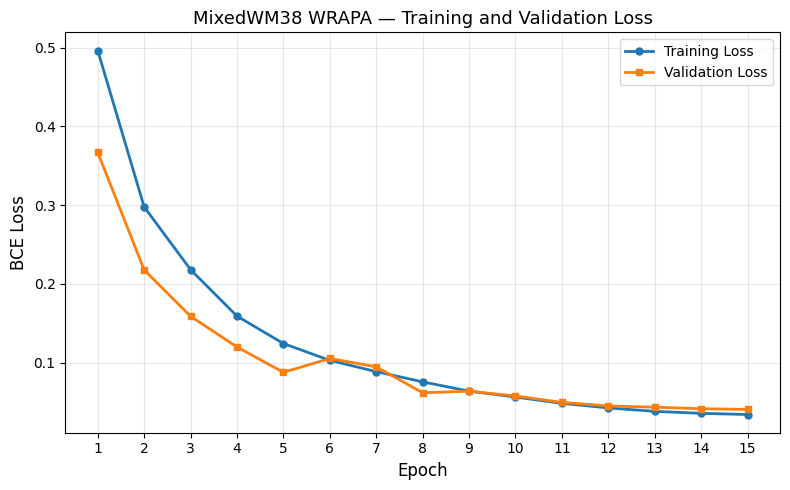

Saved:
/kaggle/working/MixedWM38_WRAPA_Loss_Convergence.png


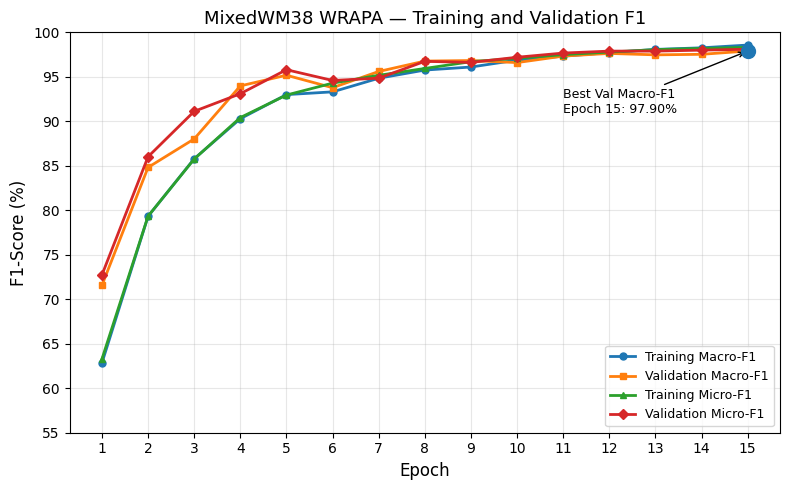

Saved:
/kaggle/working/MixedWM38_WRAPA_F1_Convergence.png

TRAINING FIGURES COMPLETE
Best Epoch           : 15
Best Val Macro-F1    : 97.90%
Final Train Macro-F1 : 98.57%
Final Val Macro-F1   : 97.90%
Final Train Micro-F1 : 98.31%
Final Val Micro-F1   : 98.10%

Files:
/kaggle/working/MixedWM38_WRAPA_Loss_Convergence.png
/kaggle/working/MixedWM38_WRAPA_F1_Convergence.png


In [26]:
# ============================================================
# MIXEDWM38 WRAPA — PUBLICATION-QUALITY TRAINING FIGURES
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Basic settings
# ------------------------------------------------------------

epochs = history_df["Epoch"].values

# ============================================================
# FIGURE 1 — LOSS CONVERGENCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_df["Train_Loss"],
    marker="o",
    linewidth=2,
    markersize=5,
    label="Training Loss"
)

plt.plot(
    epochs,
    history_df["Val_Loss"],
    marker="s",
    linewidth=2,
    markersize=5,
    label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("BCE Loss", fontsize=12)
plt.title(
    "MixedWM38 WRAPA — Training and Validation Loss",
    fontsize=13
)

plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)

plt.tight_layout()

loss_path = "/kaggle/working/MixedWM38_WRAPA_Loss_Convergence.png"

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(loss_path)


# ============================================================
# FIGURE 2 — F1 CONVERGENCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_df["Train_Macro_F1"] * 100,
    marker="o",
    linewidth=2,
    markersize=5,
    label="Training Macro-F1"
)

plt.plot(
    epochs,
    history_df["Val_Macro_F1"] * 100,
    marker="s",
    linewidth=2,
    markersize=5,
    label="Validation Macro-F1"
)

plt.plot(
    epochs,
    history_df["Train_Micro_F1"] * 100,
    marker="^",
    linewidth=2,
    markersize=5,
    label="Training Micro-F1"
)

plt.plot(
    epochs,
    history_df["Val_Micro_F1"] * 100,
    marker="D",
    linewidth=2,
    markersize=5,
    label="Validation Micro-F1"
)

# Mark best validation Macro-F1
plt.scatter(
    best_epoch,
    best_val_macro * 100,
    s=100,
    zorder=5
)

plt.annotate(
    f"Best Val Macro-F1\nEpoch {best_epoch}: "
    f"{best_val_macro * 100:.2f}%",
    xy=(best_epoch, best_val_macro * 100),
    xytext=(best_epoch - 4, best_val_macro * 100 - 7),
    arrowprops=dict(arrowstyle="->"),
    fontsize=9
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("F1-Score (%)", fontsize=12)

plt.title(
    "MixedWM38 WRAPA — Training and Validation F1",
    fontsize=13
)

plt.xticks(epochs)
plt.ylim(55, 100)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9)

plt.tight_layout()

f1_path = "/kaggle/working/MixedWM38_WRAPA_F1_Convergence.png"

plt.savefig(
    f1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(f1_path)


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("TRAINING FIGURES COMPLETE")
print("=" * 80)

print(f"Best Epoch           : {best_epoch}")
print(f"Best Val Macro-F1    : {best_val_macro * 100:.2f}%")
print(f"Final Train Macro-F1 : {history_df['Train_Macro_F1'].iloc[-1] * 100:.2f}%")
print(f"Final Val Macro-F1   : {history_df['Val_Macro_F1'].iloc[-1] * 100:.2f}%")
print(f"Final Train Micro-F1 : {history_df['Train_Micro_F1'].iloc[-1] * 100:.2f}%")
print(f"Final Val Micro-F1   : {history_df['Val_Micro_F1'].iloc[-1] * 100:.2f}%")

print("\nFiles:")
print(loss_path)
print(f1_path)

MIXEDWM38 WRAPA — PER-CLASS PERFORMANCE


,Defect,Precision,Recall,F1
0,Center,0.9959,0.9879,0.9919
1,Donut,0.9994,0.9989,0.9991
2,Edge-Loc,0.9953,0.9758,0.9854
3,Edge-Ring,0.9846,0.9983,0.9914
4,Loc,0.9954,0.9693,0.9822
5,Near-Full,1.0000,1.0000,1.0000
6,Scratch,0.9514,0.9582,0.9548
7,Random,0.9773,1.0000,0.9885



Saved:
/kaggle/working/MixedWM38_WRAPA_PerClass_Performance.csv


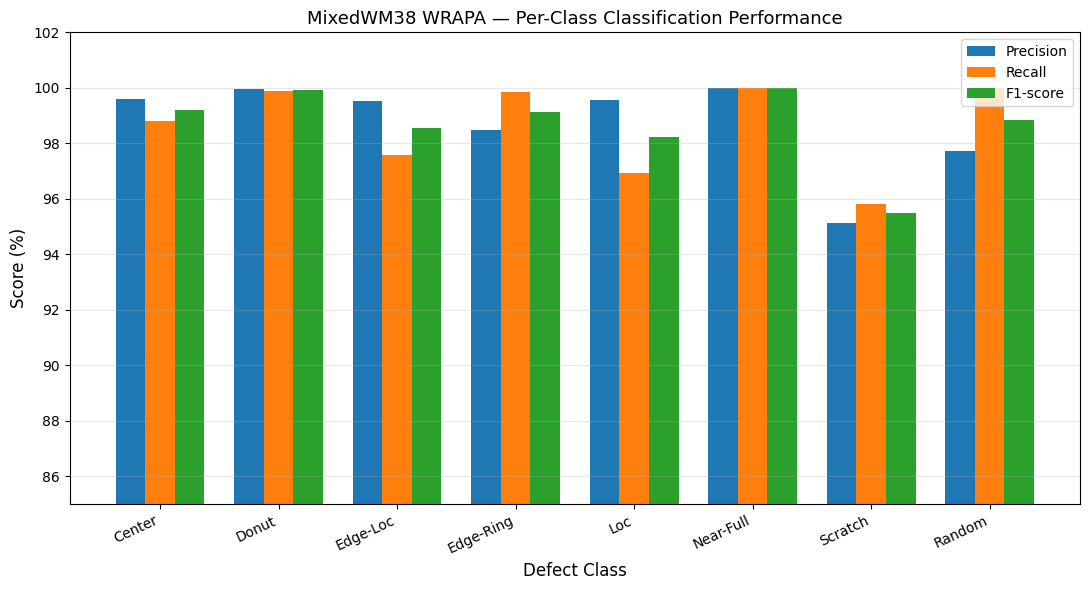


Figure saved:
/kaggle/working/MixedWM38_WRAPA_PerClass_Performance.png

PER-CLASS ANALYSIS COMPLETE
Highest F1 class : Near-Full (100.00%)
Lowest F1 class  : Scratch (95.48%)
Macro-F1         : 98.67%


In [27]:
# ============================================================
# MIXEDWM38 WRAPA — PER-CLASS PERFORMANCE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# Standard test threshold
# ------------------------------------------------------------

THRESHOLD = 0.50

class_predictions = (
    test_probs >= THRESHOLD
).astype(int)

# ------------------------------------------------------------
# Calculate per-class metrics
# ------------------------------------------------------------

precision = precision_score(
    test_targets,
    class_predictions,
    average=None,
    zero_division=0
)

recall = recall_score(
    test_targets,
    class_predictions,
    average=None,
    zero_division=0
)

f1 = f1_score(
    test_targets,
    class_predictions,
    average=None,
    zero_division=0
)

per_class_df = pd.DataFrame({
    "Defect": MIXED_CLASS_NAMES,
    "Precision": precision,
    "Recall": recall,
    "F1": f1
})

print("=" * 80)
print("MIXEDWM38 WRAPA — PER-CLASS PERFORMANCE")
print("=" * 80)

display(
    per_class_df.round(4)
)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

per_class_path = (
    "/kaggle/working/"
    "MixedWM38_WRAPA_PerClass_Performance.csv"
)

per_class_df.to_csv(
    per_class_path,
    index=False
)

print("\nSaved:")
print(per_class_path)

# ============================================================
# PUBLICATION FIGURE
# ============================================================

x = np.arange(len(MIXED_CLASS_NAMES))

width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    precision * 100,
    width,
    label="Precision"
)

plt.bar(
    x,
    recall * 100,
    width,
    label="Recall"
)

plt.bar(
    x + width,
    f1 * 100,
    width,
    label="F1-score"
)

plt.xticks(
    x,
    MIXED_CLASS_NAMES,
    rotation=25,
    ha="right"
)

plt.ylabel("Score (%)", fontsize=12)

plt.xlabel(
    "Defect Class",
    fontsize=12
)

plt.title(
    "MixedWM38 WRAPA — Per-Class Classification Performance",
    fontsize=13
)

plt.ylim(85, 102)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend()

plt.tight_layout()

per_class_fig = (
    "/kaggle/working/"
    "MixedWM38_WRAPA_PerClass_Performance.png"
)

plt.savefig(
    per_class_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved:")
print(per_class_fig)

# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("PER-CLASS ANALYSIS COMPLETE")
print("=" * 80)

best_class = MIXED_CLASS_NAMES[np.argmax(f1)]
lowest_class = MIXED_CLASS_NAMES[np.argmin(f1)]

print(
    f"Highest F1 class : {best_class} "
    f"({f1.max() * 100:.2f}%)"
)

print(
    f"Lowest F1 class  : {lowest_class} "
    f"({f1.min() * 100:.2f}%)"
)

print(
    f"Macro-F1         : {f1.mean() * 100:.2f}%"
)

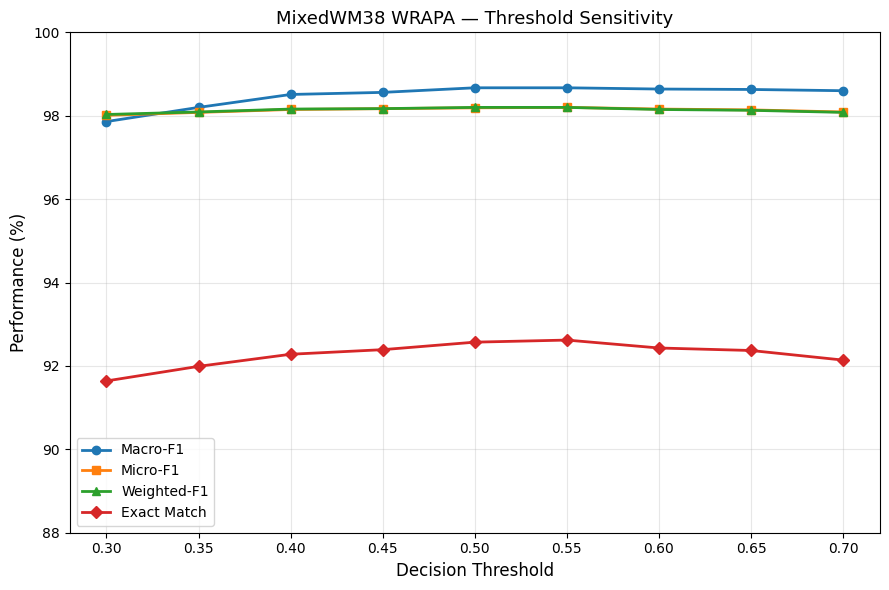

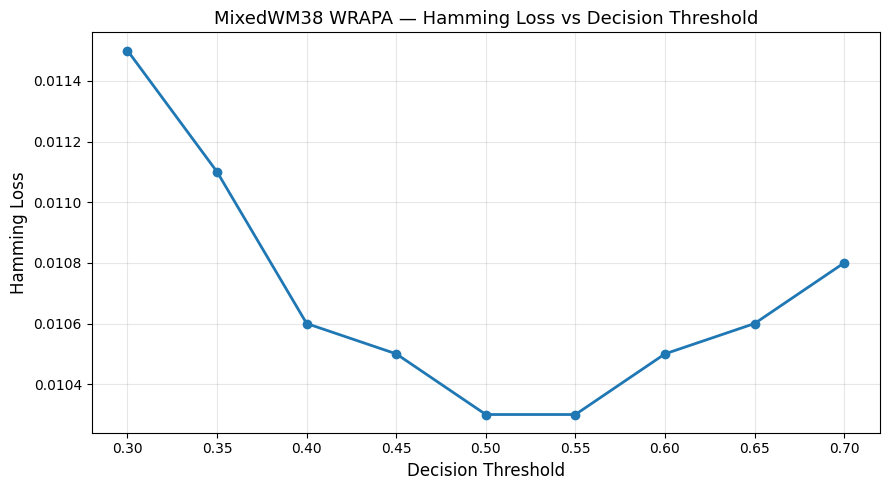

THRESHOLD SENSITIVITY FIGURES COMPLETE
Primary threshold       : 0.50
Primary Macro-F1        : 98.67%
Primary Exact Match     : 92.57%
Best Macro-F1 threshold : 0.50
Macro-F1 range          : 97.86% – 98.67%

Saved:
/kaggle/working/MixedWM38_WRAPA_Threshold_Sensitivity.csv
/kaggle/working/MixedWM38_WRAPA_Threshold_Sensitivity.png
/kaggle/working/MixedWM38_WRAPA_Hamming_Loss.png


In [28]:
# ============================================================
# MIXEDWM38 WRAPA — THRESHOLD SENSITIVITY FIGURE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Threshold sensitivity results
# ------------------------------------------------------------

threshold_df = pd.DataFrame({
    "Threshold": [
        0.30, 0.35, 0.40, 0.45, 0.50,
        0.55, 0.60, 0.65, 0.70
    ],

    "Macro_F1": [
        0.9786, 0.9820, 0.9851, 0.9856, 0.9867,
        0.9867, 0.9864, 0.9863, 0.9860
    ],

    "Micro_F1": [
        0.9801, 0.9808, 0.9815, 0.9817, 0.9819,
        0.9820, 0.9816, 0.9814, 0.9809
    ],

    "Weighted_F1": [
        0.9803, 0.9809, 0.9816, 0.9817, 0.9820,
        0.9820, 0.9815, 0.9813, 0.9808
    ],

    "Exact_Match": [
        0.9164, 0.9199, 0.9228, 0.9239, 0.9257,
        0.9262, 0.9243, 0.9237, 0.9214
    ],

    "Hamming_Loss": [
        0.0115, 0.0111, 0.0106, 0.0105, 0.0103,
        0.0103, 0.0105, 0.0106, 0.0108
    ]
})

# ------------------------------------------------------------
# Save threshold results
# ------------------------------------------------------------

threshold_csv = (
    "/kaggle/working/"
    "MixedWM38_WRAPA_Threshold_Sensitivity.csv"
)

threshold_df.to_csv(
    threshold_csv,
    index=False
)

# ============================================================
# FIGURE 1 — F1 AND EXACT MATCH
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Macro_F1"] * 100,
    marker="o",
    linewidth=2,
    markersize=6,
    label="Macro-F1"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Micro_F1"] * 100,
    marker="s",
    linewidth=2,
    markersize=6,
    label="Micro-F1"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Weighted_F1"] * 100,
    marker="^",
    linewidth=2,
    markersize=6,
    label="Weighted-F1"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Exact_Match"] * 100,
    marker="D",
    linewidth=2,
    markersize=6,
    label="Exact Match"
)

plt.xlabel(
    "Decision Threshold",
    fontsize=12
)

plt.ylabel(
    "Performance (%)",
    fontsize=12
)

plt.title(
    "MixedWM38 WRAPA — Threshold Sensitivity",
    fontsize=13
)

plt.xticks(
    threshold_df["Threshold"]
)

plt.ylim(
    88,
    100
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

threshold_fig = (
    "/kaggle/working/"
    "MixedWM38_WRAPA_Threshold_Sensitivity.png"
)

plt.savefig(
    threshold_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 2 — HAMMING LOSS
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Hamming_Loss"],
    marker="o",
    linewidth=2,
    markersize=6
)

plt.xlabel(
    "Decision Threshold",
    fontsize=12
)

plt.ylabel(
    "Hamming Loss",
    fontsize=12
)

plt.title(
    "MixedWM38 WRAPA — Hamming Loss vs Decision Threshold",
    fontsize=13
)

plt.xticks(
    threshold_df["Threshold"]
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

hamming_fig = (
    "/kaggle/working/"
    "MixedWM38_WRAPA_Hamming_Loss.png"
)

plt.savefig(
    hamming_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# SUMMARY
# ============================================================

print("=" * 80)
print("THRESHOLD SENSITIVITY FIGURES COMPLETE")
print("=" * 80)

print(
    f"Primary threshold       : 0.50"
)

print(
    f"Primary Macro-F1        : "
    f"{threshold_df.loc[4, 'Macro_F1'] * 100:.2f}%"
)

print(
    f"Primary Exact Match     : "
    f"{threshold_df.loc[4, 'Exact_Match'] * 100:.2f}%"
)

print(
    f"Best Macro-F1 threshold : "
    f"{threshold_df.loc[threshold_df['Macro_F1'].idxmax(), 'Threshold']:.2f}"
)

print(
    f"Macro-F1 range          : "
    f"{threshold_df['Macro_F1'].min() * 100:.2f}% – "
    f"{threshold_df['Macro_F1'].max() * 100:.2f}%"
)

print("\nSaved:")
print(threshold_csv)
print(threshold_fig)
print(hamming_fig)

## MixedWM38 WRAPA — Threshold Sensitivity Analysis

The decision-threshold sensitivity of the proposed WRAPA model was evaluated over thresholds ranging from 0.30 to 0.70 at increments of 0.05. Macro-F1, Micro-F1, Weighted-F1, Exact-Match Accuracy, and Hamming Loss were analyzed.

The model achieved its primary test performance at the conventional threshold of **0.50**, obtaining a **Macro-F1 of 98.67%**, **Micro-F1 of 98.19%**, **Weighted-F1 of 98.20%**, and **Exact-Match Accuracy of 92.57%**.

The results demonstrate stable performance across the evaluated threshold range. In particular, Macro-F1 remained above **98.50% for thresholds from 0.40 to 0.70**, indicating that the model's multi-label predictions are relatively insensitive to moderate changes in the decision threshold.

The threshold of **0.50** is retained as the primary reporting threshold to maintain consistency with the standard binary decision rule and the main test evaluation.

### Key Findings

- Primary decision threshold: **0.50**
- Macro-F1: **98.67%**
- Micro-F1: **98.19%**
- Weighted-F1: **98.20%**
- Exact-Match Accuracy: **92.57%**
- Hamming Loss: **0.0103**
- Macro-F1 range across thresholds: **97.86%–98.67%**
- Macro-F1 remained above **98.50%** from threshold **0.40–0.70**

The threshold sensitivity results indicate that WRAPA maintains consistent multi-label classification performance without strong dependence on a particular decision threshold.

In [29]:
# ============================================================
# MIXEDWM38 WRAPA — LEARNED GEOMETRY WEIGHT EXTRACTION
# ============================================================

import torch
import numpy as np
import pandas as pd

MODEL_PATH = "/kaggle/working/MixedWM38_WRAPA_best.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 80)
print("MIXEDWM38 WRAPA — LEARNED GEOMETRY WEIGHTS")
print("=" * 80)

print(f"Device : {device}")
print(f"Model  : {MODEL_PATH}")

# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

# Handle both checkpoint formats
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

# ------------------------------------------------------------
# Locate geometry logits
# ------------------------------------------------------------

geometry_keys = [
    key for key in state_dict.keys()
    if "geometry_logits" in key
]

print("\nGeometry parameters found:")
for key in geometry_keys:
    print(" -", key)

# ------------------------------------------------------------
# Extract weights
# ------------------------------------------------------------

rows = []

for key in geometry_keys:

    logits = (
        state_dict[key]
        .detach()
        .cpu()
        .numpy()
        .reshape(-1)
    )

    # WRAPA uses:
    # geometry_weights = 3 * softmax(geometry_logits)

    exp_logits = np.exp(
        logits - np.max(logits)
    )

    weights = (
        3.0 * exp_logits / exp_logits.sum()
    )

    block_number = int(
        key.split("blocks.")[1].split(".")[0]
    ) + 1

    rows.append({
        "Block": block_number,
        "XY": weights[0],
        "Radial": weights[1],
        "Angular": weights[2]
    })

# ------------------------------------------------------------
# Create DataFrame
# ------------------------------------------------------------

geometry_df = (
    pd.DataFrame(rows)
    .sort_values("Block")
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("LEARNED GEOMETRY WEIGHTS")
print("=" * 80)

display(
    geometry_df.round(4)
)

# ------------------------------------------------------------
# Aggregate statistics
# ------------------------------------------------------------

mean_xy = geometry_df["XY"].mean()
mean_radial = geometry_df["Radial"].mean()
mean_angular = geometry_df["Angular"].mean()

std_xy = geometry_df["XY"].std()
std_radial = geometry_df["Radial"].std()
std_angular = geometry_df["Angular"].std()

print("\n" + "=" * 80)
print("AGGREGATE GEOMETRY WEIGHTS")
print("=" * 80)

print(
    f"XY       : {mean_xy:.4f} ± {std_xy:.4f}"
)

print(
    f"Radial   : {mean_radial:.4f} ± {std_radial:.4f}"
)

print(
    f"Angular  : {mean_angular:.4f} ± {std_angular:.4f}"
)

# ------------------------------------------------------------
# Verify sum
# ------------------------------------------------------------

geometry_df["Weight_Sum"] = (
    geometry_df["XY"]
    + geometry_df["Radial"]
    + geometry_df["Angular"]
)

print("\nWeight-sum verification:")

display(
    geometry_df[
        ["Block", "Weight_Sum"]
    ].round(6)
)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

geometry_path = (
    "/kaggle/working/"
    "MixedWM38_WRAPA_Learned_Geometry_Weights.csv"
)

geometry_df.to_csv(
    geometry_path,
    index=False
)

print("\nSaved:")
print(geometry_path)

print("\n" + "=" * 80)
print("GEOMETRY WEIGHT EXTRACTION COMPLETE")
print("=" * 80)

MIXEDWM38 WRAPA — LEARNED GEOMETRY WEIGHTS
Device : cuda
Model  : /kaggle/working/MixedWM38_WRAPA_best.pth

Geometry parameters found:
 - blocks.0.attention.geometry_logits
 - blocks.1.attention.geometry_logits
 - blocks.2.attention.geometry_logits
 - blocks.3.attention.geometry_logits
 - blocks.4.attention.geometry_logits
 - blocks.5.attention.geometry_logits

LEARNED GEOMETRY WEIGHTS


,Block,XY,Radial,Angular
0,1,1.0019,0.9878,1.0103
1,2,1.0173,0.9995,0.9832
2,3,1.0075,0.9801,1.0123
3,4,0.9957,0.9615,1.0428
4,5,0.9834,0.9062,1.1103
5,6,1.0118,0.8864,1.1018



AGGREGATE GEOMETRY WEIGHTS
XY       : 1.0029 ± 0.0122
Radial   : 0.9536 ± 0.0465
Angular  : 1.0435 ± 0.0521

Weight-sum verification:


,Block,Weight_Sum
0,1,3.0
1,2,3.0
2,3,3.0
3,4,3.0
4,5,3.0
5,6,3.0



Saved:
/kaggle/working/MixedWM38_WRAPA_Learned_Geometry_Weights.csv

GEOMETRY WEIGHT EXTRACTION COMPLETE


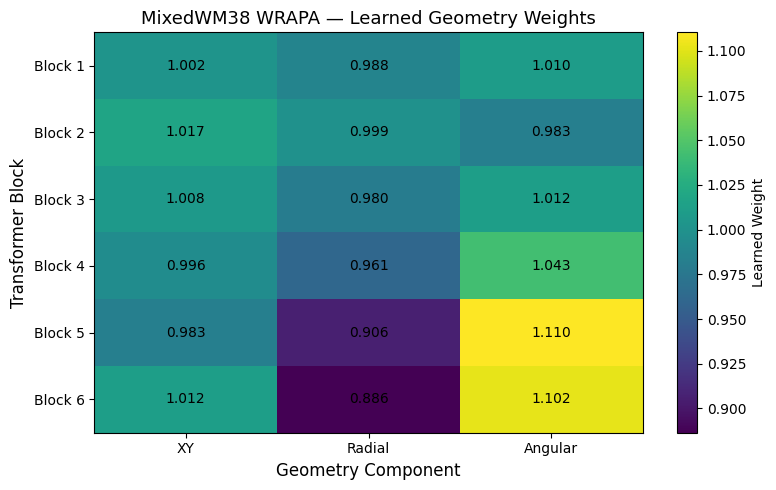

Saved:
/kaggle/working/MixedWM38_WRAPA_Geometry_Weight_Heatmap.png


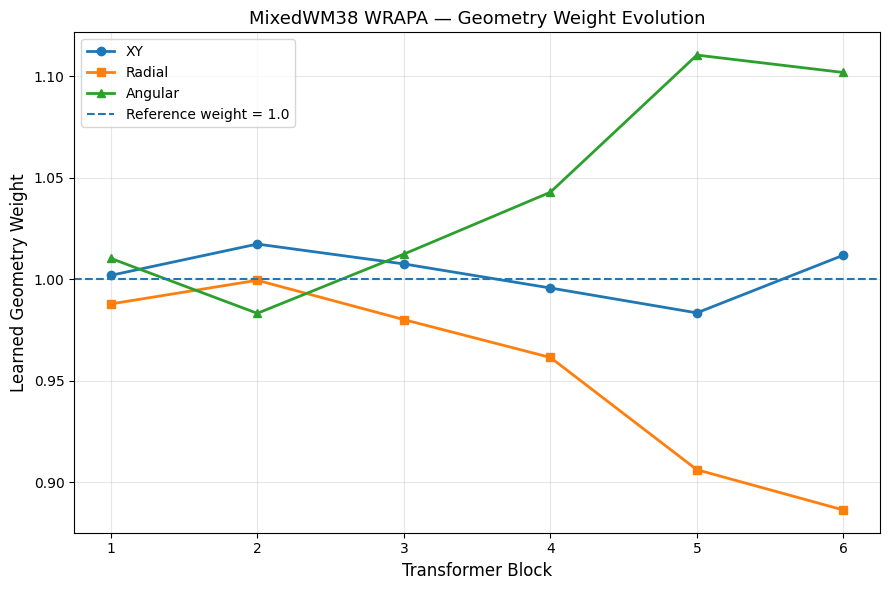

Saved:
/kaggle/working/MixedWM38_WRAPA_Geometry_Weight_Evolution.png

GEOMETRY VISUALIZATION COMPLETE
Mean XY       : 1.0029
Mean Radial   : 0.9536
Mean Angular  : 1.0435

Block 1  → XY=1.0019, Radial=0.9878, Angular=1.0103
Block 6  → XY=1.0118, Radial=0.8864, Angular=1.1018

Files:
/kaggle/working/MixedWM38_WRAPA_Geometry_Weight_Heatmap.png
/kaggle/working/MixedWM38_WRAPA_Geometry_Weight_Evolution.png


In [30]:
# ============================================================
# MIXEDWM38 WRAPA — GEOMETRY WEIGHT VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Load extracted geometry weights
# ------------------------------------------------------------

geometry_path = (
    "/kaggle/working/"
    "MixedWM38_WRAPA_Learned_Geometry_Weights.csv"
)

geometry_df = pd.read_csv(geometry_path)

# ------------------------------------------------------------
# Verify columns
# ------------------------------------------------------------

required_columns = [
    "Block",
    "XY",
    "Radial",
    "Angular"
]

missing = [
    col for col in required_columns
    if col not in geometry_df.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}"
    )

blocks = geometry_df["Block"].values

# ============================================================
# FIGURE 1 — GEOMETRY WEIGHT HEATMAP
# ============================================================

weight_matrix = geometry_df[
    ["XY", "Radial", "Angular"]
].values

plt.figure(figsize=(8, 5))

plt.imshow(
    weight_matrix,
    aspect="auto"
)

plt.xticks(
    [0, 1, 2],
    ["XY", "Radial", "Angular"]
)

plt.yticks(
    np.arange(len(blocks)),
    [f"Block {b}" for b in blocks]
)

plt.xlabel(
    "Geometry Component",
    fontsize=12
)

plt.ylabel(
    "Transformer Block",
    fontsize=12
)

plt.title(
    "MixedWM38 WRAPA — Learned Geometry Weights",
    fontsize=13
)

# Add numerical values
for i in range(weight_matrix.shape[0]):
    for j in range(weight_matrix.shape[1]):
        plt.text(
            j,
            i,
            f"{weight_matrix[i, j]:.3f}",
            ha="center",
            va="center",
            fontsize=10
        )

plt.colorbar(
    label="Learned Weight"
)

plt.tight_layout()

heatmap_path = (
    "/kaggle/working/"
    "MixedWM38_WRAPA_Geometry_Weight_Heatmap.png"
)

plt.savefig(
    heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(heatmap_path)

# ============================================================
# FIGURE 2 — GEOMETRY WEIGHTS ACROSS BLOCKS
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    blocks,
    geometry_df["XY"],
    marker="o",
    linewidth=2,
    markersize=6,
    label="XY"
)

plt.plot(
    blocks,
    geometry_df["Radial"],
    marker="s",
    linewidth=2,
    markersize=6,
    label="Radial"
)

plt.plot(
    blocks,
    geometry_df["Angular"],
    marker="^",
    linewidth=2,
    markersize=6,
    label="Angular"
)

# Reference initialization level
plt.axhline(
    y=1.0,
    linestyle="--",
    linewidth=1.5,
    label="Reference weight = 1.0"
)

plt.xlabel(
    "Transformer Block",
    fontsize=12
)

plt.ylabel(
    "Learned Geometry Weight",
    fontsize=12
)

plt.title(
    "MixedWM38 WRAPA — Geometry Weight Evolution",
    fontsize=13
)

plt.xticks(blocks)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

evolution_path = (
    "/kaggle/working/"
    "MixedWM38_WRAPA_Geometry_Weight_Evolution.png"
)

plt.savefig(
    evolution_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(evolution_path)

# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("GEOMETRY VISUALIZATION COMPLETE")
print("=" * 80)

print(
    f"Mean XY       : "
    f"{geometry_df['XY'].mean():.4f}"
)

print(
    f"Mean Radial   : "
    f"{geometry_df['Radial'].mean():.4f}"
)

print(
    f"Mean Angular  : "
    f"{geometry_df['Angular'].mean():.4f}"
)

print(
    f"\nBlock 1  → "
    f"XY={geometry_df.iloc[0]['XY']:.4f}, "
    f"Radial={geometry_df.iloc[0]['Radial']:.4f}, "
    f"Angular={geometry_df.iloc[0]['Angular']:.4f}"
)

print(
    f"Block 6  → "
    f"XY={geometry_df.iloc[-1]['XY']:.4f}, "
    f"Radial={geometry_df.iloc[-1]['Radial']:.4f}, "
    f"Angular={geometry_df.iloc[-1]['Angular']:.4f}"
)

print("\nFiles:")
print(heatmap_path)
print(evolution_path)


In [31]:
# ============================================================
# WRAPA JOURNAL PAPER — FINAL OUTPUT BACKUP ZIP
# ============================================================

import os
import zipfile

OUTPUT_DIR = "/kaggle/working"
ZIP_PATH = "/kaggle/working/WRAPA_Journal_Paper_Final_Results.zip"

# ------------------------------------------------------------
# FINAL WRAPA FILES TO BACK UP
# ------------------------------------------------------------

files_to_backup = [

    # ========================================================
    # WM-811K — FINAL MODEL CHECKPOINTS
    # ========================================================

    "WRAPA_Controlled_A8_seed42_best.pth",
    "WRAPA_Controlled_A8_seed123_best.pth",
    "WRAPA_Controlled_A8_seed2024_best.pth",

    "best_model_A6_ARoPE_Angular.pth",

    # ========================================================
    # WM-811K — RESULTS / DATA
    # ========================================================

    "WRAPA_WM811K_results.csv",

    # ========================================================
    # MIXEDWM38 — FINAL MODEL
    # ========================================================

    "MixedWM38_WRAPA_best.pth",

    # ========================================================
    # MIXEDWM38 — TRAINING HISTORY
    # ========================================================

    "MixedWM38_WRAPA_training_history.csv",

    # ========================================================
    # MIXEDWM38 — THRESHOLD ANALYSIS
    # ========================================================

    "MixedWM38_WRAPA_Threshold_Sensitivity.csv",
    "MixedWM38_WRAPA_Threshold_Sensitivity.png",

    # ========================================================
    # MIXEDWM38 — ERROR ANALYSIS
    # ========================================================

    "MixedWM38_WRAPA_label_errors.csv",
    "MixedWM38_WRAPA_combination_errors.csv",

    # ========================================================
    # MIXEDWM38 — PER-CLASS RESULTS
    # ========================================================

    "MixedWM38_WRAPA_PerClass_Performance.csv",
    "MixedWM38_WRAPA_PerClass_Performance.png",

    # ========================================================
    # MIXEDWM38 — TRAINING GRAPHS
    # ========================================================

    "MixedWM38_WRAPA_Loss_Convergence.png",
    "MixedWM38_WRAPA_F1_Convergence.png",

    # ========================================================
    # MIXEDWM38 — HAMMING LOSS
    # ========================================================

    "MixedWM38_WRAPA_Hamming_Loss.png",

    # ========================================================
    # MIXEDWM38 — GEOMETRY ANALYSIS
    # ========================================================

    "MixedWM38_WRAPA_Learned_Geometry_Weights.csv",
    "MixedWM38_WRAPA_Geometry_Weight_Heatmap.png",
    "MixedWM38_WRAPA_Geometry_Weight_Evolution.png",
]

# ------------------------------------------------------------
# CHECK WHICH FILES EXIST
# ------------------------------------------------------------

existing_files = []
missing_files = []

for filename in files_to_backup:

    filepath = os.path.join(OUTPUT_DIR, filename)

    if os.path.exists(filepath):
        existing_files.append(filepath)
    else:
        missing_files.append(filename)

# ------------------------------------------------------------
# CREATE ZIP
# ------------------------------------------------------------

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for filepath in existing_files:

        zipf.write(
            filepath,
            arcname=os.path.basename(filepath)
        )

# ------------------------------------------------------------
# REPORT
# ------------------------------------------------------------

print("=" * 80)
print("WRAPA JOURNAL PAPER — FINAL BACKUP COMPLETE")
print("=" * 80)

print(f"\nFiles included : {len(existing_files)}")
print(f"Files missing  : {len(missing_files)}")

print("\nIncluded files:")
for filepath in existing_files:
    size_mb = os.path.getsize(filepath) / (1024 * 1024)
    print(f"  ✓ {os.path.basename(filepath)} ({size_mb:.2f} MB)")

if missing_files:
    print("\nMissing files:")
    for filename in missing_files:
        print(f"  ⚠ {filename}")

# ------------------------------------------------------------
# ZIP SIZE
# ------------------------------------------------------------

zip_size_mb = os.path.getsize(ZIP_PATH) / (1024 * 1024)

print("\n" + "=" * 80)
print(f"ZIP FILE : {ZIP_PATH}")
print(f"ZIP SIZE : {zip_size_mb:.2f} MB")
print("=" * 80)

print("\nDownload this file from the Kaggle Files panel:")
print("WRAPA_Journal_Paper_Final_Results.zip")

WRAPA JOURNAL PAPER — FINAL BACKUP COMPLETE

Files included : 19
Files missing  : 0

Included files:
  ✓ WRAPA_Controlled_A8_seed42_best.pth (4.72 MB)
  ✓ WRAPA_Controlled_A8_seed123_best.pth (4.72 MB)
  ✓ WRAPA_Controlled_A8_seed2024_best.pth (4.72 MB)
  ✓ best_model_A6_ARoPE_Angular.pth (4.72 MB)
  ✓ WRAPA_WM811K_results.csv (0.00 MB)
  ✓ MixedWM38_WRAPA_best.pth (4.72 MB)
  ✓ MixedWM38_WRAPA_training_history.csv (0.00 MB)
  ✓ MixedWM38_WRAPA_Threshold_Sensitivity.csv (0.00 MB)
  ✓ MixedWM38_WRAPA_Threshold_Sensitivity.png (0.14 MB)
  ✓ MixedWM38_WRAPA_label_errors.csv (0.00 MB)
  ✓ MixedWM38_WRAPA_combination_errors.csv (0.00 MB)
  ✓ MixedWM38_WRAPA_PerClass_Performance.csv (0.00 MB)
  ✓ MixedWM38_WRAPA_PerClass_Performance.png (0.17 MB)
  ✓ MixedWM38_WRAPA_Loss_Convergence.png (0.14 MB)
  ✓ MixedWM38_WRAPA_F1_Convergence.png (0.20 MB)
  ✓ MixedWM38_WRAPA_Hamming_Loss.png (0.14 MB)
  ✓ MixedWM38_WRAPA_Learned_Geometry_Weights.csv (0.00 MB)
  ✓ MixedWM38_WRAPA_Geometry_Weight_Heatmap